# Phase 5 - Hypothesis testing: ten questions, tested honestly

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis (Atlantic Recording Corporation case)

**What this notebook does.** Phase 4 ended with ten questions that the pictures suggested (H1 to H10). This notebook tests all ten on the cleaned chart (27,750 song-days, 944 songs, 243 artists, 18 May 2024 to 27 November 2025). For every question it runs the test that was planned in Phase 4, and then the test that is allowed to decide, because it respects the fact that songs of one artist, and days next to each other, are not independent pieces of evidence. It reports how big each effect is (not only whether it is "significant"), corrects for asking ten questions at once, and ends with two stress tests: every claim again in each half of the period, and again without the artist who has the most songs.

**Before you run it.** Phases 1 to 4 must have run, so that `data/processed/` holds the Parquet tables and `reports/p4_facts.json` exists (the notebook checks that it can reproduce the Phase 4 numbers). Then restart the kernel and choose *Run All*. It takes about a minute, writes 17 charts to `reports/figures/p5_*.png`, and writes three small files to `reports/`: `p5_facts.json` (every number quoted in the text), `p5_hypothesis_register.csv` (one row per hypothesis) and `p5_robustness.csv` (the two stress tests). Always restart the kernel before running again: the container of numbers refuses to store the same name twice, which is how we know that no number is silently replaced.

**How to read it.** Every code cell has a short plain-English explanation above it in five parts: *what this code is*, *why we need it*, *what will happen*, *expected outcome* and *motive*. Every chart has a *What to notice* note below it. The numbers in those notes are not typed by hand: the code cell stores each number it computes in `FACTS`, and the sentences are written from it.

**Ground rules used throughout.**

- *The primary test decides.* Each hypothesis has a *planned test* (the one named in Phase 4, which treats every row as independent) and a *primary test* that allows for related rows. Both are shown; the verdict uses the primary one.
- *Effect sizes come first.* A small p-value says that an effect is probably not zero. It does not say that the effect is big. Every claim is given with its size, in its own unit, with a 95% interval.
- *Ten questions, one correction.* With ten tests and a 5% false-alarm rate each, the chance of at least one false alarm is about 40%. The ten primary p-values are therefore corrected together (Holm's method, with Benjamini-Hochberg shown beside it).
- *The verdicts.* **Supported**: still significant after the correction. **Suggestive**: significant on its own but not after the correction (a lead for new data). **Not supported**: not significant, which is not the same as showing that there is no effect (the power checks say what could have been found).
- *The questions came from this same data.* They were chosen after looking at the data in Phase 4, so the p-values here are somewhat optimistic: they say that chance alone is an unlikely explanation, not that a new chart year would repeat the pattern. Section 15 is the partial answer: it checks each claim in the two halves of the period separately.
- *Weekdays are as recorded.* The calendar of the file appears to run about a year ahead of real release dates, so weekday patterns describe the file, not real release days.

| Section | What it does | Figures |
|---|---|---|
| 1 | Setup and loading | - |
| 2 | The plan: ten questions, planned test and primary test | - |
| 3 | Why the planned tests cannot decide alone: dependence and a placebo experiment | 1-2 |
| 4 | H1: explicit songs and the top 10 | 3 |
| 5 | H9: collaborations and the top 10 | 4 |
| 6 | H2: singles against album tracks | 5 |
| 7 | H10: explicit songs, singles and album tracks | 6 |
| 8 | H3: popularity in the three tiers | 7-8 |
| 9 | H4: the trend of average popularity | 9 |
| 10 | H5: entry position and run length | 10 |
| 11 | H6: first-time entries by weekday | 11 |
| 12 | H7: song length and the top 10 | 12 |
| 13 | H8: concentration by month | 13 |
| 14 | All ten together: register, corrections and verdicts | 14-15 |
| 15 | Do the claims hold up? Two halves, and without the biggest artist | 16-17 |
| 16 | Saving the results | - |

## Section 1 - Setup and loading the data

Two cells. The first loads the tools, the second loads the tables that Phase 3 wrote to `data/processed/` and builds the song table and the run table that the tests use. Nothing is cleaned or changed here: all cleaning decisions were made in Phase 2 and are already inside the tables.

**What this code is.** The import cell. It loads the Python libraries (pandas for tables, numpy for numbers, matplotlib for charts, scipy for statistics) and our own modules: `src/inference` (the statistical tests of Phase 5: classical tests, tests that allow for related rows, power, survival curves, corrections for many tests and the register of hypotheses) and the Phase 4 helpers for colours, chart building blocks, concentration measures and chart runs.

**Why we need it.** Everything below uses these names. The logic that matters (how a wild bootstrap is done, how Holm's correction works, how a verdict is decided) lives in `src/inference` and is covered by automated tests, so the notebook stays short and the formulas stay checked. The two path lines make `from src...` work whether Jupyter was started in the project folder or in the `notebooks` folder.

**What will happen.** Python imports the libraries, switches on the project look, and creates two containers: `FACTS`, where every number that appears in a sentence is stored once (it refuses to store a name twice and refuses numbers that are not finite), and `REGISTER`, the table of the ten hypotheses. It sets four constants for the whole notebook: the significance level (0.05), the confidence level (95%), the number of bootstrap repeats (10,000) and the random seed. The seed is the first day of the chart file, so every random choice starts from the same place and the notebook gives the same numbers every time.

**Expected outcome.** Four printed lines (pandas, numpy and scipy versions, and the project folder) and no chart. If a line fails with `ModuleNotFoundError`, run `pip install -r requirements.txt` in the project folder and restart the kernel.

**Motive.** One setup, one look, one seed, one place for the numbers. From here to the end no number in a sentence is typed by hand, and no result depends on luck.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))            # makes "from src..." work when the notebook starts inside the notebooks folder

from src.config import RANK_TIER_LABELS, default_paths
from src.eda import style
from src.eda.concentration import period_concentration, period_shares
from src.eda.findings import Facts
from src.eda.plots import (clean_text, direct_label, make_fig, note, panel_title, percent_formatter, save_fig, short, style_axes,
                           swatch_legend)
from src.eda.ranking import stint_table
from src.inference import classical, dependence, power, survival
from src.inference.multiplicity import adjust, family_wise_false_alarm_chance, holm
from src.inference.register import HypothesisRegister, format_p, save_table, verdict as verdict_rule
from src.inference.results import effect_label

pd.set_option("display.max_columns", 40)             # show up to 40 columns instead of hiding some
pd.set_option("display.width", 200)                  # use a wide print area so that tables do not wrap
pd.set_option("display.float_format", "{:,.4g}".format)

style.apply_style()                                  # the project look: fonts, colours, hairline grid
FACTS = Facts()                                      # every number we quote in a sentence is stored here, once
REGISTER = HypothesisRegister()                      # the register of the ten hypotheses (saved as a CSV file at the end)

ALPHA = 0.05                                         # the significance level: a false alarm rate of 5% per test
CONFIDENCE = 0.95                                    # every confidence interval is a 95% interval
N_BOOT = 10_000                                      # resamples for every bootstrap and permutation
SEED = 20240518                                      # the first day of the chart file: every random choice below starts from it
FACTS["alpha"] = ALPHA
FACTS["n_boot"] = N_BOOT

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("scipy  :", __import__("scipy").__version__)
print("project:", PROJECT_ROOT)

pandas : 2.3.2
numpy  : 2.3.3
scipy  : 1.15.3
project: d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics


**What this code is.** The loading cell. It reads four Parquet tables from `data/processed/` (the song-by-day playlist, the song table, the daily summary and the date table) and builds the tables that the tests run on: `songs` (one row per song, with the flags and measures the hypotheses use, and the song's primary artist as its cluster) and `runs` (one row per chart run, with its artist). It then compares five numbers with `reports/p4_facts.json`.

**Why we need it.** Each hypothesis has its own unit: a song, a chart run, a day, a calendar week or a month. Building the units once, here, means that the same song table is used by H1, H2, H7, H9 and H10. The comparison with Phase 4 guards against the quietest mistake in a project like this: testing a table that differs slightly from the one the pictures were drawn from.

**What will happen.** The code first checks that the four files exist and stops with a clear message if not. It loads them, adds four columns to the song table (single or album, log of the days on the chart, a 1/0 flag for reaching the top 10, and the artist), builds the run table with the Phase 4 function `stint_table`, and stores the counts as facts. Then it recomputes the share of explicit and other songs reaching the top 10, the median days of singles and album tracks and the number of complete runs, and asserts that each agrees with Phase 4 to six decimals.

**Expected outcome.** A six-row table of counts (27,750 song-days, 944 songs, 243 artists, 555 snapshot days, 1,981 chart runs of which 1,881 are complete) and the line *Phase 4 reproduced*. If `p4_facts.json` is missing, the cell says so and skips the comparison.

**Motive.** Phase 5 stands on Phase 4. Starting from numbers that are checked, not assumed, is what lets every later sentence be trusted.

In [2]:
paths = default_paths()
FIG_DIR = paths.reports_dir / "figures"              # all charts of this notebook are saved here as PNG files

needed = ["playlist_daily", "dim_track", "daily_summary", "dim_date"]
missing = [name for name in needed if not (paths.processed_dir / f"{name}.parquet").exists()]
assert not missing, f"Run the pipeline first:  python -m src.etl.run_pipeline   (missing: {missing})"

playlist = pd.read_parquet(paths.processed_dir / "playlist_daily.parquet")        # one row per song per day (27,750 rows)
dim_track = pd.read_parquet(paths.processed_dir / "dim_track.parquet")            # one row per song (944 rows)
daily = pd.read_parquet(paths.processed_dir / "daily_summary.parquet").sort_values("date").reset_index(drop=True)   # one row per snapshot day
dim_date = pd.read_parquet(paths.processed_dir / "dim_date.parquet")              # one row per calendar day

# ---- the song table: one row per song, with the columns that the tests use
songs = dim_track.copy()
songs["is_single"] = songs["release_format"] == "Single"                           # a single, against an album track (compilations count as albums)
songs["log_days"] = np.log(songs["days_on_chart"])                                 # days on chart on a log scale (see Section 5 for why)
songs["top10"] = songs["reached_top10"].astype(float)                              # 1.0 if the song ever reached the top 10, else 0.0
songs["artist"] = songs["primary_artist"]                                          # the cluster: songs of one artist are not independent

# ---- the run table: one row per chart run (a stretch of consecutive days), with the artist of its song
runs = stint_table(playlist).merge(songs[["track_id", "artist"]], on="track_id", how="left")

FACTS["rows"] = len(playlist)
FACTS["songs"] = len(songs)
FACTS["artists"] = songs["artist"].nunique()
FACTS["snapshots"] = len(daily)
FACTS["first_date"], FACTS["last_date"] = f"{daily['date'].min():%d %B %Y}", f"{daily['date'].max():%d %B %Y}"
FACTS["runs"] = len(runs)
FACTS["runs_complete"] = int(runs["complete"].sum())

display(pd.DataFrame({"table": ["playlist (song x day)", "songs", "artists (primary)", "snapshot days", "chart runs", "complete chart runs"],
                      "rows": [len(playlist), len(songs), songs["artist"].nunique(), len(daily), len(runs), int(runs["complete"].sum())]}))

# ---- the numbers of Phase 4 must come out again, otherwise the tests below would test something else
p4_file = paths.reports_dir / "p4_facts.json"
if p4_file.exists():
    p4 = json.loads(p4_file.read_text(encoding="utf-8"))
    explicit = songs.groupby("is_explicit")["top10"].mean() * 100
    singles = songs.groupby("is_single")["days_on_chart"].median()
    checks = {"explicit songs reaching the top 10 (%)": (explicit[True], p4["card_explicit_top10_pct"]),
              "other songs reaching the top 10 (%)": (explicit[False], p4["card_clean_top10_pct"]),
              "median days on chart, singles": (singles[True], p4["card_single_median_days"]),
              "median days on chart, album tracks": (singles[False], p4["card_album_median_days"]),
              "complete runs": (FACTS["runs_complete"], p4["finished_runs"])}
    for label, (now, before) in checks.items():
        assert abs(now - before) < 1e-6, f"{label}: {now} here, {before} in Phase 4. Re-run the pipeline and notebook 04 first."
    print("Phase 4 reproduced: the same song counts, shares, medians and runs.")
else:
    print("reports/p4_facts.json is not there (notebook 04 has not been run): the cross-check with Phase 4 is skipped.")

,table,rows
0,playlist (song x day),27750
1,songs,944
2,artists (primary),243
3,snapshot days,555
4,chart runs,1981
5,complete chart runs,1881


Phase 4 reproduced: the same song counts, shares, medians and runs.


## Section 2 - The plan: ten questions and two kinds of test

Phase 4 ended with ten questions and a planned test for each. Those planned tests are the textbook ones, and they treat every row as an independent piece of evidence. Section 3 shows that this assumption fails here. So each question gets two tests: the **planned test**, kept for the record and for comparison, and the **primary test**, which allows for the artist (or the day, or the week) that rows belong to and is the one that decides. The rules are fixed here, before any result is seen.

**What this code is.** The plan table. One row for each of the ten hypotheses H1 to H10, copied from the hand-off at the end of Phase 4: the question, the unit of analysis, the planned test, the primary test and the way the effect will be measured.

**Why we need it.** Writing the rules down first protects against the easiest way to fool oneself: choosing the test after seeing which one gives the nicer p-value. The table also makes the second point of this notebook visible. A planned test says *how* the evidence would be judged if rows were independent. The primary test says how it is judged when they are not. Where the two disagree, the difference is the cost of ignoring the dependence.

**What will happen.** The code builds the table, stores the number of hypotheses, and works out the chance of at least one false alarm if all ten claims were false and each were judged at 5%: 1 minus 0.95 to the power ten. It then displays the question, unit and both tests for each hypothesis.

**Expected outcome.** A table of ten rows and one sentence: with ten claims judged one by one at 5%, the chance of at least one false alarm would be about 40%. That is the reason why Section 14 corrects the ten p-values together.

**Motive.** Decide the rules first, then look at the results. A verdict that could have been chosen after the fact is not a verdict.

In [3]:
# Section 2 - the plan: ten questions, the test that was planned for each, and the test that is allowed to decide
PLAN = pd.DataFrame(
    [
        ["H1", "Do explicit songs reach the top 10 more often than songs that are not explicit?", "song",
         "Chi-square test of independence and Z-test for two proportions",
         "Difference in top-10 reach with standard errors clustered by artist", "difference in percentage points, Cohen's h"],
        ["H2", "Do singles stay longer on the chart than album tracks?", "song",
         "Mann-Whitney U test, with a T-test on log days as a check",
         "Difference in log days with standard errors clustered by artist (a ratio of typical stays)", "ratio of geometric means, Cliff's delta"],
        ["H3", "Does the popularity score differ between songs that live in the Top 10, 11-20 and 21-50?", "song (its home tier)",
         "One-way ANOVA and Kruskal-Wallis test on song means, F-test for equal spread",
         "Cluster-robust F test on song means (artist clusters)", "eta squared, epsilon squared"],
        ["H4", "Has the average popularity of the chart fallen over the period?", "day",
         "Straight-line trend test and a T-test of the first against the last 28 days",
         "Residual block bootstrap of the straight-line trend (days are correlated), checked with Newey-West standard errors", "points per 100 days, Mann-Kendall tau"],
        ["H5", "Does the entry position change how long a chart run lasts?", "complete chart run",
         "Kruskal-Wallis test with Dunn post-hoc pairs",
         "Cluster-robust F test on ranks of run length (artist clusters)", "epsilon squared, Spearman correlation"],
        ["H6", "Are first-time entries concentrated on Mondays and Tuesdays?", "calendar week",
         "Chi-square goodness-of-fit test on entries per weekday",
         "Friedman test with weeks as blocks (entries of one release day are not independent)", "Kendall's W, Cohen's w"],
        ["H7", "Do longer songs reach the top 10 more often?", "song",
         "Chi-square test for trend across five length bands (Cochran-Armitage)",
         "Slope of top-10 reach on the length band with standard errors clustered by artist", "change per band in percentage points"],
        ["H8", "Is the chart more concentrated in some months than in others?", "month",
         "Comparison of the first and second half of the period with an exact permutation test",
         "Same permutation test (there are only a few months), with a bootstrap interval and a power check", "difference in effective number of artists"],
        ["H9", "Do collaborations reach the top 10 less often than solo songs?", "song",
         "Z-test for two proportions",
         "Difference in top-10 reach with standard errors clustered by artist", "difference in percentage points, Cohen's h"],
        ["H10", "Do explicit songs stay longer only among singles?", "song",
         "Two-way comparison with an interaction term, and a rank-based equivalent",
         "Interaction term with standard errors clustered by artist", "difference of differences in log days"],
    ],
    columns=["id", "question", "unit", "planned_test", "primary_test", "effect_measure"],
).set_index("id")

FACTS["family_size"] = len(PLAN)
FACTS["familywise_false_alarm_pct"] = 100 * family_wise_false_alarm_chance(len(PLAN), ALPHA)

with pd.option_context("display.max_colwidth", 140):
    display(PLAN[["question", "unit", "planned_test", "primary_test"]])
print(f"\nIf all {len(PLAN)} claims were false and each were judged at alpha = {ALPHA}, the chance of at least one false alarm would be "
      f"{FACTS['familywise_false_alarm_pct']:.0f}%.")

,question,unit,planned_test,primary_test
id,,,,
H1,Do explicit songs reach the top 10 more often than songs that are not explicit?,song,Chi-square test of independence and Z-test for two proportions,Difference in top-10 reach with standard errors clustered by artist
H2,Do singles stay longer on the chart than album tracks?,song,"Mann-Whitney U test, with a T-test on log days as a check",Difference in log days with standard errors clustered by artist (a ratio of typical stays)
H3,"Does the popularity score differ between songs that live in the Top 10, 11-20 and 21-50?",song (its home tier),"One-way ANOVA and Kruskal-Wallis test on song means, F-test for equal spread",Cluster-robust F test on song means (artist clusters)
H4,Has the average popularity of the chart fallen over the period?,day,Straight-line trend test and a T-test of the first against the last 28 days,"Residual block bootstrap of the straight-line trend (days are correlated), checked with Newey-West standard errors"
H5,Does the entry position change how long a chart run lasts?,complete chart run,Kruskal-Wallis test with Dunn post-hoc pairs,Cluster-robust F test on ranks of run length (artist clusters)
H6,Are first-time entries concentrated on Mondays and Tuesdays?,calendar week,Chi-square goodness-of-fit test on entries per weekday,Friedman test with weeks as blocks (entries of one release day are not independent)
H7,Do longer songs reach the top 10 more often?,song,Chi-square test for trend across five length bands (Cochran-Armitage),Slope of top-10 reach on the length band with standard errors clustered by artist
H8,Is the chart more concentrated in some months than in others?,month,Comparison of the first and second half of the period with an exact permutation test,"Same permutation test (there are only a few months), with a bootstrap interval and a power check"
H9,Do collaborations reach the top 10 less often than solo songs?,song,Z-test for two proportions,Difference in top-10 reach with standard errors clustered by artist



If all 10 claims were false and each were judged at alpha = 0.05, the chance of at least one false alarm would be 40%.


## Section 3 - Why the planned tests cannot decide alone

A test is only as good as its assumption about the rows. Four cells check the assumption. The first measures how alike songs of one artist are, and how alike one day is to the next. The second draws it. The third and fourth run a **placebo experiment**: test something that cannot be true, over and over, and count how often each method wrongly calls it significant. A fair test should raise a false alarm in 5% of runs.

**What this code is.** A calculation cell with no chart. For eight measures of a song (explicit, collaboration, single or album, reached the top 10, log days on the chart, average popularity, length, tracks on the release) it works out the *intraclass correlation* by artist: the share of the variation that lies between artists rather than between songs of the same artist. 0 means that songs of one artist are no more alike than songs of different artists, 1 means that they are identical. A second block does the same job for days: how strongly the daily average popularity is correlated with its own value 1 to 28 days earlier.

**Why we need it.** Most textbook tests count every row as a separate piece of evidence. Here 944 songs belong to only 243 artists, and songs of one artist share a style, a label and often a release day, so they are partly repeats of each other. Days work the same way: today looks like yesterday. The cell measures how much repetition there is, so that we can say how many independent songs, and independent days, the data are really worth.

**What will happen.** For each measure the code uses the analysis-of-variance estimator for groups of unequal size (checked in `tests/test_inference_dependence.py`). It turns the correlation into a *design effect* (how many times larger the variance of an average is than for independent rows) and into an *effective sample size* (songs divided by the design effect). It also counts artists with one song, with five or more, and the share of the biggest artist, and computes the autocorrelation of the daily average popularity at lags 1 to 28.

**Expected outcome.** A table of eight rows and one sentence about days: the 555 daily averages are worth about 138 independent days. Measures that describe the artist (explicit, collaboration, tracks on the release) should show high correlation and design effects of two to three; reaching the top 10 should show almost none.

**Motive.** Before testing anything, find out how much the data really know. The answer decides how much the planned tests can be trusted.

In [4]:
# Section 3 - how alike are the rows? The intraclass correlation of the measures that the tests use
measures = {
    "explicit": songs["is_explicit"].astype(float),
    "collaboration": songs["is_collab"].astype(float),
    "single (not album)": songs["is_single"].astype(float),
    "reached the top 10": songs["top10"],
    "days on chart (log)": songs["log_days"],
    "popularity (song average)": songs["avg_popularity"],
    "song length (minutes)": songs["duration_min"],
    "tracks on the release": songs["total_tracks"].astype(float),
}
keys = {"explicit": "explicit", "collaboration": "collab", "single (not album)": "single", "reached the top 10": "top10",
        "days on chart (log)": "logdays", "popularity (song average)": "popularity", "song length (minutes)": "duration",
        "tracks on the release": "tracks"}

rows = []
for name, values in measures.items():
    present = values.notna()                                           # 16 songs have no popularity score: they are left out of that row only
    result = dependence.intraclass_correlation(values[present], songs.loc[present, "artist"])
    rows.append({"measure": name, "songs": result["n"], "icc": result["icc"], "design_effect": result["design_effect"],
                 "songs_worth": result["effective_n"]})
    FACTS[f"icc_{keys[name]}"] = result["icc"]
    FACTS[f"deff_{keys[name]}"] = result["design_effect"]
    FACTS[f"effn_{keys[name]}"] = result["effective_n"]
icc_table = pd.DataFrame(rows).set_index("measure")
artist_sizes = songs["artist"].value_counts()                        # songs per artist, biggest first
FACTS["songs_per_artist_mean"] = len(songs) / songs["artist"].nunique()
FACTS["artists_one_song"] = int((artist_sizes == 1).sum())
FACTS["artists_five_plus"] = int((artist_sizes >= 5).sum())
FACTS["biggest_artist"] = str(artist_sizes.index[0])
FACTS["biggest_artist_songs"] = int(artist_sizes.iloc[0])
FACTS["biggest_artist_pct"] = 100 * artist_sizes.iloc[0] / len(songs)
FACTS["top5_artists_pct"] = 100 * artist_sizes.head(5).sum() / len(songs)
FACTS["weighted_cluster_size"] = float((artist_sizes ** 2).sum() / artist_sizes.sum())   # the size of the artist that a typical SONG belongs to

# ---- the same question for days: how strongly is a day like the day before?
daily_pop = (playlist.dropna(subset=["popularity_clean"]).groupby("date")["popularity_clean"].mean().reindex(daily["date"]))   # average popularity of the chart, one number per snapshot day
assert daily_pop.notna().all() and len(daily_pop) == len(daily)
acf = np.array([dependence.autocorrelation(daily_pop.to_numpy(), lag) for lag in range(1, 29)])
FACTS["acf1_popularity"] = acf[0]
FACTS["acf7_popularity"] = acf[6]
FACTS["acf28_popularity"] = acf[27]
FACTS["days_worth_popularity"] = dependence.effective_sample_size_ar1(len(daily_pop), acf[0])

display(icc_table)
print(f"\nThe {len(daily_pop)} daily averages are worth about {FACTS['days_worth_popularity']:.0f} independent days "
      f"(day-to-day correlation {acf[0]:.2f}).")

,songs,icc,design_effect,songs_worth
measure,,,,
explicit,944,0.5661,2.589,364.6
collaboration,944,0.479,2.345,402.6
single (not album),944,0.4332,2.216,425.9
reached the top 10,944,-0.0003835,0.9989,945
days on chart (log),944,0.2428,1.682,561.3
popularity (song average),928,0.3529,1.985,467.6
song length (minutes),944,0.2811,1.789,527.6
tracks on the release,944,0.5045,2.416,390.7



The 555 daily averages are worth about 138 independent days (day-to-day correlation 0.60).


**What this code is.** Figure 1. Left: a bar for each of the eight measures showing how alike the songs of one artist are (the intraclass correlation), with the design effect written next to it. Right: how strongly the daily average popularity is correlated with itself 1 to 28 days later, as one vertical line per lag, with a grey band for what 555 independent days would give by chance.

**Why we need it.** The table of the previous cell holds the numbers; the picture makes the two kinds of dependence easy to compare. It is also the answer to a fair question from a reader: "does it really matter that songs belong to artists?"

**What will happen.** The code sorts the measures from the most alike to the least alike, draws the bars, and draws the lag lines with the two labelled points (the day before and one week before). It saves the picture as `p5_01_dependence.png`.

**Expected outcome.** Left, bars of very different length: long for the measures that are properties of the artist, almost none for reaching the top 10. Right, a line of about 0.6 at one day that falls slowly and stays outside the grey band for weeks.

**Motive.** Show, before any result, why the primary tests are built the way they are.

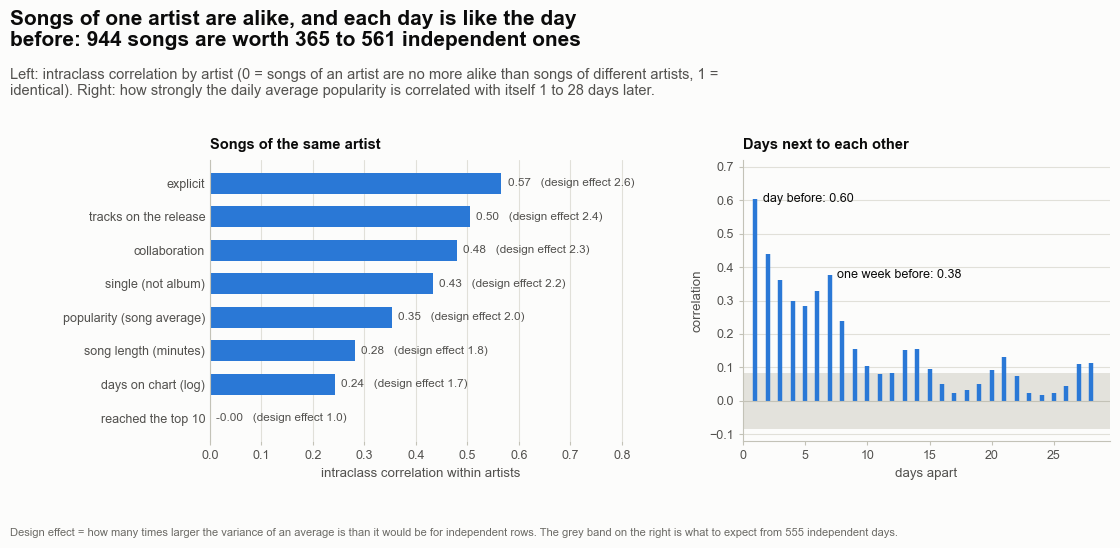

In [5]:
# Figure 01 - rows are not independent: songs of one artist resemble each other, and a day resembles the day before
order = icc_table.sort_values("icc", ascending=False)
fig, (ax1, ax2) = make_fig(11.8, 5.6, 1, 2, left=2.35, right=0.45, bottom=0.95, wspace=0.28, panel_titles=True, width_ratios=[1.15, 1],
                           title=f"Songs of one artist are alike, and each day is like the day before: {len(songs)} songs are worth "
                                 f"{FACTS['effn_explicit']:.0f} to {FACTS['effn_logdays']:.0f} independent ones",
                           subtitle="Left: intraclass correlation by artist (0 = songs of an artist are no more alike than songs of different artists, 1 = identical). "
                                    "Right: how strongly the daily average popularity is correlated with itself 1 to 28 days later.",
                           note_text="Design effect = how many times larger the variance of an average is than it would be for independent rows. "
                                     "The grey band on the right is what to expect from 555 independent days.")
y = np.arange(len(order))
ax1.barh(y, order["icc"].clip(lower=0), height=0.62, color=style.BLUE)
ax1.set_yticks(y)
ax1.set_yticklabels(order.index)
ax1.invert_yaxis()
ax1.set_xlim(0, 0.82)
for yi, (name, row) in zip(y, order.iterrows()):
    ax1.text(max(row["icc"], 0) + 0.012, yi, f"{row['icc']:.2f}   (design effect {row['design_effect']:.1f})", va="center", fontsize=8.5, color=style.INK_2)
style_axes(ax1, grid="x", bottom_spine=False)
ax1.tick_params(axis="y", length=0)
ax1.set_xlabel("intraclass correlation within artists")
panel_title(ax1, "Songs of the same artist")

lags = np.arange(1, 29)
band = 1.96 / np.sqrt(len(daily_pop))
ax2.axhspan(-band, band, color=style.GRID, alpha=0.9, linewidth=0)
ax2.vlines(lags, 0, acf, color=style.BLUE, linewidth=3.2)
ax2.axhline(0, color=style.AXIS, linewidth=0.8)
direct_label(ax2, 1.6, acf[0], f"day before: {acf[0]:.2f}", size=9, color=style.INK)
direct_label(ax2, 7.6, acf[6], f"one week before: {acf[6]:.2f}", size=9, color=style.INK)
ax2.set_xlim(0, 29.5)
ax2.set_ylim(-0.12, 0.72)
ax2.set_xlabel("days apart")
ax2.set_ylabel("correlation")
style_axes(ax2, grid="y")
panel_title(ax2, "Days next to each other")
save_fig(fig, "p5_01_dependence", FIG_DIR)
plt.show()

**What to notice**

- Explicit has an intraclass correlation of 0.57 and collaboration 0.48: knowing the artist tells a lot about whether a song is explicit or a collaboration. The 944 songs are worth only about 365 independent songs for the explicit measure and 561 for the days on the chart.
- Reaching the top 10 is the exception (about zero, design effect 1.0). Whether a song gets to the top 10 is hardly an artist trait. The tests of H1, H7 and H9 still allow for artists, because the flags they compare (explicit, long, collaboration) are strongly clustered.
- The biggest artist has 96 of the 944 songs (10%), 142 artists have one song, and the five biggest artists together have 25% of all songs. This is why Section 15 repeats every test without the biggest artist.
- Days: a day's average popularity correlates 0.60 with the day before, 0.38 with the same day a week earlier and still 0.11 four weeks earlier. The 555 days are worth about 138 independent days, which matters for H4.

**What this code is.** The first half of the placebo experiment, on songs. Whole artists are given a coin-flip label (heads or tails, the same label for all songs of an artist), 600 times. In each run the label is tested against three song measures (reaching the top 10, log days on the chart, average popularity) by three methods: the *naive* method that counts each song as independent, a *robust* method whose standard errors are clustered by artist, and the *wild cluster bootstrap-t*, which resamples whole artists.

**Why we need it.** The label cannot have any effect, because it was drawn by a coin. Every "significant" result is therefore a false alarm, and a method that is honest should raise one in 20 runs. This is a direct, visible test of a method, and it uses the real artists, the real clusters and the real outcomes, so it shows what would happen with exactly this data.

**What will happen.** The code draws the labels once (from the fixed seed), then for each outcome and each run applies the three tests and stores the p-values. Inside the bootstrap it uses 199 repeats, to keep 600 runs fast (the real tests use 10,000). The share of p-values below 0.05 is stored with a Wilson interval, and the table of shares is printed.

**Expected outcome.** A small table of percentages: the naive column well above 5% for every outcome (far above for popularity and log days), the robust column closer, the bootstrap column close to 5%.

**Motive.** Do not take a method on trust. Count its false alarms.

In [6]:
# Section 3 - the placebo experiment, part 1: give whole artists a coin-flip label, then test the label in three ways
PLACEBO_RUNS = 600
PLACEBO_BOOT = 199                                                                # bootstrap repeats inside each run (the real tests below use 10,000)
rng = np.random.default_rng(SEED)
artist_codes, artist_names = pd.factorize(songs["artist"])
placebo_labels = rng.random((PLACEBO_RUNS, len(artist_names))) < 0.5            # one coin flip per artist and run: all songs of an artist share the label

placebo_outcomes = {"reached the top 10": songs["top10"], "days on chart (log)": songs["log_days"], "popularity (song average)": songs["avg_popularity"]}
placebo_keys = {"reached the top 10": "top10", "days on chart (log)": "logdays", "popularity (song average)": "popularity"}
methods = {"naive": "ignores the dependence", "clustered": "robust standard error", "wild": "bootstrap"}
placebo = []


def add_placebo_row(name, key, p_values):
    """Store the share of false alarms (p below 5%) of the three methods, with Wilson intervals, in `placebo` and in FACTS."""
    row = {"outcome": name}
    for method in methods:
        successes = int(np.sum(p_values[method] < ALPHA))
        low, high = classical.wilson_interval(successes, len(p_values[method]))
        row[method], row[f"{method}_low"], row[f"{method}_high"] = successes / len(p_values[method]), low, high
        FACTS[f"placebo_{method}_{key}"] = 100 * successes / len(p_values[method])
    placebo.append(row)


for name, values in placebo_outcomes.items():
    present = values.notna().to_numpy()
    outcome, codes = values.to_numpy(dtype=float)[present], artist_codes[present]
    p_values = {method: np.empty(PLACEBO_RUNS) for method in methods}
    for run in range(PLACEBO_RUNS):
        label = placebo_labels[run][codes]
        p_values["naive"][run] = dependence.cluster_robust_two_group_test(outcome, label, None).p_value       # treats 944 songs as 944 independent pieces
        p_values["clustered"][run] = dependence.cluster_robust_two_group_test(outcome, label, codes).p_value  # standard errors clustered by artist, t reference
        p_values["wild"][run] = dependence.wild_two_group_test(outcome, label, codes, n_boot=PLACEBO_BOOT, seed=SEED + run).p_value
    add_placebo_row(name, placebo_keys[name], p_values)
FACTS["placebo_runs"] = PLACEBO_RUNS
print(pd.DataFrame(placebo).set_index("outcome")[list(methods)].mul(100).round(1).rename(columns=methods).to_string())

                           ignores the dependence  robust standard error  bootstrap
outcome                                                                            
reached the top 10                           17.2                    8.5        5.2
days on chart (log)                          32.5                    6.2        4.7
popularity (song average)                    52.3                    8.8        4.7


**What this code is.** The second half of the placebo experiment, on days. The cell creates 600 series of pure noise as long as the real chart (555 days), each with the same day-to-day correlation as the real daily average popularity once its straight line is removed. Each series is then tested for a trend, three ways: a straight-line test that counts days as independent, the same line with a Newey-West standard error (which allows for correlation between neighbouring days) and a residual block bootstrap in blocks of 14 days.

**Why we need it.** H4 asks whether the average popularity has fallen. A series of daily averages is correlated from day to day, which makes the straight-line test far too eager to find trends. The only way to know how eager is to test series that have no trend by construction.

**What will happen.** Each series is built day by day as a share of yesterday plus a fresh random shock (the first 50 days are thrown away so that the start does not matter). The three tests run on each, and the share of p-values below 0.05 is stored for each method next to the song results of the previous cell.

**Expected outcome.** A table with all four rows (three song measures and the daily trend). For the daily trend, the straight-line test should raise false alarms in roughly one run in three, the Newey-West version in fewer, and the block bootstrap in a share close to 5%.

**Motive.** The test for H4 is chosen because of this table, not in spite of it.

In [7]:
# Section 3 - the placebo experiment, part 2: noise that is correlated from day to day, tested for a trend that is not there
from scipy.special import ndtri                                                  # the inverse normal curve: turns uniform random numbers into normal ones

TS_RUNS = 600
TS_BOOT = 199
y_real = daily_pop.to_numpy()
rho_noise = dependence.autocorrelation(y_real - np.polyval(np.polyfit(np.arange(len(y_real)), y_real, 1), np.arange(len(y_real))))   # day-to-day correlation of the real series
FACTS["placebo_rho"] = rho_noise
rng = np.random.default_rng(SEED + 1)
shocks = ndtri(np.clip(rng.random((TS_RUNS, len(y_real) + 50)), 1e-12, 1 - 1e-12))
p_days = {method: np.empty(TS_RUNS) for method in methods}
for run in range(TS_RUNS):
    noise = np.empty(shocks.shape[1])
    noise[0] = shocks[run, 0]
    for day in range(1, len(noise)):
        noise[day] = rho_noise * noise[day - 1] + shocks[run, day]               # each day = part of yesterday + a fresh shock
    noise = noise[50:]                                                           # the first 50 days are thrown away so that the start does not matter
    p_days["naive"][run] = dependence.cluster_robust_slope_test(noise, np.arange(len(noise)), None).p_value
    p_days["clustered"][run] = dependence.hac_trend_test(noise).p_value
    p_days["wild"][run] = dependence.bootstrap_p_value(dependence.block_bootstrap_trend(noise, block=14, n_boot=TS_BOOT, seed=SEED + run))
add_placebo_row("trend of a daily series", "days", p_days)
placebo_table = pd.DataFrame(placebo).set_index("outcome")
FACTS["placebo_ts_runs"] = TS_RUNS

show = placebo_table[list(methods)].mul(100).round(1)
show.columns = [f"{label} (% of runs)" for label in methods.values()]
display(show)
print(f"\nEvery run tests something that means nothing (a coin-flip label for whole artists, or a trend in pure day-to-day noise), so every 'significant' result is a false alarm. "
      f"A fair test raises one in {1 / ALPHA:.0f} runs ({100 * ALPHA:.0f}%).")

,ignores the dependence (% of runs),robust standard error (% of runs),bootstrap (% of runs)
outcome,,,
reached the top 10,17.2,8.5,5.2
days on chart (log),32.5,6.2,4.7
popularity (song average),52.3,8.8,4.7
trend of a daily series,30.8,12.7,7



Every run tests something that means nothing (a coin-flip label for whole artists, or a trend in pure day-to-day noise), so every 'significant' result is a false alarm. A fair test raises one in 20 runs (5%).


**What this code is.** Figure 2. Grouped bars of the false-alarm rates of the three methods for the four placebo tests, with a 95% interval on each bar and a line at 5%, which is what a fair test gives.

**Why we need it.** The two tables of the previous cells are the evidence; the picture is what a reader will remember. It also shows the cost of ignoring dependence in one number per test.

**What will happen.** The code draws one cluster of three bars per test (naive in orange, robust in light blue, bootstrap in dark blue), the whisker of each bar, the 5% line and a legend, and saves the picture as `p5_02_placebo.png`.

**Expected outcome.** Tall orange bars, medium light-blue bars and short dark-blue bars that sit near the 5% line.

**Motive.** Turn a technical decision (use a wild bootstrap, use a block bootstrap) into something every reader can see is needed.

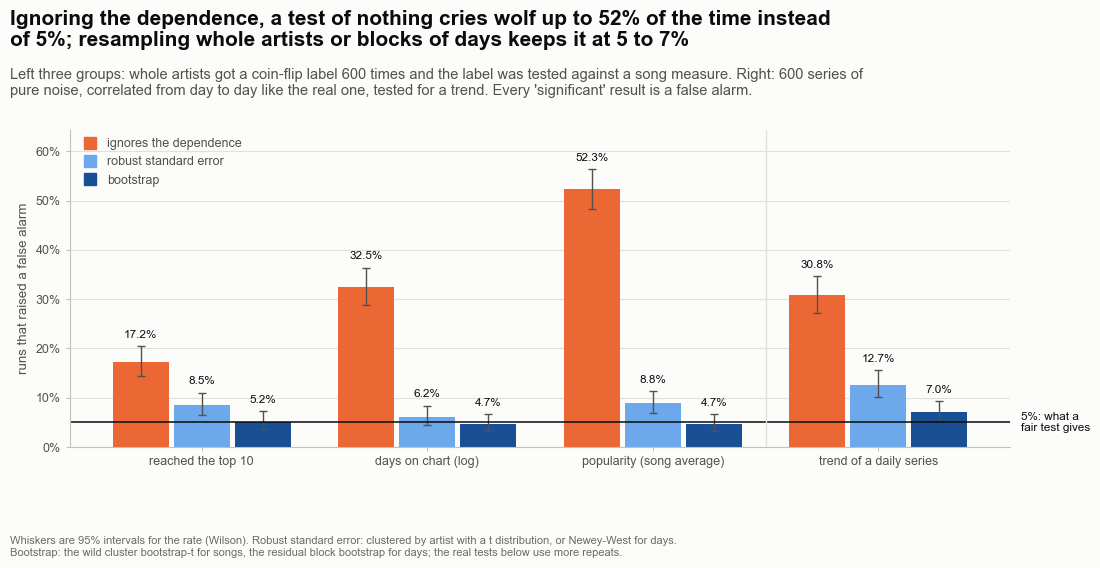

In [8]:
# Figure 02 - the false-alarm rate of three ways to test something that means nothing
fig, ax = make_fig(11.8, 5.8, left=0.95, right=1.45, bottom=0.95,
                   title=f"Ignoring the dependence, a test of nothing cries wolf up to {FACTS['placebo_naive_popularity']:.0f}% of the time instead of 5%; resampling whole artists or blocks of days keeps it at {min(FACTS[k] for k in FACTS if k.startswith('placebo_wild_')):.0f} to {max(FACTS[k] for k in FACTS if k.startswith('placebo_wild_')):.0f}%",
                   subtitle=f"Left three groups: whole artists got a coin-flip label {PLACEBO_RUNS} times and the label was tested against a song measure. "
                            f"Right: {TS_RUNS} series of pure noise, correlated from day to day like the real one, tested for a trend. Every 'significant' result is a false alarm.",
                   note_text="Whiskers are 95% intervals for the rate (Wilson). Robust standard error: clustered by artist with a t distribution, or Newey-West for days. "
                             "Bootstrap: the wild cluster bootstrap-t for songs, the residual block bootstrap for days; the real tests below use more repeats.")
positions = np.arange(len(placebo_table))
width = 0.27
colours = {"naive": style.ORANGE, "clustered": style.BLUE_STEPS[300], "wild": style.BLUE_STEPS[600]}
for index, method in enumerate(methods):
    offset = (index - 1) * width
    values = placebo_table[method].to_numpy() * 100
    highs = placebo_table[f"{method}_high"].to_numpy() * 100
    ax.bar(positions + offset, values, width=width * 0.92, color=colours[method])
    ax.errorbar(positions + offset, values, yerr=[values - placebo_table[f"{method}_low"].to_numpy() * 100, highs - values], fmt="none", ecolor=style.INK_2, elinewidth=1.0, capsize=3)
    for xi, value, high in zip(positions + offset, values, highs):
        ax.text(xi, high + 1.3, f"{value:.1f}%", ha="center", va="bottom", fontsize=8.5, color=style.INK)
ax.axhline(100 * ALPHA, color=style.INK, linewidth=1.1)
ax.annotate("5%: what a\nfair test gives", xy=(1.0, 100 * ALPHA), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points",
            ha="left", va="center", fontsize=8.5, color=style.INK, annotation_clip=False)
ax.axvline(len(placebo_table) - 1.5, color=style.GRID, linewidth=1.0)
ax.set_xticks(positions)
ax.set_xticklabels(placebo_table.index)
ax.set_ylim(0, placebo_table["naive_high"].max() * 100 + 8)
ax.yaxis.set_major_formatter(percent_formatter())
ax.set_ylabel("runs that raised a false alarm")
style_axes(ax, grid="y")
swatch_legend(ax, [(label, colours[key]) for key, label in methods.items()], loc="upper left")
save_fig(fig, "p5_02_placebo", FIG_DIR)
plt.show()

**What to notice**

- Ignoring the dependence, a test of nothing raised a false alarm in 17% of runs for the top-10 outcome, 32% for days on the chart, 52% for popularity and 31% for the trend of a daily series, against the 5% that a fair test gives.
- The wild cluster bootstrap keeps it at 5.2%, 4.7% and 4.7%. The robust standard error alone is better than the naive test but still too eager (6.2% to 8.8%), because with only 243 clusters, most of them tiny and a few very large, the usual t reference is too optimistic.
- For the daily trend, the straight-line test is wrong in 31% of runs, the Newey-West version in 13%, the block bootstrap in 7%. It is the best of the three, but still a little above 5% in this experiment, so the p-value of H4 should be read as slightly optimistic.
- From here on, **the primary test of every hypothesis is chosen from this evidence**: a wild cluster bootstrap by artist for song-level claims, a block bootstrap for the daily trend, week-level resampling for weekdays. The planned tests stay in the tables, so you can see how much they would have overstated the evidence.

## Section 4 - H1 - Do explicit songs reach the top 10 more often?

The question is about songs, with a yes/no outcome: did the song ever reach the top 10? The planned test compares two proportions. Because songs of one artist are alike (Section 3), the primary test resamples whole artists. The same set of checks is reused for H9 in the next section, so that the two questions are treated identically.

**What this code is.** A function that runs the whole set of tests for a question of the type *two groups, yes or no outcome*, and its first use on H1 (explicit against not explicit). The set is: the chi-square test and the Z-test for two proportions (the **planned** tests, which treat every song as independent), Fisher's exact test (no large-sample approximation), a test whose standard errors are clustered by artist, the **wild cluster bootstrap-t** (the **primary** test), and a plain artist bootstrap as a cross-check for the interval. It also works out how much larger the variance is than for independent songs, the smallest difference this data could have found, and a test of practical equality.

**Why we need it.** One function for H1 and H9 means that the two questions cannot be treated differently by accident. Each test answers a slightly different question: the planned tests say what would be true if songs were independent; the clustered and bootstrap tests say what is left once artists are allowed for; the power and equality checks say what a *non*-significant result would and would not mean.

**What will happen.** The code counts how many songs of each group reached the top 10, runs the tests, and stores all numbers in `FACTS` under the prefix `h1_`. For the equality test (TOST) it uses a margin of 5 percentage points: two groups count as practically equal if they differ by less than that. The cell then shows the 2 x 2 table, a table of six methods with their p-values and intervals for the difference, and two summary sentences.

**Expected outcome.** A 2 x 2 table (177 of 495 explicit songs and 129 of 449 other songs reached the top 10), a table where the p-value rises a little as the methods become more careful about artists, and the summary of the difference with its size (Cohen's h and odds ratio).

**Motive.** Give the claim every fair chance to fail. If it survives the artist-aware test, we know it is more than a side effect of a few big artists.

In [9]:
# Section 4 - H1: do explicit songs reach the top 10 more often? One battery for "two groups, yes/no outcome", used again for H9
MARGIN = 0.05                                          # two groups count as "practically equal" if they differ by less than 5 percentage points


def two_proportion_battery(flag, outcome, clusters, tag, seed):
    """
    Run every test of a two-group, yes/no question and keep the numbers. `flag` = the group (True/False), `outcome` = 1.0/0.0, `clusters` = the artist
    of each row. Everything is stored in FACTS under the prefix `tag` (for example h1_p_yes = share of the group with the outcome).
    """
    flag = np.asarray(flag, dtype=bool)
    outcome = np.asarray(outcome, dtype=float)
    codes = pd.factorize(clusters)[0]
    x1, n1 = int(outcome[flag].sum()), int(flag.sum())
    x0, n0 = int(outcome[~flag].sum()), int((~flag).sum())
    table = np.array([[x1, n1 - x1], [x0, n0 - x0]])

    # ---- the planned tests: they treat every song as an independent piece of evidence
    z = classical.two_proportion_ztest(x1, n1, x0, n0)
    chi = classical.chi_square_independence(table)
    fisher = classical.fisher_exact_2x2(table)
    assert abs(z.statistic ** 2 - chi.statistic) < 1e-8, "for a 2 x 2 table, z squared must equal chi-square"

    # ---- the tests that know that songs belong to artists
    clustered = dependence.cluster_robust_two_group_test(outcome, flag, codes)                    # standard errors clustered by artist, t reference
    wild = dependence.wild_two_group_test(outcome, flag, codes, n_boot=N_BOOT, seed=seed)         # the primary test of the project
    y_flag = outcome * flag
    flag_f = flag.astype(float)
    replicates = dependence.cluster_bootstrap(codes, lambda w: (w @ y_flag) / (w @ flag_f) - (w @ (outcome - y_flag)) / (w @ (1 - flag_f)), n_boot=N_BOOT, seed=seed + 1)
    assert np.isfinite(replicates).all()
    boot_low, boot_high = dependence.bootstrap_interval(replicates)
    group_boot = {}                                                                               # the same bootstrap for each group's own share
    for group_name, mask in (("yes", flag_f), ("no", 1 - flag_f)):
        in_group = outcome * mask
        group_replicates = dependence.cluster_bootstrap(codes, lambda w: (w @ in_group) / (w @ mask), n_boot=N_BOOT, seed=seed + 1)
        group_boot[group_name] = dependence.bootstrap_interval(group_replicates)
    naive_se = dependence.cluster_robust_two_group_test(outcome, flag, None).detail["se"]
    design_effect = (wild.detail["se"] / naive_se) ** 2                                           # how much bigger the variance of the difference really is

    # ---- how much could this data set have detected, and could we call the groups equal?
    p_base = x0 / n0
    mdd = power.minimum_detectable_difference(p_base, n1, n0, design_effect=design_effect)
    tost = power.tost_equivalence(wild.estimate, wild.detail["se"], MARGIN, df=wild.detail["clusters"] - 1)

    out = {"table": table, "x1": x1, "n1": n1, "x0": x0, "n0": n0, "z": z, "chi": chi, "fisher": fisher, "clustered": clustered, "wild": wild,
           "boot": (boot_low, boot_high), "boot_p": dependence.bootstrap_p_value(replicates), "group_boot": group_boot, "design_effect": design_effect, "mdd": mdd, "tost": tost}
    h = z.detail["cohens_h"]
    for key, value in {"n_yes": n1, "n_no": n0, "x_yes": x1, "x_no": x0, "p_yes": 100 * x1 / n1, "p_no": 100 * x0 / n0,
                       "diff_pp": 100 * wild.estimate, "diff_low": 100 * wild.ci_low, "diff_high": 100 * wild.ci_high,
                       "naive_low": 100 * z.ci_low, "naive_high": 100 * z.ci_high, "boot_low": 100 * boot_low, "boot_high": 100 * boot_high, "boot_p_text": format_p(out["boot_p"]),
                       "chi2": chi.statistic, "chi2_p": chi.p_value, "chi2_p_text": format_p(chi.p_value), "fisher_p_text": format_p(fisher.p_value),
                       "clustered_p_text": format_p(clustered.p_value), "wild_p": wild.p_value, "wild_p_text": format_p(wild.p_value),
                       "wild_t": wild.statistic, "odds_ratio": z.detail["odds_ratio"], "or_low": z.detail["odds_ratio_low"], "or_high": z.detail["odds_ratio_high"],
                       "h": h, "h_word": effect_label("cohens_h", h), "design_effect": design_effect, "mdd_pp": 100 * mdd,
                       "tost_p_text": format_p(tost.p_value), "equivalent": bool(tost.detail["equivalent"]), "margin_pp": 100 * MARGIN}.items():
        FACTS[f"{tag}_{key}"] = value
    return out


explicit_flag = songs["is_explicit"].to_numpy()
h1 = two_proportion_battery(explicit_flag, songs["top10"], songs["artist"], "h1", SEED + 100)

display(pd.DataFrame(h1["table"], index=["explicit", "not explicit"], columns=["reached the top 10", "did not"]))
rows = [("chi-square test, rows treated as independent (planned)", h1["chi"].p_value, None, None),
        ("Z-test for two proportions, same thing (z squared = chi-square)", h1["z"].p_value, 100 * h1["z"].ci_low, 100 * h1["z"].ci_high),
        ("Fisher exact test, no large-sample approximation", h1["fisher"].p_value, None, None),
        ("clustered by artist, t distribution", h1["clustered"].p_value, 100 * h1["clustered"].ci_low, 100 * h1["clustered"].ci_high),
        ("clustered by artist, wild bootstrap-t (primary)", h1["wild"].p_value, 100 * h1["wild"].ci_low, 100 * h1["wild"].ci_high),
        ("artist bootstrap (cross-check; interval only)", np.nan, 100 * h1["boot"][0], 100 * h1["boot"][1])]
display(pd.DataFrame(rows, columns=["method", "p-value", "difference, low (pp)", "difference, high (pp)"]).set_index("method"))
print(f"Explicit: {FACTS['h1_p_yes']:.1f}% reached the top 10, not explicit: {FACTS['h1_p_no']:.1f}%. Difference {FACTS['h1_diff_pp']:+.1f} points; "
      f"Cohen's h = {FACTS['h1_h']:.2f} ({FACTS['h1_h_word']}); odds ratio {FACTS['h1_odds_ratio']:.2f}.")
print(f"Variance of the difference is {FACTS['h1_design_effect']:.2f} times what independent songs would give. "
      f"With this data a difference of {FACTS['h1_mdd_pp']:.1f} points or more would be found 8 times in 10.")

,reached the top 10,did not
explicit,177,318
not explicit,129,320


,p-value,"difference, low (pp)","difference, high (pp)"
method,,,
"chi-square test, rows treated as independent (planned)",0.02124,NaN,NaN
"Z-test for two proportions, same thing (z squared = chi-square)",0.02124,1.049,12.91
"Fisher exact test, no large-sample approximation",0.02177,NaN,NaN
"clustered by artist, t distribution",0.03417,0.5289,13.53
"clustered by artist, wild bootstrap-t (primary)",0.0416,0.2708,13.78
artist bootstrap (cross-check; interval only),NaN,0.9275,13.93


Explicit: 35.8% reached the top 10, not explicit: 28.7%. Difference +7.0 points; Cohen's h = 0.15 (negligible); odds ratio 1.38.
Variance of the difference is 1.17 times what independent songs would give. With this data a difference of 9.3 points or more would be found 8 times in 10.


**What this code is.** Figure 3. Left: the share of explicit and not explicit songs that reached the top 10, each with two intervals: a thin grey one that ignores artists and a thick coloured one that resamples whole artists. Right: the difference between the groups, with its 95% interval and p-value as judged by four methods, from the planned Z-test down to the primary wild bootstrap.

**Why we need it.** A p-value alone hides how wide the uncertainty is and how much of it came from ignoring artists. The two sets of intervals on the left make the cost of ignoring them visible; the four rows on the right show that the conclusion is the same under every method, or that it is not.

**What will happen.** The function `two_proportion_figure` (also used for H9) draws the two panels from the stored results and saves the picture as `p5_03_h1_explicit_top10.png`.

**Expected outcome.** Two shares of about the same height with the thick lines wider than the thin ones, and four intervals on the right that all lean to the same side of zero, the last one the widest and closest to touching it.

**Motive.** Let the reader see how much the answer depends on the method.

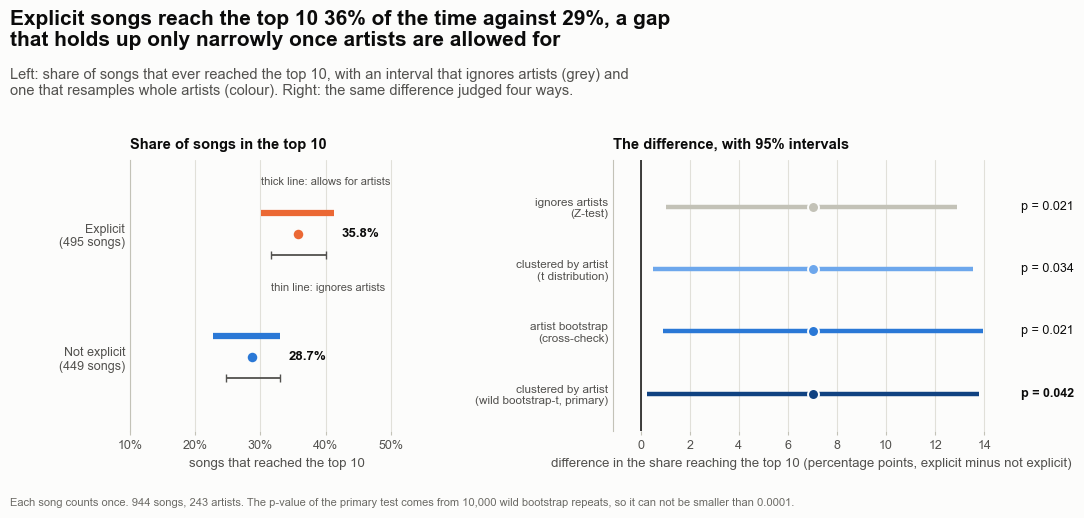

In [10]:
# Figure 03 - H1: the share of songs that reach the top 10, explicit against not explicit, and the difference with four kinds of interval
def two_proportion_figure(result, tag, names, colours, title, subtitle, note_text, fig_name, margin=None):
    """Left: each group's share with two intervals. Right: the difference between the groups, as judged by four methods."""
    fig, (ax1, ax2) = make_fig(11.8, 5.3, 1, 2, left=1.55, right=1.45, bottom=0.75, wspace=0.55, panel_titles=True, width_ratios=[0.85, 1.15],
                               title=title, subtitle=subtitle, note_text=note_text)
    groups = [("yes", result["x1"], result["n1"], names[0], colours[0]), ("no", result["x0"], result["n0"], names[1], colours[1])]
    for row, (key, successes, total, label, colour) in enumerate(groups):
        share = 100 * successes / total
        naive_low, naive_high = (100 * v for v in classical.wilson_interval(successes, total))
        boot_low, boot_high = (100 * v for v in result["group_boot"][key])
        ax1.errorbar([share], [row + 0.17], xerr=[[share - naive_low], [naive_high - share]], fmt="none", ecolor=style.INK_2, elinewidth=1.3,
                     capsize=3, zorder=2)                                                                      # lower: interval that ignores artists
        ax1.hlines(row - 0.17, boot_low, boot_high, color=colour, linewidth=4.5, zorder=3)                      # upper: interval that allows for artists
        ax1.scatter([share], [row], s=70, color=colour, edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
        ax1.text(max(naive_high, boot_high) + 1.2, row, f"{share:.1f}%", va="center", fontsize=9.5, color=style.INK, fontweight="bold")
        if row == 0:
            ax1.text(boot_low, row - 0.38, "thick line: allows for artists", fontsize=8, color=style.INK_2, va="bottom", ha="left")
            ax1.text(naive_low, row + 0.40, "thin line: ignores artists", fontsize=8, color=style.INK_2, va="top", ha="left")
    ax1.set_yticks([0, 1])
    ax1.set_yticklabels([f"{names[0]}\n({result['n1']:,} songs)", f"{names[1]}\n({result['n0']:,} songs)"])
    ax1.set_ylim(1.6, -0.6)
    ax1.set_xlim(10, 55)
    ax1.xaxis.set_major_formatter(percent_formatter())
    ax1.set_xlabel("songs that reached the top 10")
    style_axes(ax1, grid="x", bottom_spine=False)
    ax1.tick_params(axis="y", length=0)
    panel_title(ax1, "Share of songs in the top 10")

    rows = [("ignores artists\n(Z-test)", result["z"].estimate, result["z"].ci_low, result["z"].ci_high, format_p(result["z"].p_value), style.AXIS),
            ("clustered by artist\n(t distribution)", result["clustered"].estimate, result["clustered"].ci_low, result["clustered"].ci_high, format_p(result["clustered"].p_value), style.BLUE_STEPS[300]),
            ("artist bootstrap\n(cross-check)", result["wild"].estimate, result["boot"][0], result["boot"][1], format_p(result["boot_p"]), style.BLUE_STEPS[450]),
            ("clustered by artist\n(wild bootstrap-t, primary)", result["wild"].estimate, result["wild"].ci_low, result["wild"].ci_high, format_p(result["wild"].p_value), style.BLUE_STEPS[650])]
    if margin is not None:
        ax2.axvspan(-100 * margin, 100 * margin, color=style.GRID, alpha=0.8, linewidth=0, zorder=0)
        ax2.text(0, -0.5, f"practically equal: within {100 * margin:.0f} points", ha="center", va="center", fontsize=8.5, color=style.INK_2,
                 bbox=dict(boxstyle="square,pad=0.2", facecolor=style.GRID, edgecolor="none"), zorder=5)
    ax2.axvline(0, color=style.INK, linewidth=1.1, zorder=1)
    for row, (label, estimate, low, high, p_text, colour) in enumerate(rows):
        ax2.hlines(row, 100 * low, 100 * high, color=colour, linewidth=3.2, zorder=3)
        ax2.scatter([100 * estimate], [row], s=62, color=colour, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
        ax2.annotate(p_text, xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9,
                     color=style.INK, annotation_clip=False, fontweight="bold" if row == 3 else "normal")
    ax2.set_yticks(range(4))
    ax2.set_yticklabels([r[0] for r in rows], fontsize=8.5)
    ax2.set_ylim(3.6, -0.75)
    lows = [100 * r[2] for r in rows] + [-100 * (margin or 0)]
    highs = [100 * r[3] for r in rows] + [100 * (margin or 0)]
    pad = 0.08 * (max(highs) - min(lows))
    ax2.set_xlim(min(lows + [0]) - pad, max(highs + [0]) + pad)
    ax2.set_xlabel(f"difference in the share reaching the top 10 (percentage points, {names[0].lower()} minus {names[1].lower()})")
    style_axes(ax2, grid="x", bottom_spine=False)
    ax2.tick_params(axis="y", length=0)
    panel_title(ax2, "The difference, with 95% intervals")
    save_fig(fig, fig_name, FIG_DIR)
    plt.show()


two_proportion_figure(
    h1, "h1", ("Explicit", "Not explicit"), (style.EXPLICIT_COLOR, style.CLEAN_COLOR),
    title=f"Explicit songs reach the top 10 {FACTS['h1_p_yes']:.0f}% of the time against {FACTS['h1_p_no']:.0f}%, a gap that holds up only narrowly once artists are allowed for",
    subtitle="Left: share of songs that ever reached the top 10, with an interval that ignores artists (grey) and one that resamples whole artists (colour). "
             "Right: the same difference judged four ways.",
    note_text=f"Each song counts once. {len(songs)} songs, {FACTS['artists']} artists. The p-value of the primary test comes from {N_BOOT:,} wild bootstrap repeats, so it can not be smaller than {1 / (N_BOOT + 1):.4f}.",
    fig_name="p5_03_h1_explicit_top10")

**What to notice**

- 35.8% of explicit songs reached the top 10 against 28.7% of the others, a difference of +7.0 percentage points with a 95% interval of 0.3 to 13.8. The lower end is close to zero.
- The p-value grows as the method becomes more careful about artists: p = 0.021 for the planned chi-square test, p = 0.034 when standard errors are clustered, p = 0.042 for the primary wild bootstrap. It stays below 0.05, but only narrowly.
- The effect is small: Cohen's h is 0.15 (negligible by the usual benchmarks) and the odds ratio is 1.38 (interval 1.05 to 1.82). With this data a difference of 9.3 points or more would be found 8 times in 10, so an effect of this size is at the edge of what the data can see.
- The test of practical equality does not show that the groups are alike either (p = 0.73). In Section 14, after the correction for ten tests, the verdict of H1 is *Suggestive*.

## Section 5 - H9 - Do collaborations reach the top 10 less often than solo songs?

The same question type as H1, the same tests, and the same function. What changes is the answer: this one is not close, and it is the first claim where we must be careful about what a non-significant result means.

**What this code is.** The second use of the two-group battery of Section 4, now for collaborations (songs with more than one credited artist) against solo songs.

**Why we need it.** H9 is the mirror of H1: collaborations are often thought of as bigger hits, and Phase 4 saw a slightly lower top-10 share for them. Running exactly the same battery means that any difference between the two results comes from the data and not from a different way of testing.

**What will happen.** The cell calls `two_proportion_battery` with the collaboration flag and the same outcome, stores the results under the prefix `h9_`, shows the 2 x 2 table and a table of four methods, and prints two sentences: the two shares and the difference, and what the data could and could not have shown.

**Expected outcome.** A 2 x 2 table with far fewer collaborations (122) than solo songs (822), four p-values that agree with each other (none is close to 0.05), and the warning that a non-significant difference is not the same as no difference.

**Motive.** Know what the test can see. Absence of evidence is only useful when we also know how large an effect we would have noticed.

In [11]:
# Section 5 - H9: do collaborations reach the top 10 less often than solo songs? The same battery as H1
collab_flag = songs["is_collab"].to_numpy()
h9 = two_proportion_battery(collab_flag, songs["top10"], songs["artist"], "h9", SEED + 200)

display(pd.DataFrame(h9["table"], index=["collaboration", "solo"], columns=["reached the top 10", "did not"]))
rows = [("chi-square test, rows treated as independent", h9["chi"].p_value, 100 * h9["z"].ci_low, 100 * h9["z"].ci_high),
        ("clustered by artist, t distribution", h9["clustered"].p_value, 100 * h9["clustered"].ci_low, 100 * h9["clustered"].ci_high),
        ("clustered by artist, wild bootstrap-t (primary)", h9["wild"].p_value, 100 * h9["wild"].ci_low, 100 * h9["wild"].ci_high),
        ("artist bootstrap (cross-check)", h9["boot_p"], 100 * h9["boot"][0], 100 * h9["boot"][1])]
display(pd.DataFrame(rows, columns=["method", "p-value", "difference, low (pp)", "difference, high (pp)"]).set_index("method"))
print(f"Collaborations: {FACTS['h9_p_yes']:.1f}% reached the top 10, solo songs: {FACTS['h9_p_no']:.1f}%. Difference {FACTS['h9_diff_pp']:+.1f} points; "
      f"Cohen's h = {FACTS['h9_h']:.2f} ({FACTS['h9_h_word']}).")
print(f"With this data a difference of {FACTS['h9_mdd_pp']:.1f} points or more would be found 8 times in 10. "
      f"Equivalence test (the groups differ by less than {FACTS['h9_margin_pp']:.0f} points): {FACTS['h9_tost_p_text']}.")

,reached the top 10,did not
collaboration,35,87
solo,271,551


,p-value,"difference, low (pp)","difference, high (pp)"
method,,,
"chi-square test, rows treated as independent",0.346,-12.27,4.852
"clustered by artist, t distribution",0.42,-14.72,6.156
"clustered by artist, wild bootstrap-t (primary)",0.4383,-15.35,6.791
artist bootstrap (cross-check),0.4034,-15.42,5.955


Collaborations: 28.7% reached the top 10, solo songs: 33.0%. Difference -4.3 points; Cohen's h = -0.09 (negligible).
With this data a difference of 15.3 points or more would be found 8 times in 10. Equivalence test (the groups differ by less than 5 points): p = 0.45.


**What this code is.** Figure 4. The same two-panel picture as Figure 3 for collaborations and solo songs, with one addition: a shaded band around zero that marks *practical equality*, differences smaller than 5 percentage points either way.

**Why we need it.** For H9 the interesting question is not only "is there a difference" but "could the groups be equal for practical purposes". The band shows whether the interval fits inside it (equality shown) or sticks out of it (equality not shown).

**What will happen.** It calls the same drawing function with the H9 results and the margin, and saves the picture as `p5_04_h9_collab_top10.png`.

**Expected outcome.** Two intervals on the left that overlap heavily, and four intervals on the right that all straddle zero and are much wider than the shaded band.

**Motive.** Show the difference between *no evidence of an effect* and *evidence of no effect*.

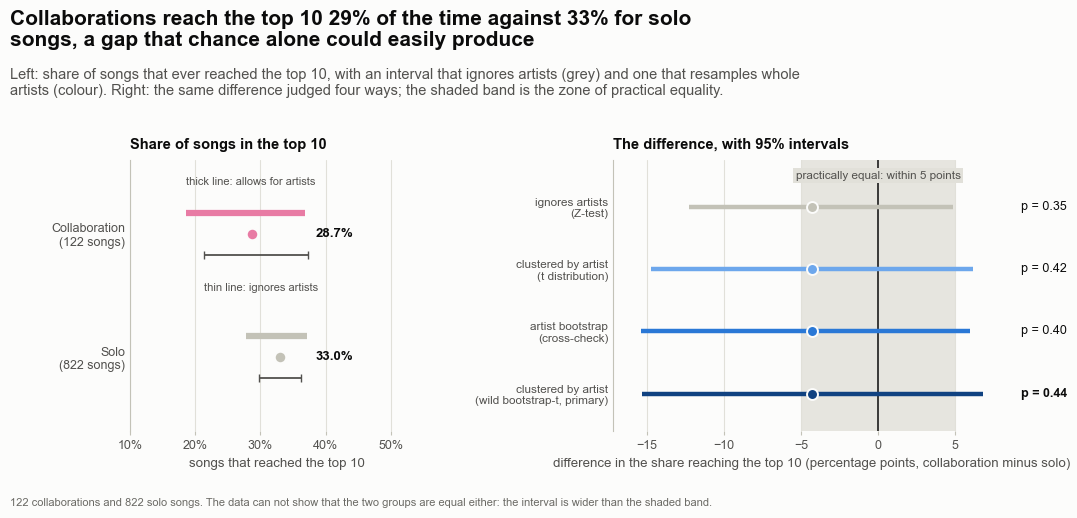

In [12]:
# Figure 04 - H9: collaboration against solo songs, with the zone of "practically equal" shaded
two_proportion_figure(
    h9, "h9", ("Collaboration", "Solo"), (style.MAGENTA, style.AXIS),
    title=f"Collaborations reach the top 10 {FACTS['h9_p_yes']:.0f}% of the time against {FACTS['h9_p_no']:.0f}% for solo songs, a gap that chance alone could easily produce",
    subtitle="Left: share of songs that ever reached the top 10, with an interval that ignores artists (grey) and one that resamples whole artists (colour). "
             "Right: the same difference judged four ways; the shaded band is the zone of practical equality.",
    note_text=f"{int(h9['n1'])} collaborations and {int(h9['n0'])} solo songs. The data can not show that the two groups are equal either: the interval is wider than the shaded band.",
    fig_name="p5_04_h9_collab_top10", margin=MARGIN)

**What to notice**

- 28.7% of the 122 collaborations reached the top 10 against 33.0% of the 822 solo songs: a difference of -4.3 points with a 95% interval of -15.4 to 6.8. The interval contains zero by a wide margin.
- Every method agrees: p = 0.35 (chi-square), p = 0.42 (clustered), p = 0.44 (primary). The dependence between artists barely matters here, because the answer is far from 0.05 under any method.
- This is *not* evidence that collaborations and solo songs are equal. The interval is wider than the shaded band, and the equality test gives p = 0.45. With 122 collaborations the data could only have found a difference of 15 points or more.
- So H9 is *Not supported*: the data do not show a lower top-10 share for collaborations, and they are too thin to rule out a moderate one in either direction.

## Section 6 - H2 - Do singles stay longer on the chart than album tracks?

The outcome here is a duration, the number of days a song spends on the chart. Durations are awkward in three ways: they are very skewed (a few songs stay for months), songs of one artist are alike, and some songs are still on the chart when the file ends, so their stay is not finished. The primary test handles the first two; two extra checks handle the third.

**What this code is.** The test of H2 and four checks around it. The planned tests are the Mann-Whitney U test (it compares ranks, so the skew does not matter) and a Welch t test on the *logarithm* of the days. The primary test is the difference in average log days, with standard errors clustered by artist and a wild bootstrap-t. A difference of logs, turned back with the exponential function, is a *ratio of typical stays*: 1.5 means that singles typically stay one and a half times as long. The checks are the same test on ranks, the same test on songs that were followed from their first to their last day, and a Kaplan-Meier curve with a log-rank test on the first chart run of each song.

**Why we need it.** Days on the chart are skewed to the right (skewness 4.0 on the raw scale, 0.4 on the log scale), so the usual t test on raw days would be dominated by a few very long stays. The log scale also fits the question: "how many times longer" is more natural than "how many days longer". The finished-songs check and the log-rank test answer the censoring objection: a song that is still on the chart on the last day has not yet finished staying, and counting its days so far makes the stays look shorter than they are.

**What will happen.** The code stores the medians, means and skewness, runs the two planned tests, the primary test with 10,000 bootstrap repeats, an artist bootstrap for the interval, and the three checks. For the log-rank test it takes the first chart run of every song that was not already on the chart on day one, marks it as *finished* or *cut off*, and compares the two Kaplan-Meier curves. It shows a small table of the two groups and a table of six tests with their p-values and effects, then two sentences.

**Expected outcome.** Singles with a median of 13 days against 6 for album tracks, a ratio of typical stays of about 1.6 and six p-values that are all below 0.05. The planned tests give the smallest p-values; the primary test gives a larger, more honest one.

**Motive.** A claim about "how long" has to survive the three ways in which durations mislead: skew, related rows and songs that have not finished.

In [13]:
# Section 6 - H2: do singles stay longer on the chart than album tracks?
single = songs["is_single"].to_numpy()
artist_codes = pd.factorize(songs["artist"])[0]
days = songs["days_on_chart"].to_numpy(dtype=float)
log_days = songs["log_days"].to_numpy()

# ---- what the data look like, and why the planned t test is run on log days
FACTS["h2_n_single"], FACTS["h2_n_album"] = int(single.sum()), int((~single).sum())
FACTS["h2_median_single"], FACTS["h2_median_album"] = float(np.median(days[single])), float(np.median(days[~single]))
FACTS["h2_mean_single"], FACTS["h2_mean_album"] = float(days[single].mean()), float(days[~single].mean())
normality_raw = classical.normality_summary(days)
normality_log = classical.normality_summary(log_days)
FACTS["h2_skew_raw"], FACTS["h2_skew_log"] = normality_raw["skewness"], normality_log["skewness"]
levene = classical.levene_test([log_days[single], log_days[~single]])
FACTS["h2_levene_p_text"] = format_p(levene.p_value)

# ---- the planned tests: rows treated as independent
mwu = classical.mann_whitney_test(days[single], days[~single])
welch = classical.two_sample_ttest(log_days[single], log_days[~single])
hl_shift = classical.hodges_lehmann_shift(days[single], days[~single])
ratio_naive = (np.exp(welch.estimate), np.exp(welch.ci_low), np.exp(welch.ci_high))

# ---- the primary test: the difference in mean log days, standard errors clustered by artist, wild bootstrap-t. exp(difference) = ratio of typical stays
wild = dependence.wild_two_group_test(log_days, single, artist_codes, n_boot=N_BOOT, seed=SEED + 300)
wild_rank = dependence.wild_two_group_test(stats.rankdata(days), single, artist_codes, n_boot=N_BOOT, seed=SEED + 301, name="difference in ranks (wild cluster bootstrap-t)")
ld_single, ld_album = log_days * single, log_days * ~single
boot = dependence.cluster_bootstrap(artist_codes, lambda w: (w @ ld_single) / (w @ single) - (w @ ld_album) / (w @ ~single), n_boot=N_BOOT, seed=SEED + 302)
boot_low, boot_high = dependence.bootstrap_interval(boot)

# ---- a check on songs that were followed from start to end (no song cut off by the edges of the file)
complete = (songs["run_status"] == "Complete history observed").to_numpy()
wild_complete = dependence.wild_two_group_test(log_days[complete], single[complete], artist_codes[complete], n_boot=N_BOOT, seed=SEED + 303)
mwu_complete = classical.mann_whitney_test(days[complete & single], days[complete & ~single])

# ---- a check that respects censoring: how long does the FIRST chart run of a song last? (Kaplan-Meier and log-rank)
first_runs = runs.sort_values(["track_id", "start_snapshot"]).groupby("track_id").first().reset_index()
first_runs = first_runs[~first_runs["left_censored"]].merge(songs[["track_id", "is_single"]], on="track_id")       # songs already on the chart on day one are dropped
first_runs["exit_seen"] = ~first_runs["right_censored"]
km = {name: survival.kaplan_meier(group["length"].to_numpy(), group["exit_seen"].to_numpy())
      for name, group in (("single", first_runs[first_runs["is_single"]]), ("album", first_runs[~first_runs["is_single"]]))}
logrank = survival.logrank_test(first_runs.loc[first_runs["is_single"], "length"].to_numpy(), first_runs.loc[first_runs["is_single"], "exit_seen"].to_numpy(),
                                first_runs.loc[~first_runs["is_single"], "length"].to_numpy(), first_runs.loc[~first_runs["is_single"], "exit_seen"].to_numpy())

for key, value in {"h2_ratio": np.exp(wild.estimate), "h2_ratio_low": np.exp(wild.ci_low), "h2_ratio_high": np.exp(wild.ci_high),
                   "h2_ratio_naive": ratio_naive[0], "h2_naive_low": ratio_naive[1], "h2_naive_high": ratio_naive[2],
                   "h2_boot_low": np.exp(boot_low), "h2_boot_high": np.exp(boot_high), "h2_boot_p_text": format_p(dependence.bootstrap_p_value(boot)),
                   "h2_mwu_p": mwu.p_value, "h2_mwu_p_text": format_p(mwu.p_value), "h2_welch_p_text": format_p(welch.p_value), "h2_wild_p": wild.p_value, "h2_wild_p_text": format_p(wild.p_value),
                   "h2_wild_rank_p_text": format_p(wild_rank.p_value), "h2_wild_t": wild.statistic,
                   "h2_ps": 100 * mwu.estimate, "h2_cliff": mwu.detail["cliffs_delta"], "h2_cliff_word": effect_label("cliffs_delta", mwu.detail["cliffs_delta"]),
                   "h2_hl_days": hl_shift, "h2_hedges_g": welch.detail["hedges_g"], "h2_g_word": effect_label("hedges_g", welch.detail["hedges_g"]),
                   "h2_complete_ratio": np.exp(wild_complete.estimate), "h2_complete_low": np.exp(wild_complete.ci_low), "h2_complete_high": np.exp(wild_complete.ci_high),
                   "h2_complete_p_text": format_p(wild_complete.p_value), "h2_complete_n": int(complete.sum()),
                   "h2_complete_median_single": float(np.median(days[complete & single])), "h2_complete_median_album": float(np.median(days[complete & ~single])),
                   "h2_km_n": len(first_runs), "h2_km_median_single": survival.median_survival(km["single"]), "h2_km_median_album": survival.median_survival(km["album"]),
                   "h2_hr": logrank.estimate, "h2_logrank_p_text": format_p(logrank.p_value), "h2_censored_pct": 100 * (1 - first_runs["exit_seen"].mean())}.items():
    FACTS[key] = value

display(pd.DataFrame({"songs": [FACTS["h2_n_single"], FACTS["h2_n_album"]], "median days": [FACTS["h2_median_single"], FACTS["h2_median_album"]],
                      "mean days": [FACTS["h2_mean_single"], FACTS["h2_mean_album"]]}, index=["single", "album track"]))
rows = [("Mann-Whitney U test (planned)", mwu.p_value, "probability of superiority", mwu.estimate, mwu.estimate, mwu.estimate),
        ("Welch t test on log days (planned check)", welch.p_value, "ratio of typical stays", *ratio_naive),
        ("clustered by artist, wild bootstrap-t (primary)", wild.p_value, "ratio of typical stays", np.exp(wild.estimate), np.exp(wild.ci_low), np.exp(wild.ci_high)),
        ("same, on ranks instead of log days", wild_rank.p_value, "", np.nan, np.nan, np.nan),
        ("same, only songs followed from start to end", wild_complete.p_value, "ratio of typical stays", np.exp(wild_complete.estimate), np.exp(wild_complete.ci_low), np.exp(wild_complete.ci_high)),
        ("log-rank test on first chart runs (handles cut-off runs)", logrank.p_value, "hazard ratio of leaving", logrank.estimate, np.nan, np.nan)]
display(pd.DataFrame(rows, columns=["test", "p-value", "effect", "estimate", "low", "high"]).set_index("test"))
print(f"Typical stay is {FACTS['h2_ratio']:.2f} times as long for singles (interval {FACTS['h2_ratio_low']:.2f} to {FACTS['h2_ratio_high']:.2f}); "
      f"medians {FACTS['h2_median_single']:g} against {FACTS['h2_median_album']:g} days; Cliff's delta {FACTS['h2_cliff']:.2f} ({FACTS['h2_cliff_word']}).")
print(f"Skewness of days {FACTS['h2_skew_raw']:.1f}, of log days {FACTS['h2_skew_log']:.1f}; Levene test of equal spread on log days: {FACTS['h2_levene_p_text']}.")

,songs,median days,mean days
single,216,13,36.47
album track,728,6,27.3


,p-value,effect,estimate,low,high
test,,,,,
Mann-Whitney U test (planned),3.846e-05,probability of superiority,0.5919,0.5919,0.5919
Welch t test on log days (planned check),7.556e-05,ratio of typical stays,1.64,1.287,2.091
"clustered by artist, wild bootstrap-t (primary)",0.0033,ratio of typical stays,1.64,1.183,2.274
"same, on ranks instead of log days",0.008499,,NaN,NaN,NaN
"same, only songs followed from start to end",0.0151,ratio of typical stays,1.554,1.098,2.198
log-rank test on first chart runs (handles cut-off runs),0.0004331,hazard ratio of leaving,0.7639,NaN,NaN


Typical stay is 1.64 times as long for singles (interval 1.18 to 2.27); medians 13 against 6 days; Cliff's delta 0.18 (small).
Skewness of days 4.0, of log days 0.4; Levene test of equal spread on log days: p = 0.013.


**What this code is.** Figure 5, in three panels. Left: the days on the chart of every single and every album track on a log scale (each dot is a song), with the quartile bar and the median. Middle: the Kaplan-Meier curves, the share of first chart runs that are still going after a number of days, which treats runs cut off by the end of the file correctly. Right: the ratio of typical stays with its 95% interval, judged four ways.

**Why we need it.** The three panels answer three different doubts. The left one shows the data itself (so the summary is not a black box), the middle one shows that the result does not come from cut-off songs, the right one shows that it does not come from ignoring artists.

**What will happen.** The code draws the three panels from the stored results and the Kaplan-Meier tables, and saves the picture as `p5_05_h2_singles_albums.png`.

**Expected outcome.** Two clouds of dots that overlap a lot, the single cloud a little higher; a single curve that stays above the album curve for the first weeks; four intervals on the right that all lie to the right of 1, the primary one wider than the planned one.

**Motive.** Show that the answer does not change when the doubts are taken seriously.

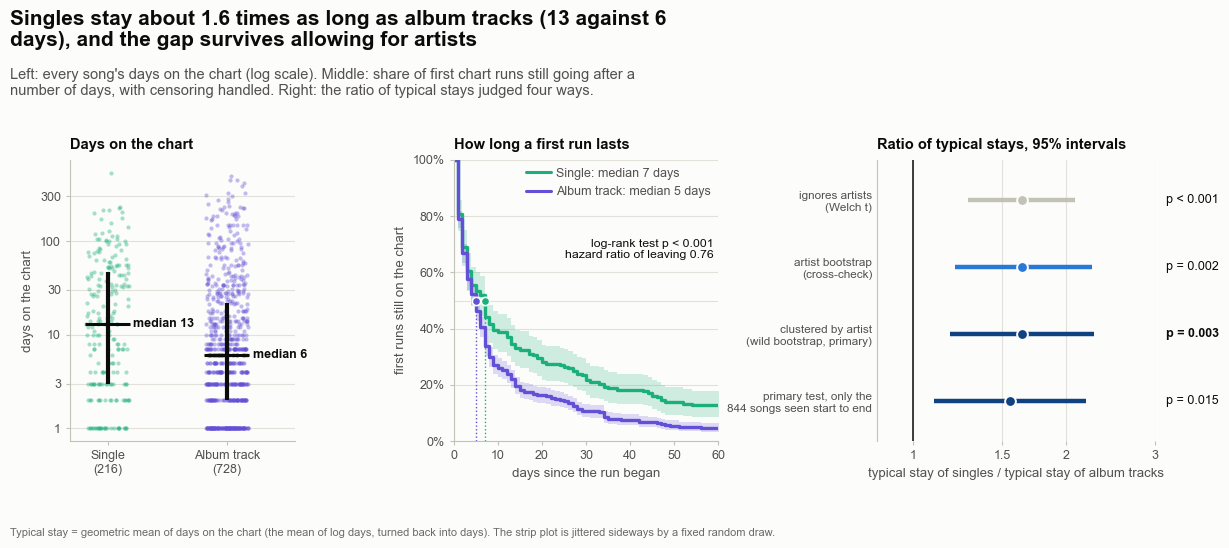

In [14]:
# Figure 05 - H2: how long singles and album tracks stay on the chart, three views
fig, (ax1, ax2, ax3) = make_fig(13.2, 5.6, 1, 3, left=0.95, right=1.4, bottom=0.95, wspace=0.62, panel_titles=True, width_ratios=[0.85, 1.0, 1.05],
                                title=f"Singles stay about {FACTS['h2_ratio']:.1f} times as long as album tracks ({FACTS['h2_median_single']:g} against {FACTS['h2_median_album']:g} days), "
                                      f"and the gap survives allowing for artists",
                                subtitle="Left: every song's days on the chart (log scale). Middle: share of first chart runs still going after a number of days, with censoring handled. "
                                         "Right: the ratio of typical stays judged four ways.",
                                note_text="Typical stay = geometric mean of days on the chart (the mean of log days, turned back into days). The strip plot is jittered sideways by a fixed random draw.")
colours = {"single": style.SINGLE_COLOR, "album": style.ALBUM_COLOR}
jitter = np.random.default_rng(SEED + 310).random(len(songs)) - 0.5
for position, (key, mask) in zip((0.0, 1.75), (("single", single), ("album", ~single))):
    ax1.scatter(position + 0.62 * jitter[mask], days[mask], s=9, color=colours[key], alpha=0.38, linewidth=0, zorder=2)
    q1, q2, q3 = np.percentile(days[mask], [25, 50, 75])
    ax1.vlines(position, q1, q3, color=style.INK, linewidth=3.0, zorder=3)
    ax1.hlines(q2, position - 0.33, position + 0.33, color=style.INK, linewidth=2.2, zorder=4)
    ax1.text(position + 0.38, q2, f"median {q2:g}", va="center", fontsize=9, color=style.INK, fontweight="bold")
ax1.set_yscale("log")
ax1.minorticks_off()
ax1.set_yticks([1, 3, 10, 30, 100, 300])
ax1.set_yticklabels(["1", "3", "10", "30", "100", "300"])
ax1.set_xticks([0, 1.75])
ax1.set_xticklabels([f"Single\n({FACTS['h2_n_single']})", f"Album track\n({FACTS['h2_n_album']})"])
ax1.set_xlim(-0.55, 2.75)
ax1.set_ylabel("days on the chart")
style_axes(ax1, grid="y")
panel_title(ax1, "Days on the chart")

for key, label in (("single", "Single"), ("album", "Album track")):
    curve = km[key]
    ax2.fill_between(curve["time"], curve["ci_low"] * 100, curve["ci_high"] * 100, step="post", color=colours[key], alpha=0.20, linewidth=0)
    ax2.step(curve["time"], curve["survival"] * 100, where="post", color=colours[key], linewidth=2.4)
    median = FACTS[f"h2_km_median_{key}"]
    ax2.vlines(median, 0, 50, color=colours[key], linewidth=1.0, linestyle=":")
    ax2.scatter([median], [50], s=36, color=colours[key], zorder=4, edgecolor=style.SURFACE, linewidth=1.2)
ax2.axhline(50, color=style.GRID, linewidth=0.8, zorder=0)
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(percent_formatter())
ax2.set_xlabel("days since the run began")
ax2.set_ylabel("first runs still on the chart")
style_axes(ax2, grid="y")
swatch_legend(ax2, [(f"Single: median {FACTS['h2_km_median_single']:g} days", colours["single"], "line"), (f"Album track: median {FACTS['h2_km_median_album']:g} days", colours["album"], "line")],
              loc="upper right")
direct_label(ax2, 59, 72, f"log-rank test {FACTS['h2_logrank_p_text']}\nhazard ratio of leaving {FACTS['h2_hr']:.2f}", ha="right", va="top", size=8.8, color=style.INK)
panel_title(ax2, "How long a first run lasts")

rows = [("ignores artists\n(Welch t)", FACTS["h2_ratio_naive"], FACTS["h2_naive_low"], FACTS["h2_naive_high"], FACTS["h2_welch_p_text"], style.AXIS),
        ("artist bootstrap\n(cross-check)", FACTS["h2_ratio"], FACTS["h2_boot_low"], FACTS["h2_boot_high"], FACTS["h2_boot_p_text"], style.BLUE_STEPS[450]),
        ("clustered by artist\n(wild bootstrap, primary)", FACTS["h2_ratio"], FACTS["h2_ratio_low"], FACTS["h2_ratio_high"], FACTS["h2_wild_p_text"], style.BLUE_STEPS[650]),
        (f"primary test, only the\n{FACTS['h2_complete_n']} songs seen start to end", FACTS["h2_complete_ratio"], FACTS["h2_complete_low"], FACTS["h2_complete_high"], FACTS["h2_complete_p_text"], style.BLUE_STEPS[650])]
ax3.axvline(1, color=style.INK, linewidth=1.1, zorder=1)
for row, (label, estimate, low, high, p_text, colour) in enumerate(rows):
    ax3.hlines(row, low, high, color=colour, linewidth=3.2, zorder=3)
    ax3.scatter([estimate], [row], s=60, color=colour, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
    ax3.annotate(p_text, xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=style.INK,
                 annotation_clip=False, fontweight="bold" if row == 2 else "normal")
ax3.set_xscale("log")
ax3.minorticks_off()
ax3.set_xticks([1, 1.5, 2, 3])
ax3.set_xticklabels(["1", "1.5", "2", "3"])
ax3.set_xlim(0.85, 3.0)
ax3.set_yticks(range(4))
ax3.set_yticklabels([r[0] for r in rows], fontsize=8.5)
ax3.set_ylim(3.6, -0.6)
ax3.set_xlabel("typical stay of singles / typical stay of album tracks")
style_axes(ax3, grid="x", bottom_spine=False)
ax3.tick_params(axis="y", length=0)
panel_title(ax3, "Ratio of typical stays, 95% intervals")
save_fig(fig, "p5_05_h2_singles_albums", FIG_DIR)
plt.show()

**What to notice**

- Half of the singles stayed 13 days or more against 6 for album tracks. In ratio terms, singles stay 1.64 times as long (95% interval 1.18 to 2.27).
- The planned tests overstate the evidence (p < 0.001 for Mann-Whitney, p < 0.001 for Welch) because they count 944 songs as independent. The primary test gives p = 0.003, still clearly significant. The direction does not change under any check: on ranks p = 0.008, on the 844 songs seen from start to end p = 0.015 (ratio 1.55).
- Cut-off runs are not the explanation: only 4% of the first runs were still going on the last day. The curves put the median first run at 7 days for singles and 5 for album tracks; the log-rank test gives p < 0.001 and a hazard ratio of 0.76 (on any given day a single is 0.76 times as likely to leave as an album track).
- The effect is real but modest: Cliff's delta is 0.18 (small). A randomly chosen single outlasts a randomly chosen album track in about 59% of pairs, so many album tracks do outlast singles. The verdict in Section 14 is *Supported*.

## Section 7 - H10 - Do explicit songs stay longer only among singles?

H2 compares singles with album tracks. H10 asks something more specific: does being explicit lengthen a song's stay *only* when the song is a single? That is a claim about a difference between two differences, which is called an **interaction**, and it is a different statistical question from asking whether each difference is significant on its own.

**What this code is.** The test of the interaction between release format (single or album track) and explicitness, on log days. The cell builds the four groups (single or album track, explicit or not), reports the median and the typical stay in each, and tests the interaction term of a two-way model. The interaction, turned back with the exponential function, is a *ratio of ratios*: (how many times longer explicit singles stay than other singles) divided by (how many times longer explicit album tracks stay than other album tracks). A value of 1 means that the explicit effect is the same in both formats.

**Why we need it.** Phase 4 saw that explicit singles had a longer median stay (16.5 days against 10) while for album tracks the pattern was reversed or flat (6 against 7). A common mistake is to conclude "explicit matters for singles (significant) and does not matter for album tracks (not significant), so the effects differ". Two results being on different sides of 0.05 does not show that they differ from each other; only a test of the difference can show that. That is what the interaction term is.

**What will happen.** The code runs the planned two-way model on log days and on ranks (songs treated as independent), then the primary version with standard errors clustered by artist and a wild bootstrap-t, an artist bootstrap for the interval, and the simple effect of explicit inside each format, each also with and without allowing for artists. It shows the table of the four groups, a table of five tests of the interaction and two sentences about the simple effects.

**Expected outcome.** Four groups of 104, 112, 391 and 337 songs, an interaction of about 1.8, and a p-value that is borderline: p = 0.019 when songs are treated as independent and a larger one when artists are allowed for.

**Motive.** Test the claim that was actually made. A claim about a difference needs a test of the difference.

In [15]:
# Section 7 - H10: do explicit songs stay longer only among singles? A 2 x 2 comparison with an interaction term
explicit = songs["is_explicit"].to_numpy()
cells = {"single, explicit": single & explicit, "single, not explicit": single & ~explicit,
         "album, explicit": ~single & explicit, "album, not explicit": ~single & ~explicit}
cell_keys = {"single, explicit": "se", "single, not explicit": "sc", "album, explicit": "ae", "album, not explicit": "ac"}
cell_table = pd.DataFrame({name: {"songs": int(mask.sum()), "median days": float(np.median(days[mask])), "typical stay (geometric mean, days)": float(np.exp(log_days[mask].mean()))}
                           for name, mask in cells.items()}).T
for name, key in cell_keys.items():
    FACTS[f"h10_n_{key}"] = int(cells[name].sum())
    FACTS[f"h10_median_{key}"] = float(np.median(days[cells[name]]))
    FACTS[f"h10_geo_{key}"] = float(np.exp(log_days[cells[name]].mean()))

# ---- the planned tests: a two-way model y = a + b + a*b with songs treated as independent, on log days and on ranks
planned = dependence.cluster_robust_interaction_test(log_days, single, explicit, None, name="interaction (songs treated as independent)")
planned_rank = dependence.cluster_robust_interaction_test(stats.rankdata(days), single, explicit, None, name="interaction on ranks (songs treated as independent)")

# ---- the primary test: the same interaction, standard errors clustered by artist, wild bootstrap-t
wild = dependence.wild_interaction_test(log_days, single, explicit, artist_codes, n_boot=N_BOOT, seed=SEED + 400)
wild_rank = dependence.wild_interaction_test(stats.rankdata(days), single, explicit, artist_codes, n_boot=N_BOOT, seed=SEED + 401, name="interaction on ranks (wild cluster bootstrap-t)")
interaction_boot = dependence.cluster_bootstrap(
    artist_codes, lambda w: ((w @ (log_days * cells["single, explicit"])) / (w @ cells["single, explicit"]) - (w @ (log_days * cells["single, not explicit"])) / (w @ cells["single, not explicit"]))
                          - ((w @ (log_days * cells["album, explicit"])) / (w @ cells["album, explicit"]) - (w @ (log_days * cells["album, not explicit"])) / (w @ cells["album, not explicit"])),
    n_boot=N_BOOT, seed=SEED + 402)
boot_low, boot_high = dependence.bootstrap_interval(interaction_boot)

# ---- the simple effects: explicit against not explicit, inside each release format
simple = {}
for label, mask, seed_offset in (("singles", single, 403), ("album tracks", ~single, 404)):
    naive = classical.two_sample_ttest(log_days[mask & explicit], log_days[mask & ~explicit])
    robust = dependence.wild_two_group_test(log_days[mask], explicit[mask], artist_codes[mask], n_boot=N_BOOT, seed=SEED + seed_offset)
    simple[label] = (naive, robust)

interaction_d = wild.estimate / float(log_days.std(ddof=1))                                      # the interaction in standard deviations of log days
for key, value in {"h10_d": interaction_d, "h10_d_word": effect_label("cohens_d", interaction_d), "h10_ratio_of_ratios": np.exp(wild.estimate), "h10_ror_low": np.exp(wild.ci_low), "h10_ror_high": np.exp(wild.ci_high),
                   "h10_ror_naive": np.exp(planned.estimate), "h10_naive_low": np.exp(planned.ci_low), "h10_naive_high": np.exp(planned.ci_high),
                   "h10_boot_low": np.exp(boot_low), "h10_boot_high": np.exp(boot_high), "h10_boot_p_text": format_p(dependence.bootstrap_p_value(interaction_boot)),
                   "h10_planned_p": planned.p_value, "h10_planned_p_text": format_p(planned.p_value), "h10_planned_rank_p_text": format_p(planned_rank.p_value),
                   "h10_wild_p": wild.p_value, "h10_wild_p_text": format_p(wild.p_value), "h10_wild_rank_p_text": format_p(wild_rank.p_value), "h10_wild_t": wild.statistic,
                   "h10_simple_single_ratio": np.exp(simple["singles"][1].estimate), "h10_simple_single_low": np.exp(simple["singles"][1].ci_low),
                   "h10_simple_single_high": np.exp(simple["singles"][1].ci_high), "h10_simple_single_p_text": format_p(simple["singles"][1].p_value),
                   "h10_simple_single_naive_p_text": format_p(simple["singles"][0].p_value),
                   "h10_simple_album_ratio": np.exp(simple["album tracks"][1].estimate), "h10_simple_album_low": np.exp(simple["album tracks"][1].ci_low),
                   "h10_simple_album_high": np.exp(simple["album tracks"][1].ci_high), "h10_simple_album_p_text": format_p(simple["album tracks"][1].p_value),
                   "h10_simple_album_naive_p_text": format_p(simple["album tracks"][0].p_value)}.items():
    FACTS[key] = value

display(cell_table)
rows = [("two-way model on log days, songs independent (planned)", planned.p_value, np.exp(planned.estimate), np.exp(planned.ci_low), np.exp(planned.ci_high)),
        ("same, on ranks (planned, rank-based)", planned_rank.p_value, np.nan, np.nan, np.nan),
        ("clustered by artist, wild bootstrap-t (primary)", wild.p_value, np.exp(wild.estimate), np.exp(wild.ci_low), np.exp(wild.ci_high)),
        ("same, on ranks", wild_rank.p_value, np.nan, np.nan, np.nan),
        ("artist bootstrap (cross-check)", dependence.bootstrap_p_value(interaction_boot), np.exp(wild.estimate), np.exp(boot_low), np.exp(boot_high))]
display(pd.DataFrame(rows, columns=["test of the interaction", "p-value", "ratio of ratios", "low", "high"]).set_index("test of the interaction"))
for label, (naive, robust) in simple.items():
    print(f"Explicit against not explicit among {label}: typical stay x{np.exp(robust.estimate):.2f} (interval {np.exp(robust.ci_low):.2f} to {np.exp(robust.ci_high):.2f}), "
          f"clustered p {format_p(robust.p_value)}, ignoring artists {format_p(naive.p_value)}")

,songs,median days,"typical stay (geometric mean, days)"
"single, explicit",104,16.5,14.54
"single, not explicit",112,10,10.63
"album, explicit",391,6,6.712
"album, not explicit",337,7,8.614


,p-value,ratio of ratios,low,high
test of the interaction,,,,
"two-way model on log days, songs independent (planned)",0.01874,1.756,1.098,2.808
"same, on ranks (planned, rank-based)",0.007941,NaN,NaN,NaN
"clustered by artist, wild bootstrap-t (primary)",0.0446,1.756,1.011,3.052
"same, on ranks",0.0356,NaN,NaN,NaN
artist bootstrap (cross-check),0.0496,1.756,1.001,3.05


Explicit against not explicit among singles: typical stay x1.37 (interval 0.89 to 2.11), clustered p p = 0.15, ignoring artists p = 0.15
Explicit against not explicit among album tracks: typical stay x0.78 (interval 0.55 to 1.11), clustered p p = 0.17, ignoring artists p = 0.028


**What this code is.** Figure 6. Left: the typical stay (geometric mean of days) of explicit and not explicit songs among singles and among album tracks, with 95% intervals that allow for artists; if explicitness had the same effect in both formats, the two lines would run parallel. Right: the explicit effect inside each format, and the difference between the two effects, as a ratio, with the planned and the primary interval.

**Why we need it.** The interaction is hard to see in numbers. Two lines that run apart or cross are the picture of an interaction, and the right panel shows how much of it is left after allowing for artists.

**What will happen.** The code computes the group intervals with a clustered regression, draws the two lines, draws the four rows on the right, and saves the picture as `p5_06_h10_interaction.png`.

**Expected outcome.** Two lines that are not parallel (the explicit line above the other for singles, a bit below it for album tracks), long vertical intervals, and on the right two simple effects that both include 1 and an interaction whose interval just clears 1.

**Motive.** Show the size of the difference, and how close it is to the line.

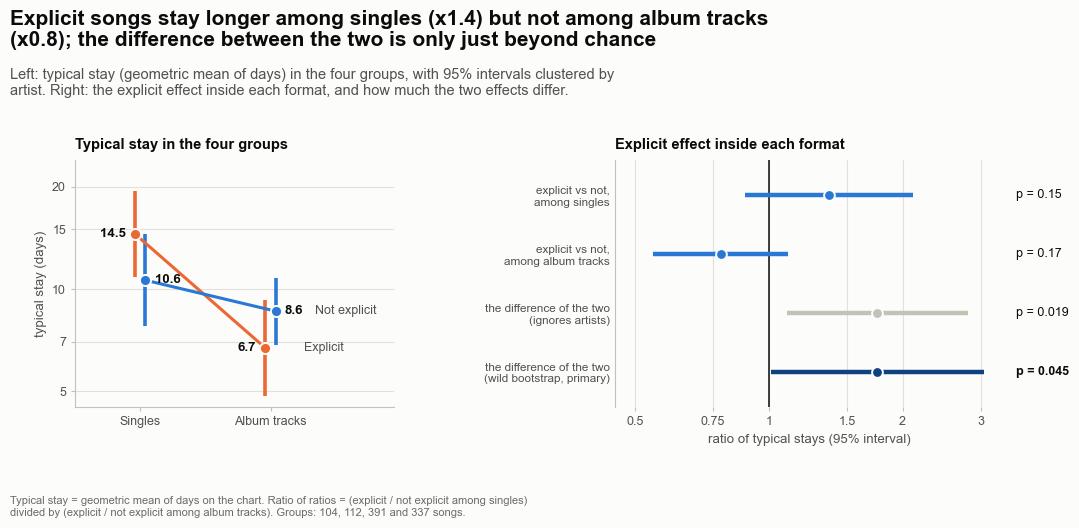

In [16]:
# Figure 06 - H10: typical stay by release format and explicitness (do the two lines run parallel?), and the difference of differences
fig, (ax1, ax2) = make_fig(11.8, 5.4, 1, 2, left=1.0, right=1.5, bottom=0.95, wspace=0.62, panel_titles=True, width_ratios=[0.9, 1.1],
                           title=f"Explicit songs stay longer among singles (x{FACTS['h10_simple_single_ratio']:.1f}) but not among album tracks (x{FACTS['h10_simple_album_ratio']:.1f}); the difference between the two is only just beyond chance",
                           subtitle="Left: typical stay (geometric mean of days) in the four groups, with 95% intervals clustered by artist. "
                                    "Right: the explicit effect inside each format, and how much the two effects differ.",
                           note_text=f"Typical stay = geometric mean of days on the chart. Ratio of ratios = (explicit / not explicit among singles) divided by (explicit / not explicit among album tracks). "
                                     f"Groups: {FACTS['h10_n_se']}, {FACTS['h10_n_sc']}, {FACTS['h10_n_ae']} and {FACTS['h10_n_ac']} songs.")
for flag, label, colour, offset in ((True, "Explicit", style.EXPLICIT_COLOR, -0.04), (False, "Not explicit", style.CLEAN_COLOR, 0.04)):
    xs, ys, lows, highs = [], [], [], []
    for position, mask in ((0, single), (1, ~single)):
        member = mask & (explicit == flag)
        fit = dependence.fit_ols(log_days[member], np.ones((int(member.sum()), 1)), artist_codes[member])
        result = dependence.coefficient_test(fit, 0)
        xs.append(position + offset); ys.append(np.exp(result.estimate)); lows.append(np.exp(result.ci_low)); highs.append(np.exp(result.ci_high))
    ax1.vlines(xs, lows, highs, color=colour, linewidth=2.6, zorder=2)
    ax1.plot(xs, ys, color=colour, linewidth=2.2, zorder=3)
    ax1.scatter(xs, ys, s=64, color=colour, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
    for x, y in zip(xs, ys):
        ax1.text(x + (-0.07 if flag else 0.07), y, f"{y:.1f}", ha="right" if flag else "left", va="center", fontsize=9.5, color=style.INK, fontweight="bold")
    ax1.text(xs[1] + (0.30 if flag else 0.30), ys[1], label, ha="left", va="center", fontsize=9, color=style.INK_2)
ax1.set_xlim(-0.5, 1.95)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(["Singles", "Album tracks"])
ax1.set_yscale("log")
ax1.minorticks_off()
ax1.set_yticks([5, 7, 10, 15, 20])
ax1.set_yticklabels(["5", "7", "10", "15", "20"])
ax1.set_ylim(4.5, 24)
ax1.set_ylabel("typical stay (days)")
style_axes(ax1, grid="y")
panel_title(ax1, "Typical stay in the four groups")

rows = [("explicit vs not,\namong singles", FACTS["h10_simple_single_ratio"], FACTS["h10_simple_single_low"], FACTS["h10_simple_single_high"], FACTS["h10_simple_single_p_text"], style.BLUE_STEPS[450]),
        ("explicit vs not,\namong album tracks", FACTS["h10_simple_album_ratio"], FACTS["h10_simple_album_low"], FACTS["h10_simple_album_high"], FACTS["h10_simple_album_p_text"], style.BLUE_STEPS[450]),
        ("the difference of the two\n(ignores artists)", FACTS["h10_ror_naive"], FACTS["h10_naive_low"], FACTS["h10_naive_high"], FACTS["h10_planned_p_text"], style.AXIS),
        ("the difference of the two\n(wild bootstrap, primary)", FACTS["h10_ratio_of_ratios"], FACTS["h10_ror_low"], FACTS["h10_ror_high"], FACTS["h10_wild_p_text"], style.BLUE_STEPS[650])]
ax2.axvline(1, color=style.INK, linewidth=1.1, zorder=1)
for row, (label, estimate, low, high, p_text, colour) in enumerate(rows):
    ax2.hlines(row, low, high, color=colour, linewidth=3.2, zorder=3)
    ax2.scatter([estimate], [row], s=60, color=colour, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
    ax2.annotate(p_text, xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=style.INK,
                 annotation_clip=False, fontweight="bold" if row == 3 else "normal")
ax2.set_xscale("log")
ax2.minorticks_off()
ax2.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
ax2.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3"])
ax2.set_xlim(0.45, 3.4)
ax2.set_yticks(range(4))
ax2.set_yticklabels([r[0] for r in rows], fontsize=8.5)
ax2.set_ylim(3.6, -0.6)
ax2.set_xlabel("ratio of typical stays (95% interval)")
style_axes(ax2, grid="x", bottom_spine=False)
ax2.tick_params(axis="y", length=0)
panel_title(ax2, "Explicit effect inside each format")
save_fig(fig, "p5_06_h10_interaction", FIG_DIR)
plt.show()

**What to notice**

- Explicit singles stay 14.5 days in the typical case against 10.6 for other singles. Among album tracks it is 6.7 against 8.6. The lines are not parallel.
- Neither simple effect is clear on its own once artists are allowed for: among singles explicit songs stay x1.37 as long (interval 0.89 to 2.11, p = 0.15), among album tracks x0.78 (0.55 to 1.11, p = 0.17). Ignoring artists, the album effect would have looked significant (p = 0.028) and in the opposite direction, which is one more reason not to trust the planned tests alone.
- The *difference* between the two effects is the claim of H10: a ratio of ratios of 1.76 with a 95% interval of 1.01 to 3.05. The planned test says p = 0.019, the primary test p = 0.045, the artist bootstrap p = 0.050. The lower end of the interval is right at 1, so the evidence is borderline, and it is a small effect (0.36 standard deviations of log days).
- In Section 14, with the correction for ten tests, the verdict of H10 is *Suggestive*.

## Section 8 - H3 - Does the popularity score differ between the Top 10, 11-20 and 21-50?

Popularity is measured for every song on every day, so the same song shows up hundreds of times. Comparing song-days would count one song again and again. The test therefore uses **one number per song**: the song's average popularity in its *home tier*, the tier in which it spent most of its days (a tie goes to the better tier). A second analysis then asks whether the gap between tiers is a gain from sitting high on the chart, or only a result of *which* songs sit where.

**What this code is.** The test of H3 and the checks around it. The unit is a song in its home tier. The planned tests are the one-way ANOVA (equal means), the Welch ANOVA (does not need equal spread), the Kruskal-Wallis test (ranks), Levene's test and an F-test on the spread, and Games-Howell pair tests. The primary test is an F test of equal means with standard errors clustered by artist and a wild bootstrap-t. The three pairs (Top 10 against 11-20, Top 10 against 21-50, 11-20 against 21-50) each get the same bootstrap and Holm's correction for three comparisons. Last comes the within-song check: the 277 songs that spent time in both the Top 10 and 21-50 are compared with themselves.

**Why we need it.** H3 says that popularity differs between tiers. A difference between tiers can mean two very different things: a song becomes more popular because it is high on the chart, or the songs that happen to be high on the chart were already more popular. Only the second reading is visible in a between-song comparison. The within-song comparison separates them, and it needs a second look that leaves out the first week of every run, because in that week the popularity score of a new song is still settling.

**What will happen.** The code finds each song's home tier, stores means, spreads and medians, runs the planned tests, the primary cluster-robust F test with 10,000 bootstrap repeats, the three pairs, and the within-song comparison for all days and for established days only (day 8 of a run or later), each with the paired t test, the Wilcoxon test and the artist-aware wild bootstrap. It displays the table of the three tiers, a table of six tests of equal means, the pairs and the two within-song sentences.

**Expected outcome.** Three groups of 83, 117 and 728 songs; very small p-values for the planned tests, a larger one (p = 0.002) for the primary test; pair differences with intervals; and a within-song gap that is small, or even negative.

**Motive.** Separate "the Top 10 holds more popular songs" from "being in the Top 10 makes a song more popular". Only the first can be said from this data.

In [17]:
# Section 8 - H3: does the popularity score differ between songs that live in the Top 10, 11-20 and 21-50?
rated = playlist.dropna(subset=["popularity_clean"])                                     # song-days that have a popularity score
by_tier = rated.groupby(["track_id", "rank_tier"], observed=True)["popularity_clean"].agg(mean="mean", days="size").reset_index()
home = (by_tier.sort_values(["track_id", "days", "rank_tier"], ascending=[True, False, True])          # the tier where a song spent most days; a tie goes to the better tier
        .drop_duplicates("track_id").merge(songs[["track_id", "artist"]], on="track_id"))
home["tier"] = home["rank_tier"].astype(str)
tier_names = list(RANK_TIER_LABELS)
tier_codes = {name: key for name, key in zip(tier_names, ("top10", "t20", "t50"))}
groups = [home.loc[home["tier"] == name, "mean"].to_numpy() for name in tier_names]
home_codes = pd.factorize(home["artist"])[0]
for name, values in zip(tier_names, groups):
    FACTS[f"h3_n_{tier_codes[name]}"] = len(values)
    FACTS[f"h3_mean_{tier_codes[name]}"] = float(values.mean())
    FACTS[f"h3_sd_{tier_codes[name]}"] = float(values.std(ddof=1))
    FACTS[f"h3_median_{tier_codes[name]}"] = float(np.median(values))
FACTS["h3_songs"] = len(home)
FACTS["h3_artists"] = int(home["artist"].nunique())

# ---- the planned tests (songs treated as independent)
anova = classical.one_way_anova(groups)
welch_a = classical.welch_anova(groups)
kruskal = classical.kruskal_wallis_test(groups)
levene = classical.levene_test(groups)
f_var = classical.f_test_two_variances(groups[0], groups[2])
dunn = classical.dunn_posthoc(groups, tier_names)
games = classical.games_howell(groups, tier_names)

# ---- the primary test: equal means for the three groups, standard errors clustered by artist, wild bootstrap-t (F statistic)
clustered_f = dependence.cluster_robust_k_group_test(home["mean"], home["tier"], home["artist"])
wild_f = dependence.wild_k_group_test(home["mean"].to_numpy(), home["tier"].to_numpy(), home_codes, n_boot=N_BOOT, seed=SEED + 500)
wild_rank_f = dependence.wild_k_group_test(stats.rankdata(home["mean"]), home["tier"].to_numpy(), home_codes, n_boot=N_BOOT, seed=SEED + 501,
                                           name="test of equal group ranks (wild cluster bootstrap-t)")
icc_home = dependence.intraclass_correlation(home["mean"], home["artist"])

# ---- the three pairs, each with the same wild bootstrap, and Holm's correction across the three
pairs = []
for first, second in ((0, 1), (0, 2), (1, 2)):
    mask = home["tier"].isin([tier_names[first], tier_names[second]]).to_numpy()
    result = dependence.wild_two_group_test(home.loc[mask, "mean"].to_numpy(), (home.loc[mask, "tier"] == tier_names[first]).to_numpy(),
                                            home_codes[mask], n_boot=N_BOOT, seed=SEED + 510 + first + second)
    pairs.append({"pair": f"{tier_names[first]} minus {tier_names[second]}", "difference": result.estimate, "low": result.ci_low, "high": result.ci_high, "p": result.p_value})
pairs = pd.DataFrame(pairs)
pairs["holm_p"] = adjust(pairs["p"], "holm")

# ---- the within-song check: the same song, in the Top 10 and in 21-50. Is the difference there too, or does it come from WHICH songs sit where?
wide = by_tier.pivot(index="track_id", columns="rank_tier", values="mean")
songs_both = wide[[tier_names[0], tier_names[2]]].dropna().join(songs.set_index("track_id")["artist"])
within = {}
for label, frame in (("all days", rated), ("established days (day 8 or later of a run)", rated[rated["days_in_stint"] > 7])):
    mean_by_tier = frame.groupby(["track_id", "rank_tier"], observed=True)["popularity_clean"].mean().unstack()
    both = mean_by_tier[[tier_names[0], tier_names[2]]].dropna().join(songs.set_index("track_id")["artist"])
    gap = (both[tier_names[0]] - both[tier_names[2]]).to_numpy()
    naive = classical.paired_ttest(both[tier_names[0]].to_numpy(), both[tier_names[2]].to_numpy())
    wilcoxon = classical.wilcoxon_signed_rank_test(both[tier_names[0]].to_numpy(), both[tier_names[2]].to_numpy())
    clustered = dependence.wild_cluster_bootstrap_test(gap, np.ones((len(gap), 1)), [1], both["artist"].to_numpy(), n_boot=N_BOOT, seed=SEED + 520 + len(within))
    within[label] = {"songs": len(gap), "mean_gap": float(gap.mean()), "naive_p": naive.p_value, "wilcoxon_p": wilcoxon.p_value, "result": clustered, "frame": both}
all_days, established = within["all days"], within["established days (day 8 or later of a run)"]
share_new = {name: float((rated.loc[rated["rank_tier"] == name, "days_in_stint"] <= 7).mean()) for name in tier_names}

for key, value in {"h3_f": anova.statistic, "h3_anova_p": anova.p_value, "h3_anova_p_text": format_p(anova.p_value), "h3_pair_top_vs_low_low": pairs.loc[1, "low"], "h3_pair_top_vs_low_high": pairs.loc[1, "high"], "h3_pair_top_vs_mid_low": pairs.loc[0, "low"], "h3_pair_top_vs_mid_high": pairs.loc[0, "high"], "h3_eta2": anova.detail["eta_squared"], "h3_eta2_pct": 100 * anova.detail["eta_squared"], "h3_eta2_word": effect_label("eta_squared", anova.detail["eta_squared"]),
                   "h3_omega2": anova.detail["omega_squared"], "h3_welch_f": welch_a.statistic, "h3_welch_p_text": format_p(welch_a.p_value),
                   "h3_kw_h": kruskal.statistic, "h3_kw_p_text": format_p(kruskal.p_value), "h3_eps2": kruskal.detail["epsilon_squared"],
                   "h3_eps2_word": effect_label("epsilon_squared", kruskal.detail["epsilon_squared"]),
                   "h3_levene_p_text": format_p(levene.p_value), "h3_fvar": f_var.estimate, "h3_fvar_p_text": format_p(f_var.p_value),
                   "h3_clustered_f": clustered_f.statistic, "h3_clustered_p_text": format_p(clustered_f.p_value), "h3_wild_f": wild_f.statistic,
                   "h3_wild_p": wild_f.p_value, "h3_wild_p_text": format_p(wild_f.p_value), "h3_wild_rank_p_text": format_p(wild_rank_f.p_value),
                   "h3_icc": icc_home["icc"], "h3_pair_top_vs_mid": pairs.loc[0, "difference"], "h3_pair_top_vs_low": pairs.loc[1, "difference"], "h3_pair_mid_vs_low": pairs.loc[2, "difference"],
                   "h3_pair_top_vs_mid_p_text": format_p(pairs.loc[0, "holm_p"]), "h3_pair_top_vs_low_p_text": format_p(pairs.loc[1, "holm_p"]), "h3_pair_mid_vs_low_p_text": format_p(pairs.loc[2, "holm_p"]),
                   "h3_within_n": all_days["songs"], "h3_within_gap_all": all_days["mean_gap"], "h3_within_gap_est": established["mean_gap"],
                   "h3_within_all_low": all_days["result"].ci_low, "h3_within_all_high": all_days["result"].ci_high,
                   "h3_within_est_low": established["result"].ci_low, "h3_within_est_high": established["result"].ci_high,
                   "h3_within_all_p_text": format_p(all_days["result"].p_value), "h3_within_est_p_text": format_p(established["result"].p_value),
                   "h3_within_est_n": established["songs"], "h3_new_share_top10": 100 * share_new[tier_names[0]], "h3_new_share_t50": 100 * share_new[tier_names[2]]}.items():
    FACTS[key] = value

display(pd.DataFrame({"songs": [len(g) for g in groups], "mean popularity": [g.mean() for g in groups], "sd": [g.std(ddof=1) for g in groups],
                      "median": [np.median(g) for g in groups]}, index=tier_names))
rows = [("one-way ANOVA (planned)", anova.p_value), ("Welch ANOVA (unequal spread)", welch_a.p_value), ("Kruskal-Wallis (planned)", kruskal.p_value),
        ("clustered by artist, t distribution", clustered_f.p_value), ("clustered by artist, wild bootstrap-t (primary)", wild_f.p_value), ("same, on ranks", wild_rank_f.p_value)]
display(pd.DataFrame(rows, columns=["test of equal popularity in the three tiers", "p-value"]).set_index("test of equal popularity in the three tiers"))
print(f"Spread: Levene (safe for skewed data) {FACTS['h3_levene_p_text']}; F-test of equal variances, Top 10 against 21-50: ratio {FACTS['h3_fvar']:.2f}, {FACTS['h3_fvar_p_text']}.")
display(pairs.set_index("pair").round(4))
display(games.round(4))
print(f"\nWithin the same song ({FACTS['h3_within_n']} songs seen in both the Top 10 and 21-50): Top 10 minus 21-50 is {FACTS['h3_within_gap_all']:+.2f} points over all days "
      f"and {FACTS['h3_within_gap_est']:+.2f} points on established days (day 8 or later of a run, {FACTS['h3_within_est_n']} songs).")
print(f"Share of song-days in the first week of a run: Top 10 {FACTS['h3_new_share_top10']:.0f}%, 21-50 {FACTS['h3_new_share_t50']:.0f}%.")

,songs,mean popularity,sd,median
Top 10,83,84.76,11.16,87.6
11-20,117,77.34,11.12,79.25
21-50,728,79.25,11.93,82.33


,p-value
test of equal popularity in the three tiers,
one-way ANOVA (planned),3.319e-05
Welch ANOVA (unequal spread),2.078e-05
Kruskal-Wallis (planned),3.769e-08
"clustered by artist, t distribution",0.0007423
"clustered by artist, wild bootstrap-t (primary)",0.0021
"same, on ranks",0.0022


Spread: Levene (safe for skewed data) p = 0.44; F-test of equal variances, Top 10 against 21-50: ratio 0.88, p = 0.46.


,difference,low,high,p,holm_p
pair,,,,,
Top 10 minus 11-20,7.418,3.153,11.68,0.0013,0.0039
Top 10 minus 21-50,5.51,-0.1449,11.17,0.0571,0.1142
11-20 minus 21-50,-1.908,-5.1,1.284,0.2574,0.2574


,group_a,group_b,difference,ci_low,ci_high,t,df,p
0,Top 10,11-20,7.418,3.638,11.2,4.638,176.3,0
1,Top 10,21-50,5.51,2.413,8.608,4.229,104.5,0.0001
2,11-20,21-50,-1.908,-4.555,0.7387,-1.705,162,0.2063



Within the same song (277 songs seen in both the Top 10 and 21-50): Top 10 minus 21-50 is -3.37 points over all days and +0.97 points on established days (day 8 or later of a run, 123 songs).
Share of song-days in the first week of a run: Top 10 20%, 21-50 36%.


**What this code is.** Figure 7. Left: one dot for every song, at its average popularity in its home tier, with the tier mean and its 95% interval (clustered by artist). Right: the three differences between tiers. The thin grey line of each row ignores artists (Games-Howell); the thick blue line allows for them. The Holm-adjusted p-value is written at the right.

**Why we need it.** The dots show how much the songs overlap between tiers, which is what the effect size really measures; the intervals show how sure we are about the averages; the right panel shows which of the three pairs carries the difference.

**What will happen.** The code draws the jittered dots, the means and intervals, and the three rows of pair differences, and saves the picture as `p5_07_h3_popularity_tiers.png`.

**Expected outcome.** Three clouds of dots that overlap heavily; the Top 10 cloud somewhat higher than the 11-20 cloud; one pair whose interval is clear of zero and two whose intervals are not.

**Motive.** Show the size of the effect next to the p-value, so that a small p does not look like a big difference.

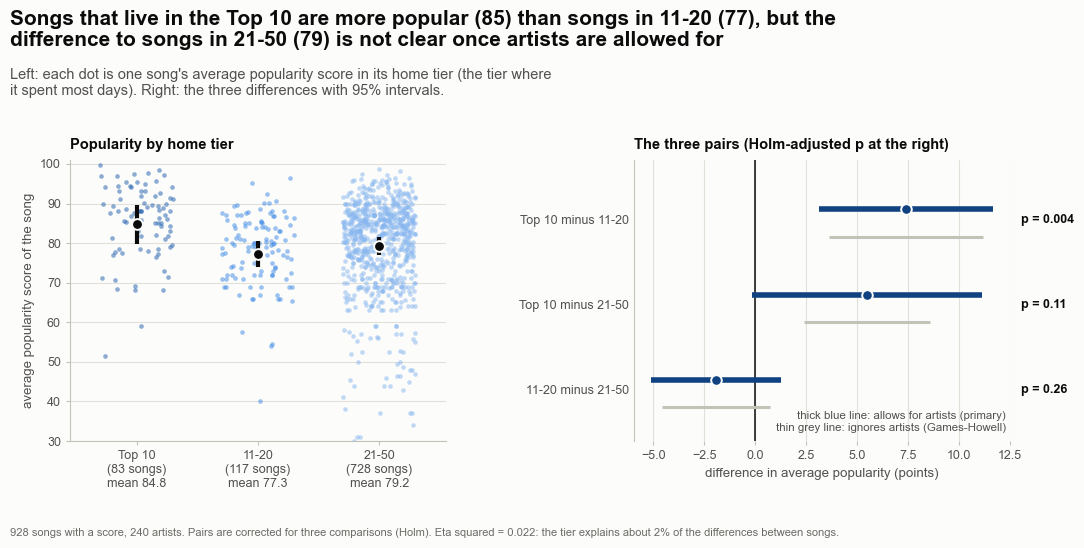

In [18]:
# Figure 07 - H3: popularity of songs by the tier they live in, and the three pairs
fig, (ax1, ax2) = make_fig(11.8, 5.6, 1, 2, left=0.95, right=1.45, bottom=0.95, wspace=0.5, panel_titles=True, width_ratios=[1.0, 1.0],
                           title=f"Songs that live in the Top 10 are more popular ({FACTS['h3_mean_top10']:.0f}) than songs in 11-20 ({FACTS['h3_mean_t20']:.0f}), "
                                 f"but the difference to songs in 21-50 ({FACTS['h3_mean_t50']:.0f}) is not clear once artists are allowed for",
                           subtitle=f"Left: each dot is one song's average popularity score in its home tier (the tier where it spent most days). "
                                    f"Right: the three differences with 95% intervals.",
                           note_text=f"{FACTS['h3_songs']} songs with a score, {FACTS['h3_artists']} artists. Pairs are corrected for three comparisons (Holm). "
                                     f"Eta squared = {FACTS['h3_eta2']:.3f}: the tier explains about {100 * FACTS['h3_eta2']:.0f}% of the differences between songs.")
tier_colours = [style.TIER_COLORS[name] for name in tier_names]
jitter3 = np.random.default_rng(SEED + 530).random(len(home)) - 0.5
home_x = home["tier"].map({name: i for i, name in enumerate(tier_names)}).to_numpy()
for i, (name, values) in enumerate(zip(tier_names, groups)):
    members = home_x == i
    ax1.scatter(i + 0.6 * jitter3[members], home.loc[members, "mean"], s=11, color=tier_colours[i], alpha=0.5, linewidth=0, zorder=2)
    fit = dependence.fit_ols(values, np.ones((len(values), 1)), home_codes[members])
    result = dependence.coefficient_test(fit, 0)
    ax1.vlines(i, result.ci_low, result.ci_high, color=style.INK, linewidth=3.0, zorder=3)
    ax1.scatter([i], [values.mean()], s=60, color=style.INK, zorder=4, edgecolor=style.SURFACE, linewidth=1.4)
ax1.set_xticks(range(3))
ax1.set_xticklabels([f"{name}\n({len(values)} songs)\nmean {values.mean():.1f}" for name, values in zip(tier_names, groups)])
ax1.set_xlim(-0.55, 2.55)
ax1.set_ylim(30, 101)
ax1.set_ylabel("average popularity score of the song")
style_axes(ax1, grid="y")
panel_title(ax1, "Popularity by home tier")

order = [(0, "Top 10 minus 11-20"), (1, "Top 10 minus 21-50"), (2, "11-20 minus 21-50")]
ax2.axvline(0, color=style.INK, linewidth=1.1, zorder=1)
for row, (index, label) in enumerate(order):
    naive = games.iloc[index]
    ax2.hlines(row + 0.2, naive["ci_low"], naive["ci_high"], color=style.AXIS, linewidth=2.2, zorder=2)
    ax2.hlines(row - 0.12, pairs.loc[index, "low"], pairs.loc[index, "high"], color=style.BLUE_STEPS[650], linewidth=4.0, zorder=3)
    ax2.scatter([pairs.loc[index, "difference"]], [row - 0.12], s=58, color=style.BLUE_STEPS[650], edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
    ax2.annotate(format_p(pairs.loc[index, "holm_p"]), xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points", va="center",
                 fontsize=9, color=style.INK, annotation_clip=False, fontweight="bold")
ax2.text(0.99, 0.03, "thick blue line: allows for artists (primary)\nthin grey line: ignores artists (Games-Howell)", transform=ax2.transAxes, fontsize=8.3,
         color=style.INK_2, va="bottom", ha="right")
ax2.set_yticks(range(3))
ax2.set_yticklabels([o[1] for o in order], fontsize=9)
ax2.set_ylim(2.6, -0.7)
ax2.set_xlabel("difference in average popularity (points)")
style_axes(ax2, grid="x", bottom_spine=False)
ax2.tick_params(axis="y", length=0)
panel_title(ax2, "The three pairs (Holm-adjusted p at the right)")
save_fig(fig, "p5_07_h3_popularity_tiers", FIG_DIR)
plt.show()

**What to notice**

- Songs whose home is the Top 10 average 84.8 points, songs in 11-20 77.3 and songs in 21-50 79.2. The ordering is not what the tiers suggest: 11-20 is the lowest, not 21-50.
- The planned tests all give p < 0.001. With artists allowed for, the F test gives p = 0.002 (the cluster-robust F is 7.4 against 10.4 for the plain ANOVA), still clearly significant. Songs of one artist are alike in popularity (intraclass correlation 0.34).
- Only one pair stands out: Top 10 minus 11-20 is +7.4 points (interval 3.2 to 11.7, Holm p = 0.004). Top 10 against 21-50 is +5.5 points with an interval that reaches -0.1 (p = 0.11), and 11-20 against 21-50 is -1.9 (p = 0.26).
- The effect is small. Eta squared is 0.022 (small): the tier accounts for about 2% of the differences between songs. The spread is about the same in all tiers (Levene p = 0.44), so the choice between ANOVA and Welch does not matter here.

**What this code is.** Figure 8, the within-song check. Each thin line joins one song's average popularity while it was in 21-50 (left) to its average while it was in the Top 10 (right), for the songs that were in both. Blue lines go up, red lines go down, and the thick black line joins the two averages. The left panel uses all days; the right panel leaves out the first week of every run.

**Why we need it.** If the Top 10 really lifted popularity, most lines would go up. If the between-song gap of Figure 7 only reflects which songs sit where, the lines would be flat or mixed. The second panel tests whether the first week of a run, when the score of a new song is still settling, is what drives the result.

**What will happen.** The code draws one line per song in each panel, the average line, and a caption under each panel with the number of songs, the mean gap, its 95% interval (wild bootstrap by artist) and its p-value. It saves the picture as `p5_08_h3_within_song.png`.

**Expected outcome.** A mix of blue and red lines in both panels. In the left panel the black line slopes down, in the right panel it is nearly flat.

**Motive.** Do not read a cause into a difference between groups when the same units can be compared with themselves.

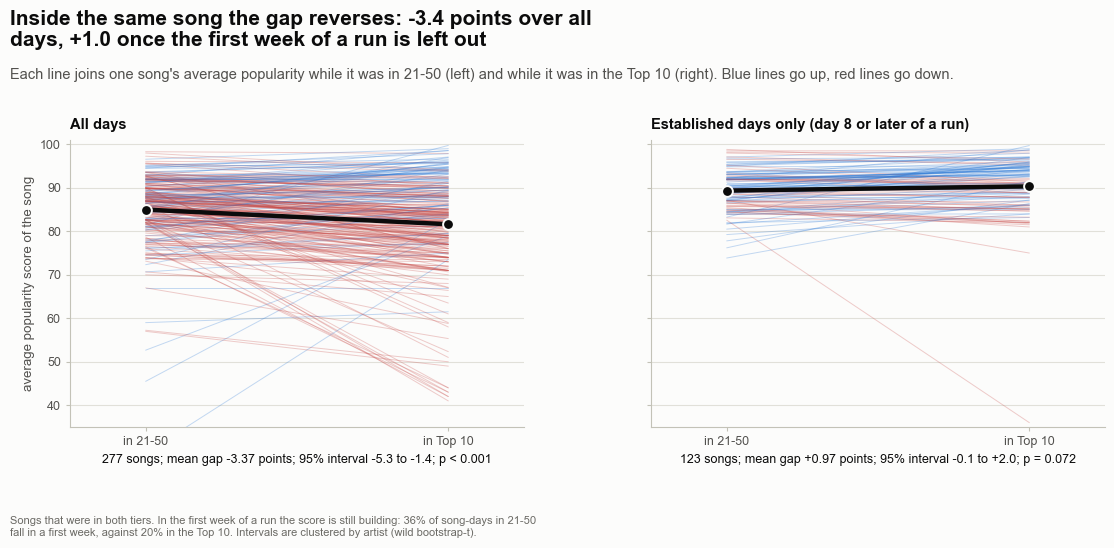

In [19]:
# Figure 08 - H3: the same song in the Top 10 and in 21-50. Does the popularity gap survive when the first week of a run is left out?
fig, (ax1, ax2) = make_fig(11.8, 5.6, 1, 2, left=0.95, right=0.5, bottom=0.95, wspace=0.28, panel_titles=True, sharey=True,
                           title=f"Inside the same song the gap reverses: {FACTS['h3_within_gap_all']:+.1f} points over all days, {FACTS['h3_within_gap_est']:+.1f} once the first week of a run is left out",
                           subtitle="Each line joins one song's average popularity while it was in 21-50 (left) and while it was in the Top 10 (right). Blue lines go up, red lines go down.",
                           note_text=f"Songs that were in both tiers. In the first week of a run the score is still building: {FACTS['h3_new_share_t50']:.0f}% of song-days in 21-50 fall in a first week, against "
                                     f"{FACTS['h3_new_share_top10']:.0f}% in the Top 10. Intervals are clustered by artist (wild bootstrap-t).")
for ax, (label, entry), title in ((ax1, list(within.items())[0], "All days"), (ax2, list(within.items())[1], "Established days only (day 8 or later of a run)")):
    frame = entry["frame"]
    low_tier, top_tier = frame[tier_names[2]].to_numpy(), frame[tier_names[0]].to_numpy()
    for start, end in zip(low_tier, top_tier):
        ax.plot([0, 1], [start, end], color=style.UP_COLOR if end >= start else style.DOWN_COLOR, linewidth=0.7, alpha=0.28, zorder=2)
    ax.plot([0, 1], [low_tier.mean(), top_tier.mean()], color=style.INK, linewidth=3.2, zorder=4)
    ax.scatter([0, 1], [low_tier.mean(), top_tier.mean()], s=60, color=style.INK, zorder=5, edgecolor=style.SURFACE, linewidth=1.4)
    ax.set_xlabel(f"{len(frame)} songs; mean gap {entry['mean_gap']:+.2f} points; 95% interval {entry['result'].ci_low:+.1f} to {entry['result'].ci_high:+.1f}; "
                  f"{format_p(entry['result'].p_value)}", fontsize=9, color=style.INK)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"in {tier_names[2]}", f"in {tier_names[0]}"])
    ax.set_xlim(-0.25, 1.25)
    style_axes(ax, grid="y")
    panel_title(ax, title)
ax1.set_ylim(35, 101)
ax1.set_ylabel("average popularity score of the song")
save_fig(fig, "p5_08_h3_within_song", FIG_DIR)
plt.show()

**What to notice**

- Over all days the same songs are *less* popular while in the Top 10 than while in 21-50: the gap (Top 10 minus 21-50) is -3.4 points (277 songs, interval -5.3 to -1.4, p < 0.001). The between-song gap of Figure 7 points the other way.
- With the first week of every run left out the gap becomes +1.0 points (interval -0.1 to 2.0, p = 0.072, 123 songs). So the answer depends on that first week, in which the score of a new song is still settling, and it never shows a clear gain from sitting in the Top 10.
- Taken together: the Top 10 holds songs that are more popular on average than songs in 11-20 (about 7 points), but this is a statement about *which songs* are there. The data do not show that a song becomes more popular because it is there.
- In Section 14, the verdict of H3 is *Supported*, with a small effect. Read it as "the tiers differ a little in popularity", not as "the Top 10 makes songs popular".

## Section 9 - H4 - Has the average popularity of the chart fallen?

Here the unit is a day. The daily average popularity is one number per snapshot day, and each day is much like the day before (Section 3). So the straight-line trend test of the plan would be far too eager: it believes that 555 days are 555 independent pieces of evidence. The primary test resamples **blocks of 14 consecutive days**, which keeps the day-to-day correlation inside the resampled series.

**What this code is.** The test of H4 on two versions of the daily series: the average popularity of all songs on the chart, and the average over *established* songs only (song-days from day 8 of a run onwards). For each series the cell runs the planned tests (a straight-line trend test that counts days as independent, and a Welch t test of the first 28 days against the last 28 days), the primary test (the same straight line, with the p-value and interval from a **residual block bootstrap** in blocks of 14 days), and two checks: the straight line with a Newey-West standard error and the Mann-Kendall trend test with a Theil-Sen slope, which uses no straight-line assumption at all.

**Why we need it.** Phase 4 saw that the daily average fell. There are two ways in which that could be misleading. First, every new release brings songs whose score has not settled yet, so more releases in the second half could lower the average without any song losing popularity: the established-songs series removes that. Second, days are correlated: the placebo experiment of Section 3 showed that a straight-line test of a series like this raises a false alarm in about one run in three.

**What will happen.** The code leaves out days without a value (it does not fill them in), fits the line, measures how strongly each day's leftover is correlated with the day before, and runs the tests above with 10,000 bootstrap repeats. It also recomputes the first-28-days and last-28-days averages of Phase 4 and asserts that they match. It shows a table of four tests for each series and a table of the windows, then sentences about the size of the fall.

**Expected outcome.** A fall of a few tenths of a point per 100 days for both series, a planned p-value that is very small, and a primary p-value that is larger. The leftover correlation from day to day is high (0.57), which is why the planned test overstates the evidence.

**Motive.** Test the trend that the days support, not the one that a naive count of 555 independent days would give.

In [20]:
# Section 9 - H4: has the average popularity of the chart fallen over the period?
established = rated[rated["days_in_stint"] > 7]                                                 # song-days of songs that have been on the chart for more than a week
daily_old = established.groupby("date")["popularity_clean"].mean().reindex(daily["date"])      # the same daily average, without the first week of every run
series = {"all songs": daily_pop, "established songs": daily_old}
series_keys = {"all songs": "all", "established songs": "est"}
FACTS["h4_est_missing_days"] = int(daily_old.isna().sum())                                      # days on which no song was past its first week (the start of the file, New Year)


def welch_independent_days(first, last, rho):
    """Welch's t test of two windows of a daily series, counting only the independent days: n is replaced by n (1 - rho) / (1 + rho)."""
    n1 = max(2.0, dependence.effective_sample_size_ar1(len(first), rho))
    n2 = max(2.0, dependence.effective_sample_size_ar1(len(last), rho))
    a, b = first.var(ddof=1) / n1, last.var(ddof=1) / n2
    df = (a + b) ** 2 / (a ** 2 / (n1 - 1) + b ** 2 / (n2 - 1))
    t_value = (first.mean() - last.mean()) / np.sqrt(a + b)
    return float(2 * stats.t.sf(abs(t_value), df)), n1, n2


trend = {}
for name, values in series.items():
    key = series_keys[name]
    valid = values.notna().to_numpy()
    y = values.to_numpy(dtype=float)[valid]                                                     # days without a value are left out, not filled in
    dates = daily["date"].to_numpy()[valid]
    x = np.arange(len(y))
    residuals = y - np.polyval(np.polyfit(x, y, 1), x)
    rho = dependence.autocorrelation(residuals)                                                 # day-to-day correlation of what the line does not explain
    first28 = values.to_numpy(dtype=float)[:28][valid[:28]]                                     # the first and the last 28 calendar days of the file (as in Phase 4)
    last28 = values.to_numpy(dtype=float)[-28:][valid[-28:]]
    welch = classical.two_sample_ttest(first28, last28)
    p_eff, n1_eff, n2_eff = welch_independent_days(first28, last28, rho)
    ols = dependence.cluster_robust_slope_test(y, x, None)                                      # the planned straight-line test: days treated as independent
    hac = dependence.hac_trend_test(y)                                                          # a check: Newey-West standard error
    slopes = dependence.block_bootstrap_trend(y, block=14, n_boot=N_BOOT, seed=SEED + 600 + len(trend))
    block_low, block_high = dependence.bootstrap_interval(slopes)                              # the bootstrap slopes are centred on the observed slope
    block_p = dependence.bootstrap_p_value(slopes)
    kendall = dependence.mann_kendall_trend(y)
    trend[name] = {"y": y, "dates": dates, "rho": rho, "first": float(first28.mean()), "last": float(last28.mean()), "welch": welch, "p_eff": p_eff,
                   "ols": ols, "hac": hac, "block": (block_low, block_high, block_p), "kendall": kendall}
    for field, value in {"days": len(y), "first28": float(first28.mean()), "last28": float(last28.mean()), "change28": float(last28.mean() - first28.mean()),
                         "slope100": 100 * hac.estimate, "slope100_low": 100 * hac.ci_low, "slope100_high": 100 * hac.ci_high,
                         "total_change": hac.estimate * (len(y) - 1), "fall100": -100 * hac.estimate, "fall_total": -hac.estimate * (len(y) - 1), "ols_low": 100 * ols.ci_low, "ols_high": 100 * ols.ci_high,
                         "block_low": 100 * block_low, "block_high": 100 * block_high, "tau": kendall.detail["tau"],
                         "ts_slope100": 100 * kendall.estimate, "ts_low": 100 * kendall.ci_low, "ts_high": 100 * kendall.ci_high,
                         "ols_p": ols.p_value, "hac_p": hac.p_value, "hac_p_text": format_p(hac.p_value), "primary_p": block_p, "primary_p_text": format_p(block_p), "ols_p_text": format_p(ols.p_value), "welch_p_text": format_p(welch.p_value),
                         "welch_eff_p_text": format_p(p_eff), "block_p_text": format_p(block_p), "mk_p_text": format_p(kendall.p_value),
                         "rho_resid": rho, "n_eff_28": n1_eff, "lags": hac.detail["lags"], "se_ratio": hac.detail["se"] / hac.detail["naive_se"],
                         "tau_word": effect_label("correlation", kendall.detail["tau"])}.items():
        FACTS[f"h4_{key}_{field}"] = value
if p4_file.exists():                                                                             # the windows must give the numbers of Phase 4
    assert abs(FACTS["h4_all_first28"] - p4["trend_first_28"]) < 1e-9 and abs(FACTS["h4_est_last28"] - p4["trend_old_last_28"]) < 1e-9

rows = []
for name, t in trend.items():
    rows += [(name, "straight line, days independent (planned)", 100 * t["ols"].estimate, 100 * t["ols"].ci_low, 100 * t["ols"].ci_high, t["ols"].p_value),
             (name, "straight line, Newey-West (check)", 100 * t["hac"].estimate, 100 * t["hac"].ci_low, 100 * t["hac"].ci_high, t["hac"].p_value),
             (name, "block bootstrap (primary)", 100 * t["hac"].estimate, 100 * t["block"][0], 100 * t["block"][1], t["block"][2]),
             (name, "Mann-Kendall with Theil-Sen slope (days independent)", 100 * t["kendall"].estimate, 100 * t["kendall"].ci_low, 100 * t["kendall"].ci_high, t["kendall"].p_value)]
display(pd.DataFrame(rows, columns=["series", "test", "points per 100 days", "low", "high", "p-value"]).set_index(["series", "test"]))
display(pd.DataFrame({"first 28 days": [t["first"] for t in trend.values()], "last 28 days": [t["last"] for t in trend.values()],
                      "Welch t, days independent": [t["welch"].p_value for t in trend.values()], "Welch t, independent days only": [t["p_eff"] for t in trend.values()]},
                     index=list(trend)))
print(f"\nLag-1 correlation of what the line leaves unexplained: {trend['all songs']['rho']:.2f}. The Newey-West standard error ({FACTS['h4_all_lags']} lags) is "
      f"{FACTS['h4_all_se_ratio']:.1f} times the one that treats days as independent. The established series has {FACTS['h4_est_missing_days']} days without a value (left out).")

points per 100 days     low    high   p-value
series            test                                                                                             
all songs         straight line, days independent (planned)                       -0.4671 -0.6006 -0.3337 1.663e-11
                  straight line, Newey-West (check)                               -0.4671 -0.6497 -0.2846 6.769e-07
                  block bootstrap (primary)                                       -0.4671 -0.7576 -0.1741    0.0022
                  Mann-Kendall with Theil-Sen slope (days indepen...              -0.4748 -0.5641  -0.386 5.975e-21
established songs straight line, days independent (planned)                          -0.6 -0.6778 -0.5222 1.767e-43
                  straight line, Newey-West (check)                                  -0.6 -0.7287 -0.4713 1.096e-18
                  block bootstrap (primary)                                          -0.6  -0.829 -0.3671    0.0002
                  Mann-Kendall with Theil-Sen slope (days indepen...              -0.5894 -0.6596 -0.5201 2.693e-43

,first 28 days,last 28 days,"Welch t, days independent","Welch t, independent days only"
all songs,89.4,86.17,5.346e-07,0.01153
established songs,90.87,88.97,1.033e-17,0.03777



Lag-1 correlation of what the line leaves unexplained: 0.57. The Newey-West standard error (5 lags) is 1.4 times the one that treats days as independent. The established series has 13 days without a value (left out).


**What this code is.** Figure 9. The daily average popularity of all songs and of established songs as two lines over the whole period, each with its straight-line trend, and a lower panel with the slope per 100 days and its 95% interval, judged four ways: by the planned straight-line test that counts days as independent, by the Newey-West version, by the primary block bootstrap and by the Mann-Kendall test with a Theil-Sen slope.

**Why we need it.** A trend is easiest to judge by eye on the series itself, with the line drawn on it. The slope panel shows how much wider the honest interval is than the planned one.

**What will happen.** The code draws the series, the fitted lines and the labels, then the slope intervals, and saves the picture as `p5_09_h4_trend.png`.

**Expected outcome.** A noisy line with a gentle downward slope, a second line (established songs) that sits above it and follows the same course, and slope intervals that get wider from the planned test to the primary one.

**Motive.** Let the reader see both how big the fall is and how noisy the series is.

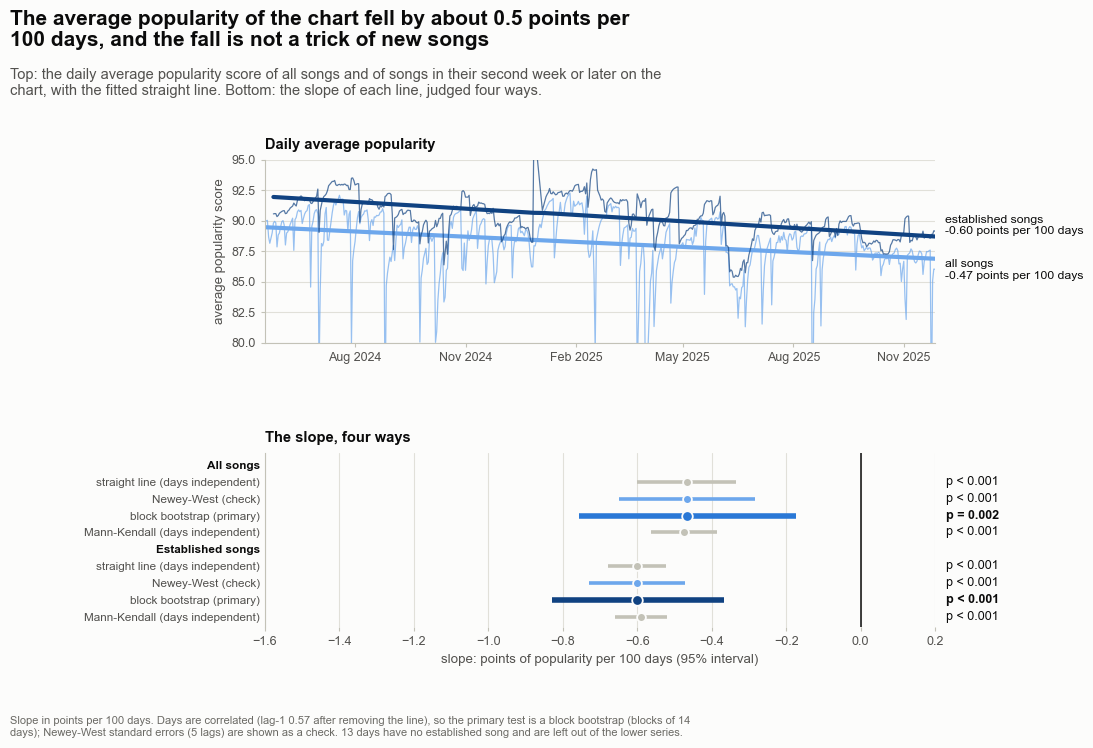

In [21]:
# Figure 09 - H4: the daily average popularity with its fitted trend, and the slope judged four ways for two versions of the series
fig, (ax1, ax2) = make_fig(11.8, 7.6, 2, 1, left=2.9, right=2.2, bottom=0.95, hspace=0.62, height_ratios=[1.05, 1], panel_titles=True,
                           title=f"The average popularity of the chart fell by about {abs(FACTS['h4_all_slope100']):.1f} points per 100 days, and the fall is not a trick of new songs",
                           subtitle="Top: the daily average popularity score of all songs and of songs in their second week or later on the chart, with the fitted straight line. "
                                    "Bottom: the slope of each line, judged four ways.",
                           note_text=f"Slope in points per 100 days. Days are correlated (lag-1 {FACTS['h4_all_rho_resid']:.2f} after removing the line), so the primary test is a block bootstrap (blocks of 14 days); Newey-West standard errors "
                                     f"({FACTS['h4_all_lags']} lags) are shown as a check. {FACTS['h4_est_missing_days']} days have no established song and are left out of the lower series.")
colours4 = {"all songs": style.BLUE_STEPS[300], "established songs": style.BLUE_STEPS[650]}
for name, t in trend.items():
    ax1.plot(t["dates"], t["y"], color=colours4[name], linewidth=0.9, alpha=0.7)
    fitted = np.polyval(np.polyfit(np.arange(len(t["y"])), t["y"], 1), np.arange(len(t["y"])))
    ax1.plot(t["dates"], fitted, color=colours4[name], linewidth=3.0)
    ax1.text(t["dates"][-1] + np.timedelta64(8, "D"), fitted[-1] + (0.9 if name == "established songs" else -0.9), f"{name}\n{t['hac'].estimate * 100:+.2f} points per 100 days",
             va="center", fontsize=8.8, color=style.INK)
ax1.set_xlim(daily["date"].min(), daily["date"].max())
ax1.set_ylim(80, 95)
ax1.set_ylabel("average popularity score")
ax1.xaxis.set_major_formatter(__import__("matplotlib.dates", fromlist=["DateFormatter"]).DateFormatter("%b %Y"))
ax1.xaxis.set_major_locator(__import__("matplotlib.dates", fromlist=["MonthLocator"]).MonthLocator(interval=3))
style_axes(ax1, grid="y")
panel_title(ax1, "Daily average popularity")

entries = []                                                                                       # ("header", text) or ("row", label, estimate, low, high, p text, colour, primary?)
for name, t in trend.items():
    primary_colour = style.BLUE_STEPS[650] if name == "established songs" else style.BLUE_STEPS[450]
    entries += [("header", name.capitalize()),
                ("row", "straight line (days independent)", 100 * t["ols"].estimate, 100 * t["ols"].ci_low, 100 * t["ols"].ci_high, format_p(t["ols"].p_value), style.AXIS, False),
                ("row", "Newey-West (check)", 100 * t["hac"].estimate, 100 * t["hac"].ci_low, 100 * t["hac"].ci_high, format_p(t["hac"].p_value), style.BLUE_STEPS[300], False),
                ("row", "block bootstrap (primary)", 100 * t["hac"].estimate, 100 * t["block"][0], 100 * t["block"][1], format_p(t["block"][2]), primary_colour, True),
                ("row", "Mann-Kendall (days independent)", 100 * t["kendall"].estimate, 100 * t["kendall"].ci_low, 100 * t["kendall"].ci_high, format_p(t["kendall"].p_value), style.AXIS, False)]
ax2.axvline(0, color=style.INK, linewidth=1.1, zorder=1)
tick_positions, tick_labels, header_positions = [], [], []
for position, entry in enumerate(entries):
    tick_positions.append(position)
    if entry[0] == "header":
        tick_labels.append(entry[1])
        header_positions.append(position)
        continue
    _, label, estimate, low, high, p_text, colour, is_primary = entry
    tick_labels.append(label)
    ax2.hlines(position, low, high, color=colour, linewidth=4.0 if is_primary else 2.6, zorder=3)
    ax2.scatter([estimate], [position], s=58 if is_primary else 40, color=colour, edgecolor=style.SURFACE, linewidth=1.3, zorder=4)
    ax2.annotate(p_text, xy=(1.0, position), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=style.INK,
                 annotation_clip=False, fontweight="bold" if is_primary else "normal")
ax2.set_yticks(tick_positions)
ax2.set_yticklabels(tick_labels, fontsize=8.5)
for position in header_positions:
    ax2.get_yticklabels()[position].set_fontweight("bold")
    ax2.get_yticklabels()[position].set_color(style.INK)
ax2.set_ylim(len(entries) - 0.4, -0.7)
ax2.set_xlim(-1.6, 0.2)
ax2.set_xlabel("slope: points of popularity per 100 days (95% interval)")
style_axes(ax2, grid="x", bottom_spine=False)
ax2.tick_params(axis="y", length=0)
panel_title(ax2, "The slope, four ways")
save_fig(fig, "p5_09_h4_trend", FIG_DIR)
plt.show()

**What to notice**

- The average popularity of the chart fell by about 0.47 points per 100 days (2.6 points over the 555 days). In the primary test the slope has a 95% interval of -0.76 to -0.17 per 100 days, and the p-value is p = 0.002.
- The planned straight-line test gives p < 0.001 because it counts every day as new evidence; the leftover of the line is correlated at 0.57 from one day to the next. The Newey-West check gives p < 0.001 and the Mann-Kendall test p < 0.001. The honest p-value is larger than the planned one, but the direction does not change.
- The fall is not a trick of new songs. Leaving out the first week of every run (established songs only) the slope is -0.60 per 100 days (p < 0.001) over 542 days that have a value.
- The change is small in absolute terms. Kendall's tau is -0.27 (small), and the first 28 days average 89.4 against 86.2 for the last 28. Section 15 checks whether the fall appears in both halves of the period, or only in one of them.

## Section 10 - H5 - Does the entry position change how long a chart run lasts?

The unit here is a **chart run**: a stretch of consecutive days on the chart. A song can have several runs (it leaves and comes back), and runs of one artist are alike, so the primary test again resamples whole artists. Only *complete* runs are used (both the first and the last day are inside the file), because a run that is cut off by the edge of the file has not finished.

**What this code is.** The test of H5 and its checks. Runs are sorted into five bands by the place where they began (1-10, 11-20, 21-30, 31-40, 41-50). The planned test is Kruskal-Wallis with Dunn's pair tests. The primary test is an F test on the *ranks* of run length with standard errors clustered by artist and a wild bootstrap-t; all ten pairs of bands get the same bootstrap and Holm's correction for ten comparisons. The size of the link is the rank correlation between entry place and run length with an artist bootstrap interval, and the typical length per band (geometric mean) is stored for the figure. Four checks follow: the test on log days, the test on only the first complete run of each song, Kaplan-Meier curves with a log-rank test that include runs cut off by the end of the file, and a test of runs of the *same artist* only.

**Why we need it.** H5 was suggested by Phase 4: runs that begin high last longer. Three objections need an answer. First, one artist with many runs could produce the whole result: the same-artist check compares an artist with itself, and the first-run check lets every song count once. Second, runs still going on the last day are not finished: the Kaplan-Meier check counts them correctly. Third, the link is partly built in: a run that begins at place 45 can end after dropping five places, while a run that begins at place 3 has a long way to fall. That does not make the result false, but it matters for how it is read.

**What will happen.** The code builds the run table with the band of each run, stores medians, shares of runs that last a week or more and the numbers of runs, runs the planned and primary tests with 10,000 bootstrap repeats, the ten pairs, the rank correlation and its interval, the typical lengths and the four checks. It displays a table of the five bands, a table of six tests of equal run lengths, the grid of ten pairs and three sentences.

**Expected outcome.** Five bands with 224, 198, 153, 223 and 1083 runs, medians from 12.5 days (began in 1-10) down to 3 (began in 41-50), p-values that are tiny in every test (the primary one is at the smallest value the bootstrap can give), and a rank correlation of about -0.36.

**Motive.** A strong result deserves the hardest questions. This is where the notebook asks them.

In [22]:
# Section 10 - H5: does the entry position change how long a chart run lasts?
band_edges = [0, 10, 20, 30, 40, 50]                                                       # five bands of ten places, the same as in Phase 4
band_names = ["1-10", "11-20", "21-30", "31-40", "41-50"]
band_keys = ["b1", "b2", "b3", "b4", "b5"]
done = runs[runs["complete"]].copy()                                                        # complete runs only: both ends of the run are inside the file
done["band"] = pd.cut(done["entry_position"], band_edges, labels=band_names).astype(str)
run_length = done["length"].to_numpy(dtype=float)
run_band = done["band"].to_numpy()
run_artist = pd.factorize(done["artist"])[0]
run_rank = stats.rankdata(run_length)                                                       # ranks of the run lengths (ties share their average rank)
run_groups = [run_length[run_band == name] for name in band_names]

# ---- what the data look like (these numbers must agree with Phase 4)
FACTS["h5_runs"], FACTS["h5_artists"] = len(done), int(done["artist"].nunique())
for name, key, values in zip(band_names, band_keys, run_groups):
    FACTS[f"h5_n_{key}"] = len(values)
    FACTS[f"h5_median_{key}"] = float(np.median(values))
    FACTS[f"h5_week_pct_{key}"] = 100 * float((values >= 7).mean())
rho = stats.spearmanr(done["entry_position"], run_length)[0]
FACTS["h5_rho"] = float(rho)
if p4_file.exists():
    for key in band_keys:
        assert abs(FACTS[f"h5_median_{key}"] - p4[f"run_median_{key}"]) < 1e-9, "the run medians differ from Phase 4"
        assert abs(FACTS[f"h5_week_pct_{key}"] - p4[f"run_week_pct_{key}"]) < 1e-9, "the shares of runs lasting a week differ from Phase 4"
    assert abs(rho - p4["run_corr_entry_length"]) < 1e-12, "the rank correlation differs from Phase 4"

# ---- the planned tests: runs treated as independent
kruskal5 = classical.kruskal_wallis_test(run_groups)
dunn5 = classical.dunn_posthoc(run_groups, band_names)

# ---- the primary test: equal average ranks in the five bands, standard errors clustered by artist, wild bootstrap-t (F statistic)
clustered5 = dependence.cluster_robust_k_group_test(run_rank, run_band, done["artist"])
wild5 = dependence.wild_k_group_test(run_rank, run_band, run_artist, n_boot=N_BOOT, seed=SEED + 600)
wild5_log = dependence.wild_k_group_test(np.log(run_length), run_band, run_artist, n_boot=N_BOOT, seed=SEED + 601,
                                         name="test of equal group means of log days (wild cluster bootstrap-t)")
icc5 = dependence.intraclass_correlation(run_rank, done["artist"])

# ---- the ten pairs of bands, each with the same wild bootstrap (difference in average rank), and Holm's correction across the ten
pair_rows = []
for first in range(5):
    for second in range(first + 1, 5):
        mask = np.isin(run_band, [band_names[first], band_names[second]])
        result = dependence.wild_two_group_test(run_rank[mask], run_band[mask] == band_names[first], run_artist[mask], n_boot=N_BOOT, seed=SEED + 610 + 10 * first + second)
        pair_rows.append({"first": band_names[first], "second": band_names[second], "difference": result.estimate, "low": result.ci_low, "high": result.ci_high, "p": result.p_value})
run_pairs = pd.DataFrame(pair_rows)
run_pairs["holm_p"] = adjust(run_pairs["p"], "holm")
dunn5 = dunn5.rename(columns={"group_a": "first", "group_b": "second"})
dunn_lookup = {(row["first"], row["second"]): row["p_holm"] for _, row in dunn5.iterrows()}
run_pairs["dunn_holm_p"] = [dunn_lookup[(a, b)] for a, b in zip(run_pairs["first"], run_pairs["second"])]

# ---- the size of the link: the rank correlation between entry position and run length, with an artist bootstrap interval
entry_rank = stats.rankdata(done["entry_position"].to_numpy(dtype=float))
def weighted_rank_correlation(weights):
    """Pearson correlation of the two rank columns, with every run weighted by how often its artist was drawn."""
    total = weights.sum(axis=1)
    mean_x, mean_y = (weights @ entry_rank) / total, (weights @ run_rank) / total
    covariance = (weights @ (entry_rank * run_rank)) / total - mean_x * mean_y
    spread_x = (weights @ (entry_rank ** 2)) / total - mean_x ** 2
    spread_y = (weights @ (run_rank ** 2)) / total - mean_y ** 2
    return covariance / np.sqrt(spread_x * spread_y)
boot_rho = dependence.cluster_bootstrap(run_artist, weighted_rank_correlation, n_boot=N_BOOT, seed=SEED + 620)
rho_low, rho_high = dependence.bootstrap_interval(boot_rho)

# ---- the typical (geometric mean) run length in every band, with an artist bootstrap interval, for the figure
log_length = np.log(run_length)
typical = {}
for name, key in zip(band_names, band_keys):
    member = (run_band == name).astype(float)
    replicates = dependence.cluster_bootstrap(run_artist, lambda w, m=member: (w @ (log_length * m)) / (w @ m), n_boot=N_BOOT, seed=SEED + 630)
    low, high = dependence.bootstrap_interval(replicates)
    typical[name] = (float(np.exp(log_length[member == 1].mean())), float(np.exp(low)), float(np.exp(high)))
    FACTS[f"h5_typical_{key}"] = typical[name][0]

# ---- a check that respects cut-off runs: Kaplan-Meier curves of all runs that did not start on day one, runs still going on the last day counted as "not finished yet"
open_runs = runs[~runs["left_censored"]].copy()
open_runs["band"] = pd.cut(open_runs["entry_position"], band_edges, labels=band_names).astype(str)
open_runs["exit_seen"] = ~open_runs["right_censored"]
km_band = {name: survival.kaplan_meier(group["length"].to_numpy(), group["exit_seen"].to_numpy()) for name, group in open_runs.groupby("band")}
top_runs, bottom_runs = open_runs[open_runs["band"] == band_names[0]], open_runs[open_runs["band"] == band_names[-1]]
logrank5 = survival.logrank_test(top_runs["length"].to_numpy(), top_runs["exit_seen"].to_numpy(), bottom_runs["length"].to_numpy(), bottom_runs["exit_seen"].to_numpy())
for name, key in zip(band_names, band_keys):
    FACTS[f"h5_km_median_{key}"] = survival.median_survival(km_band[name])

# ---- a check on the first complete run of every song (so that songs that came back several times do not count several times)
first_done = (runs.sort_values(["track_id", "start_snapshot"]).groupby("track_id").first().reset_index().query("complete").copy())
first_done["band"] = pd.cut(first_done["entry_position"], band_edges, labels=band_names).astype(str)
first_rank = stats.rankdata(first_done["length"].to_numpy(dtype=float))
wild_first = dependence.wild_k_group_test(first_rank, first_done["band"].to_numpy(), pd.factorize(first_done["artist"])[0], n_boot=N_BOOT, seed=SEED + 640)
rho_first = stats.spearmanr(first_done["entry_position"], first_done["length"])[0]

# ---- the check that matters most: runs of the SAME artist only. Is the difference still there when an artist is compared with itself?
band_columns = np.column_stack([(run_band == name).astype(float) for name in band_names[1:]])          # four yes/no columns, the first band is the reference
same_artist = dependence.wild_fixed_effects_test(run_rank, band_columns, np.eye(4), run_artist, n_boot=N_BOOT, seed=SEED + 650,
                                                 name="same artist only: test of equal average ranks (wild cluster bootstrap-t)")
same_artist_gaps = np.linalg.lstsq(dependence.within_cluster_demean(band_columns, run_artist), dependence.within_cluster_demean(run_rank, run_artist), rcond=None)[0]
multi_band = done.groupby("artist")["band"].nunique()
FACTS["h5_artists_both"] = int((multi_band >= 2).sum())
FACTS["h5_runs_both"] = int(done["artist"].map(multi_band).ge(2).sum())

for key, value in {"h5_kw_h": kruskal5.statistic, "h5_kw_p": kruskal5.p_value, "h5_kw_p_text": format_p(kruskal5.p_value), "h5_eps2": kruskal5.detail["epsilon_squared"],
                   "h5_eps2_word": effect_label("epsilon_squared", kruskal5.detail["epsilon_squared"]),
                   "h5_clustered_f": clustered5.statistic, "h5_clustered_p_text": format_p(clustered5.p_value), "h5_wild_f": wild5.statistic,
                   "h5_wild_p": wild5.p_value, "h5_wild_p_text": format_p(wild5.p_value), "h5_wild_log_p_text": format_p(wild5_log.p_value),
                   "h5_icc": icc5["icc"], "h5_design_effect": icc5["design_effect"],
                   "h5_rho_low": rho_low, "h5_rho_high": rho_high, "h5_rho_word": effect_label("correlation", rho),
                   "h5_logrank_hr": logrank5.estimate, "h5_logrank_p_text": format_p(logrank5.p_value),
                   "h5_first_n": len(first_done), "h5_first_p_text": format_p(wild_first.p_value), "h5_first_rho": float(rho_first),
                   "h5_same_p_text": format_p(same_artist.p_value), "h5_same_p": same_artist.p_value,
                   "h5_same_gap_b5": float(same_artist_gaps[3]), "h5_same_gap_b2": float(same_artist_gaps[0]),
                   "h5_pair_n_open": int((run_pairs["holm_p"] >= ALPHA).sum()), "h5_pair_total": len(run_pairs),
                   "h5_pairs_not_clear": ", ".join(f"{a} and {b}" for a, b, p in zip(run_pairs["first"], run_pairs["second"], run_pairs["holm_p"]) if p >= ALPHA)}.items():
    FACTS[key] = value

display(pd.DataFrame({"runs": [len(g) for g in run_groups], "median days": [np.median(g) for g in run_groups], "typical (geometric mean) days": [typical[n][0] for n in band_names],
                      "lasting 7 days or more (%)": [100 * (g >= 7).mean() for g in run_groups]}, index=band_names))
rows = [("Kruskal-Wallis (planned)", kruskal5.p_value), ("clustered by artist, t distribution", clustered5.p_value), ("clustered by artist, wild bootstrap-t (primary)", wild5.p_value),
        ("same, on log days", wild5_log.p_value), ("first complete run of every song only", wild_first.p_value), ("same artist only (wild bootstrap-t)", same_artist.p_value)]
display(pd.DataFrame(rows, columns=["test of equal run lengths in the five bands", "p-value"]).set_index("test of equal run lengths in the five bands"))
display(run_pairs.assign(p=run_pairs["p"].map(format_p), holm_p=run_pairs["holm_p"].map(format_p), dunn_holm_p=run_pairs["dunn_holm_p"].map(format_p)).set_index(["first", "second"]).round(1))
print(f"Rank correlation between entry position and run length {FACTS['h5_rho']:.3f} (artist bootstrap interval {FACTS['h5_rho_low']:.3f} to {FACTS['h5_rho_high']:.3f}); "
      f"epsilon squared {FACTS['h5_eps2']:.3f} ({FACTS['h5_eps2_word']}); intraclass correlation of the ranks {FACTS['h5_icc']:.3f}.")
print(f"Runs that began in 1-10 left at {FACTS['h5_logrank_hr']:.2f} times the speed of runs that began in 41-50 (log-rank, cut-off runs handled): {FACTS['h5_logrank_p_text']}.")
print(f"{FACTS['h5_artists_both']} artists have runs in at least two bands ({FACTS['h5_runs_both']} runs); comparing an artist with itself, {FACTS['h5_same_p_text']}.")

,runs,median days,typical (geometric mean) days,lasting 7 days or more (%)
1-10,224,12.5,13.89,75
11-20,198,6,6.459,47.47
21-30,153,4,4.589,34.64
31-40,223,3,4.017,30.94
41-50,1083,3,3.315,23.64


,p-value
test of equal run lengths in the five bands,
Kruskal-Wallis (planned),1.334e-52
"clustered by artist, t distribution",4.671e-32
"clustered by artist, wild bootstrap-t (primary)",9.999e-05
"same, on log days",9.999e-05
first complete run of every song only,9.999e-05
same artist only (wild bootstrap-t),9.999e-05


difference   low  high          p     holm_p dunn_holm_p
first second                                                          
1-10  11-20          265 167.8 362.3  p < 0.001  p < 0.001   p < 0.001
      21-30        423.4 303.2 543.6  p < 0.001  p < 0.001   p < 0.001
      31-40          511 384.7 637.3  p < 0.001  p < 0.001   p < 0.001
      41-50        582.5 475.6 689.4  p < 0.001  p < 0.001   p < 0.001
11-20 21-30        158.4  41.2 275.6  p = 0.011  p = 0.033   p = 0.019
      31-40          246 107.6 384.4  p = 0.001  p = 0.006   p < 0.001
      41-50        317.5 172.2 462.8  p < 0.001  p = 0.001   p < 0.001
21-30 31-40         87.6 -37.4 212.6   p = 0.16   p = 0.27    p = 0.14
      41-50        159.1  43.8 274.4  p = 0.007  p = 0.029   p = 0.002
31-40 41-50         71.5 -23.5 166.5   p = 0.14   p = 0.27    p = 0.14

Rank correlation between entry position and run length -0.362 (artist bootstrap interval -0.430 to -0.283); epsilon squared 0.132 (medium); intraclass correlation of the ranks 0.074.
Runs that began in 1-10 left at 0.44 times the speed of runs that began in 41-50 (log-rank, cut-off runs handled): p < 0.001.
134 artists have runs in at least two bands (1647 runs); comparing an artist with itself, p < 0.001.


**What this code is.** Figure 10, three panels. Left: the typical length of a run in each entry band with 95% intervals that allow for artists. Middle: the share of runs still on the chart after a number of days, one curve per band, with cut-off runs handled (Kaplan-Meier), and the log-rank comparison of the best and the worst band. Right: a grid of the ten pairs of bands, coloured by how small the Holm-adjusted p-value is; the upper right half ignores artists (Dunn), the lower left half allows for them (wild bootstrap).

**Why we need it.** One picture for three questions: how big is the difference, is it still there when unfinished runs are handled, and which bands really differ from which. The grid also shows the price of ignoring artists, cell by cell.

**What will happen.** The code draws the three panels from the stored results and saves the picture as `p5_10_h5_entry_run_length.png`.

**Expected outcome.** Intervals that step down from left to right, curves that fan out with the top band highest, and a grid that is mostly dark blue with a few pale cells among the lowest bands.

**Motive.** Make the strongest result of the notebook visible from three sides.

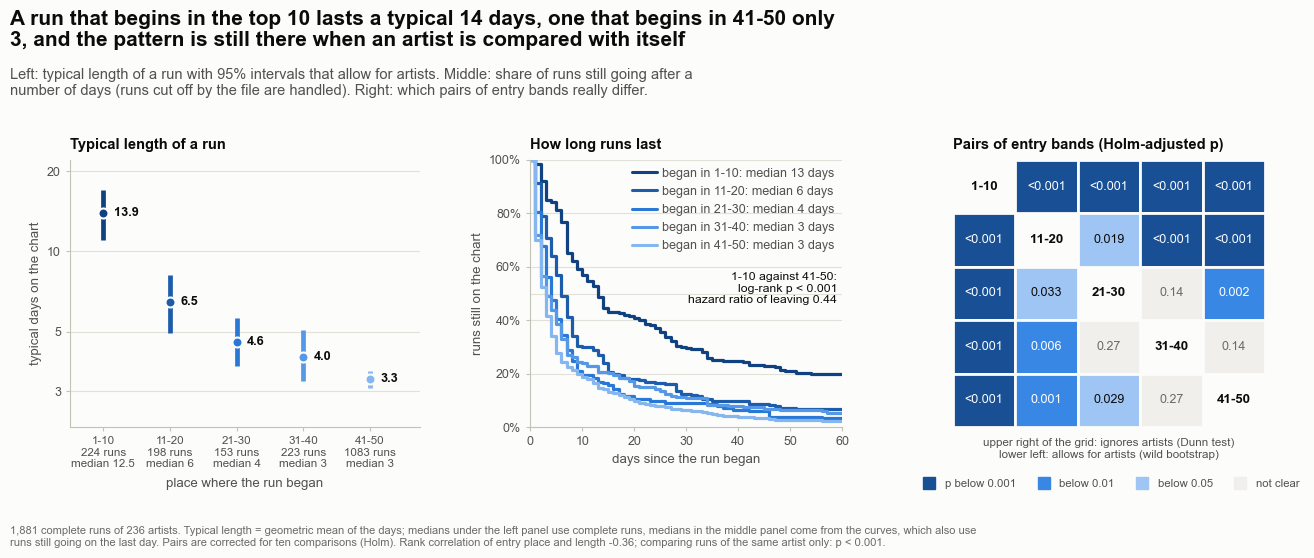

In [23]:
# Figure 10 - H5: how long a run lasts, by the place where it began
band_colours = [style.BLUE_STEPS[k] for k in (650, 550, 450, 350, 250)]                      # darkest = the best entry places
fig, (ax1, ax2, ax3) = make_fig(13.4, 5.7, 1, 3, left=0.95, right=0.5, bottom=1.05, wspace=0.34, panel_titles=True, width_ratios=[1.12, 1.0, 1.0],
                                title=f"A run that begins in the top 10 lasts a typical {typical[band_names[0]][0]:.0f} days, one that begins in 41-50 only {typical[band_names[-1]][0]:.0f}, "
                                      f"and the pattern is still there when an artist is compared with itself",
                                subtitle="Left: typical length of a run with 95% intervals that allow for artists. Middle: share of runs still going after a number of days (runs cut off by the file are handled). "
                                         "Right: which pairs of entry bands really differ.",
                                note_text=f"{FACTS['h5_runs']:,} complete runs of {FACTS['h5_artists']} artists. Typical length = geometric mean of the days; medians under the left panel use complete runs, "
                                          f"medians in the middle panel come from the curves, which also use runs still going on the last day. Pairs are corrected for ten comparisons (Holm). "
                                          f"Rank correlation of entry place and length {FACTS['h5_rho']:.2f}; comparing runs of the same artist only: {FACTS['h5_same_p_text']}.")
for i, name in enumerate(band_names):
    centre, low, high = typical[name]
    ax1.vlines(i, low, high, color=band_colours[i], linewidth=3.4, zorder=2)
    ax1.scatter([i], [centre], s=52, color=band_colours[i], edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
    ax1.text(i + 0.16, centre, f"{centre:.1f}", va="center", ha="left", fontsize=9.2, color=style.INK, fontweight="bold")
ax1.set_yscale("log")
ax1.minorticks_off()
ax1.set_yticks([2, 3, 5, 10, 20])
ax1.set_yticklabels(["2", "3", "5", "10", "20"])
ax1.set_ylim(2.2, 22)
ax1.set_xlim(-0.5, 4.75)
ax1.set_xticks(range(5))
ax1.set_xticklabels([f"{name}\n{FACTS[f'h5_n_{key}']} runs\nmedian {FACTS[f'h5_median_{key}']:g}" for name, key in zip(band_names, band_keys)], fontsize=8.4)
ax1.set_xlabel("place where the run began", labelpad=6)
ax1.set_ylabel("typical days on the chart")
style_axes(ax1, grid="y")
panel_title(ax1, "Typical length of a run")

for i, name in enumerate(band_names):
    curve = km_band[name]
    ax2.step(curve["time"], curve["survival"] * 100, where="post", color=band_colours[i], linewidth=2.3)
ax2.axhline(50, color=style.GRID, linewidth=0.8, zorder=0)
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(percent_formatter())
ax2.set_xlabel("days since the run began")
ax2.set_ylabel("runs still on the chart")
style_axes(ax2, grid="y")
swatch_legend(ax2, [(f"began in {name}: median {FACTS[f'h5_km_median_{key}']:g} days", band_colours[i], "line") for i, (name, key) in enumerate(zip(band_names, band_keys))], loc="upper right")
direct_label(ax2, 59, 58, f"1-10 against 41-50:\nlog-rank {FACTS['h5_logrank_p_text']}\nhazard ratio of leaving {FACTS['h5_logrank_hr']:.2f}", ha="right", va="top", size=8.8, color=style.INK)
panel_title(ax2, "How long runs last")

def shade(p):
    """The fill of a cell of the pair grid: the smaller the adjusted p-value, the darker the blue."""
    if p < 0.001:
        return style.BLUE_STEPS[600], "white"
    if p < 0.01:
        return style.BLUE_STEPS[400], "white"
    if p < ALPHA:
        return style.BLUE_STEPS[200], style.INK
    return style.NEUTRAL_MID, style.MUTED
lookup_wild = {(a, b): p for a, b, p in zip(run_pairs["first"], run_pairs["second"], run_pairs["holm_p"])}
lookup_dunn = {(a, b): p for a, b, p in zip(run_pairs["first"], run_pairs["second"], run_pairs["dunn_holm_p"])}
for row in range(5):
    for col in range(5):
        if row == col:
            ax3.text(col, row, band_names[row], ha="center", va="center", fontsize=9.6, color=style.INK, fontweight="bold")
            continue
        first, second = sorted((row, col))
        key = (band_names[first], band_names[second])
        p = lookup_dunn[key] if row < col else lookup_wild[key]                              # upper right: ignores artists, lower left: allows for artists
        fill, ink = shade(p)
        ax3.add_patch(plt.Rectangle((col - 0.5, row - 0.5), 1, 1, facecolor=fill, edgecolor=style.SURFACE, linewidth=2.0))
        text = format_p(p).replace("p = ", "").replace("p < ", "<")
        ax3.text(col, row, text, ha="center", va="center", fontsize=9.0, color=ink)
ax3.set_xlim(-0.5, 4.5)
ax3.set_ylim(4.5, -0.5)
ax3.set_xticks([])
ax3.set_yticks([])
for spine in ax3.spines.values():
    spine.set_visible(False)
ax3.set_xlabel("upper right of the grid: ignores artists (Dunn test)\nlower left: allows for artists (wild bootstrap)", fontsize=8.4, labelpad=8)
swatch_legend(ax3, [("p below 0.001", style.BLUE_STEPS[600]), ("below 0.01", style.BLUE_STEPS[400]), ("below 0.05", style.BLUE_STEPS[200]), ("not clear", style.NEUTRAL_MID)],
              loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.17), fontsize=8.2)
panel_title(ax3, "Pairs of entry bands (Holm-adjusted p)")
save_fig(fig, "p5_10_h5_entry_run_length", FIG_DIR)
plt.show()

**What to notice**

- A run that began in the top 10 lasts a typical 13.9 days, one that began in 41-50 only 3.3. 75% of the runs that began in the top 10 lasted at least a week, against 24% of those that began in 41-50.
- The planned Kruskal-Wallis test gives p < 0.001 and the primary wild bootstrap p < 0.001. With 10,000 repeats the bootstrap can not report anything smaller than 0.0001, so this is the smallest p-value it can give; the true value is far smaller. Epsilon squared is 0.13 (medium) and the rank correlation is -0.36 (interval -0.43 to -0.28).
- It is not an artist effect. Comparing runs of the same artist only gives p < 0.001 (134 artists have runs in two or more bands). Counting only the first complete run of each song (860 runs) gives p < 0.001 with a correlation of -0.46. With cut-off runs handled, runs that began in 1-10 left at 0.44 times the speed of runs that began in 41-50 (p < 0.001).
- All pairs of bands differ except 2 of 10: 21-30 and 31-40, 31-40 and 41-50 are not clearly different, so the three lowest bands behave much alike. Part of the pattern is arithmetic (a run that begins low has less far to fall), so read it as "where a song enters tells how long it will last", not as a lever that anyone can pull.

## Section 11 - H6 - Are first-time entries concentrated on Mondays and Tuesdays?

The question is about *when* new songs arrive. The planned test treats every entry as an independent event. They are not: when an album is released, many of its songs enter the chart on the same day, and all of them belong to one release. So the primary test works with **calendar weeks** as the unit: within every week, the seven weekdays are ranked by the number of first-time entries, and the Friedman test asks whether some weekdays rank consistently higher. One reminder from Phase 4: the calendar of the file appears to run about a year ahead of real dates, so these are weekdays *as recorded*, not real release days.

**What this code is.** The test of H6. A first-time entry is the first day on the chart of a song that was not already on the chart on the first day of the file (894 such songs). The cell counts them by weekday and then runs: the planned chi-square goodness-of-fit test against "every day gets its fair share" (entries as independent events), the primary Friedman test over the 75 complete calendar weeks, a Wilcoxon test of the weekly Monday-and-Tuesday share against 2/7, and intervals for the Monday-and-Tuesday share that resample *whole weeks*. Three checks follow: only weeks without a very busy day, the same without the artist who debuted the most songs, and each artist counted once per day.

**Why we need it.** Counting entries as independent would be wrong in an obvious way: the biggest single release day brought 31 songs from one artist at once. The checks ask whether the weekday pattern is only about such days. Leaving out the very busy weeks, leaving out the artist with the most debuts (92 of the 894) and counting an artist once a day each remove one way in which a handful of releases could create the pattern.

**What will happen.** The code builds the weekday table from the daily summary, rebuilds it from the song table and asserts that the two agree and that the Monday-and-Tuesday share is the one of Phase 4. It then runs the tests above, builds the week-resampling intervals (10,000 repeats) and stores the numbers. It displays a table of entries per weekday, a table of five tests, and two sentences with the shares.

**Expected outcome.** A table in which Monday and Tuesday have several entries per day and the other days less than one, an enormous chi-square, a smaller but clear Friedman result, and Monday-and-Tuesday shares that stay far above 29% under every way of counting.

**Motive.** Separate a weekday habit from the habit of releasing many songs on one day.

In [24]:
# Section 11 - H6: are first-time entries concentrated on Mondays and Tuesdays?
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_keys = ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]
flow = daily.merge(dim_date[["date", "day_of_week"]], on="date", how="left")                  # one row per snapshot day, with its weekday (1 = Monday ... 7 = Sunday, as recorded in the file)
iso = flow["date"].dt.isocalendar()
flow["week"] = iso["year"].astype(int) * 100 + iso["week"].astype(int)                         # the calendar week (Monday to Sunday) that the day belongs to
entries_by_day = flow.groupby("day_of_week")["new_entries"].sum().reindex(range(1, 8))         # first-time entries on every weekday, over the whole period
days_by_day = flow.groupby("day_of_week").size().reindex(range(1, 8))                          # how many snapshot days there are of every weekday
total_entries = int(entries_by_day.sum())
share_mon_tue = 100 * entries_by_day.loc[[1, 2]].sum() / total_entries
expected_mon_tue = 100 * days_by_day.loc[[1, 2]].sum() / days_by_day.sum()                         # the share Monday and Tuesday would get if every day were alike (28.6% of the days)

# ---- the same first-time entries, song by song: the first day on which a song is on the chart, for songs that were not there on day one
debut = songs.loc[~songs["on_chart_at_window_start"], ["track_id", "artist", "first_seen"]].copy()
debut["weekday"] = debut["first_seen"].dt.dayofweek + 1
assert (debut["weekday"].value_counts().reindex(range(1, 8), fill_value=0).to_numpy() == entries_by_day.to_numpy()).all(), "song table and daily table disagree"
debut["week"] = debut["first_seen"].dt.isocalendar().year.astype(int) * 100 + debut["first_seen"].dt.isocalendar().week.astype(int)
if p4_file.exists():
    assert abs(share_mon_tue - p4["mon_tue_new_share"]) < 1e-9, "the Monday-Tuesday share differs from Phase 4"
    assert abs(entries_by_day.loc[1] / days_by_day.loc[1] - p4["new_monday"]) < 1e-9, "the Monday average differs from Phase 4"

FACTS["h6_entries"] = total_entries
FACTS["h6_share_mon_tue"], FACTS["h6_expected_mon_tue"] = float(share_mon_tue), float(expected_mon_tue)
for number, key in zip(range(1, 8), weekday_keys):
    FACTS[f"h6_total_{key}"] = int(entries_by_day.loc[number])
    FACTS[f"h6_per_day_{key}"] = float(entries_by_day.loc[number] / days_by_day.loc[number])
FACTS["h6_wed_to_sun_per_day"] = float(entries_by_day.loc[3:7].sum() / days_by_day.loc[3:7].sum())

# ---- the planned test: chi-square goodness-of-fit, every first-time entry counted as an independent event
planned6 = classical.chi_square_goodness_of_fit(entries_by_day.to_numpy(), days_by_day.to_numpy())

# ---- the primary test: Friedman test, a calendar week is the block, the seven weekdays are ranked inside every week. Only weeks with all seven days are used
week_length = flow.groupby("week")["day_of_week"].nunique()
complete_weeks = week_length[week_length == 7].index
weekly = flow[flow["week"].isin(complete_weeks)].pivot(index="week", columns="day_of_week", values="new_entries")
friedman6 = classical.friedman_test(weekly.to_numpy())
mon_tue_weekly = (weekly[[1, 2]].sum(axis=1) / weekly.sum(axis=1)).dropna()                      # Monday + Tuesday share of the week (weeks without any first-time entry have none)
signed6 = classical.wilcoxon_signed_rank_test(mon_tue_weekly.to_numpy(), np.full(len(mon_tue_weekly), 2 / 7))

# ---- intervals that treat a WEEK as the unit that is resampled
def week_interval(frame, weeks, keep_days=(1, 2), seed=0):
    """Share of first-time entries that fall on the given weekdays (%), with a 95% interval from resampling whole calendar weeks."""
    per_week = frame.groupby("week").agg(total=("weekday", "size"), chosen=("weekday", lambda s: int(s.isin(keep_days).sum())))
    per_week = per_week.reindex(list(weeks), fill_value=0)                                       # every week of the stated set, also those without an entry
    totals, chosen = per_week["total"].to_numpy(dtype=float), per_week["chosen"].to_numpy(dtype=float)
    replicates = dependence.cluster_bootstrap(np.arange(len(per_week)), lambda w: 100 * (w @ chosen) / (w @ totals), n_boot=N_BOOT, seed=seed)
    low, high = dependence.bootstrap_interval(replicates)
    return 100 * chosen.sum() / totals.sum(), low, high
all_weeks = sorted(flow["week"].unique())
all_songs_share = week_interval(debut, all_weeks, seed=SEED + 700)

week_matrix = weekly.to_numpy(dtype=float)
per_weekday = {}
for number, key in zip(range(1, 8), weekday_keys):
    column = week_matrix[:, number - 1]
    replicates = dependence.cluster_bootstrap(np.arange(len(column)), lambda w, c=column: (w @ c) / w.sum(axis=1), n_boot=N_BOOT, seed=SEED + 710 + number)
    per_weekday[key] = (float(column.mean()), *dependence.bootstrap_interval(replicates))
replicates = dependence.cluster_bootstrap(np.arange(len(mon_tue_weekly)), lambda w, c=mon_tue_weekly.to_numpy() * 100: (w @ c) / w.sum(axis=1), n_boot=N_BOOT, seed=SEED + 720)
weekly_share_low, weekly_share_high = dependence.bootstrap_interval(replicates)

# ---- checks. (1) weeks that had no very busy day (the 22 "high turnover" days of Phase 2 are the days when a big release floods the chart)
busy_weeks = flow.loc[flow["is_high_turnover_day"], "week"].unique()
quiet = weekly.loc[~weekly.index.isin(busy_weeks)]
friedman_quiet = classical.friedman_test(quiet.to_numpy())
quiet_share = week_interval(debut[debut["week"].isin(quiet.index)], quiet.index, seed=SEED + 730)

# (2) without the artist who debuted the most songs
biggest = debut["artist"].value_counts().index[0]
without_biggest = week_interval(debut[debut["artist"] != biggest], all_weeks, seed=SEED + 740)

# (3) every artist counted once per day: an album that arrives on one day brings many songs, but it is one release
releases = debut.drop_duplicates(["artist", "first_seen"])
release_matrix = (releases.groupby(["week", "weekday"]).size().unstack(fill_value=0).reindex(columns=range(1, 8), fill_value=0)
                  .reindex(weekly.index, fill_value=0))
friedman_releases = classical.friedman_test(release_matrix.to_numpy())
release_share = week_interval(releases, all_weeks, seed=SEED + 750)
biggest_drop = debut.groupby(["artist", "first_seen"]).size().sort_values(ascending=False)

for key, value in {"h6_chi2": planned6.statistic, "h6_chi_p": planned6.p_value, "h6_chi_p_text": format_p(planned6.p_value), "h6_cohens_w": planned6.detail["cohens_w"],
                   "h6_cohens_w_word": effect_label("cohens_w", planned6.detail["cohens_w"]),
                   "h6_weeks": len(weekly), "h6_weeks_all": int(flow["week"].nunique()), "h6_friedman": friedman6.statistic, "h6_friedman_p": friedman6.p_value,
                   "h6_friedman_p_text": format_p(friedman6.p_value), "h6_kendall_w": friedman6.detail["kendalls_w"],
                   "h6_kendall_w_word": effect_label("kendalls_w", friedman6.detail["kendalls_w"]),
                   "h6_weekly_share": 100 * float(mon_tue_weekly.mean()), "h6_weekly_share_low": weekly_share_low, "h6_weekly_share_high": weekly_share_high,
                   "h6_weekly_median": 100 * float(mon_tue_weekly.median()), "h6_weekly_n": len(mon_tue_weekly),
                   "h6_signed_p_text": format_p(signed6.p_value), "h6_all_share_low": all_songs_share[1], "h6_all_share_high": all_songs_share[2],
                   "h6_quiet_weeks": len(quiet), "h6_busy_weeks": len(busy_weeks), "h6_quiet_p_text": format_p(friedman_quiet.p_value), "h6_quiet_w": friedman_quiet.detail["kendalls_w"],
                   "h6_quiet_share": quiet_share[0], "h6_quiet_low": quiet_share[1], "h6_quiet_high": quiet_share[2],
                   "h6_biggest": biggest, "h6_biggest_debuts": int((debut["artist"] == biggest).sum()), "h6_without_n": int((debut["artist"] != biggest).sum()),
                   "h6_without_share": without_biggest[0], "h6_without_low": without_biggest[1], "h6_without_high": without_biggest[2],
                   "h6_releases": len(releases), "h6_release_share": release_share[0], "h6_release_low": release_share[1], "h6_release_high": release_share[2],
                   "h6_release_p_text": format_p(friedman_releases.p_value), "h6_release_w": friedman_releases.detail["kendalls_w"],
                   "h6_biggest_drop": int(biggest_drop.iloc[0]), "h6_drops_5plus": int((biggest_drop >= 5).sum()),
                   "h6_busy_days": int(flow["is_high_turnover_day"].sum())}.items():
    FACTS[key] = value

display(pd.DataFrame({"first-time entries": entries_by_day.to_numpy(), "snapshot days": days_by_day.to_numpy(), "entries per day": (entries_by_day / days_by_day).to_numpy(),
                      "in complete weeks, per week": [per_weekday[k][0] for k in weekday_keys]}, index=weekday_names))
rows = [("chi-square goodness-of-fit (planned, entries as independent events)", planned6.p_value, "Cohen's w", planned6.detail["cohens_w"]),
        ("Friedman test, weeks as blocks (primary)", friedman6.p_value, "Kendall's W", friedman6.detail["kendalls_w"]),
        ("Wilcoxon test of the weekly Monday-Tuesday share against 2/7", signed6.p_value, "rank-biserial", signed6.estimate),
        ("Friedman test, only weeks without a very busy day", friedman_quiet.p_value, "Kendall's W", friedman_quiet.detail["kendalls_w"]),
        ("Friedman test, releases of an artist counted once a day", friedman_releases.p_value, "Kendall's W", friedman_releases.detail["kendalls_w"])]
display(pd.DataFrame(rows, columns=["test", "p-value", "effect measure", "size"]).set_index("test"))
print(f"{FACTS['h6_share_mon_tue']:.1f}% of the {FACTS['h6_entries']} first-time entries fall on a Monday or Tuesday; an even spread would give {FACTS['h6_expected_mon_tue']:.1f}%. "
      f"Average week: {FACTS['h6_weekly_share']:.1f}% (interval {FACTS['h6_weekly_share_low']:.1f}% to {FACTS['h6_weekly_share_high']:.1f}%).")
print(f"Counting each artist once a day ({FACTS['h6_releases']} releases): {FACTS['h6_release_share']:.1f}%. Without {FACTS['h6_biggest']}: {FACTS['h6_without_share']:.1f}%. "
      f"Only weeks without a very busy day ({FACTS['h6_quiet_weeks']} complete weeks): {FACTS['h6_quiet_share']:.1f}% of their entries.")

,first-time entries,snapshot days,entries per day,"in complete weeks, per week"
Monday,357,80,4.463,4.04
Tuesday,240,79,3.038,3.16
Wednesday,48,79,0.6076,0.6267
Thursday,65,80,0.8125,0.8133
Friday,61,77,0.7922,0.8133
Saturday,42,80,0.525,0.5333
Sunday,81,80,1.012,0.84


,p-value,effect measure,size
test,,,
"chi-square goodness-of-fit (planned, entries as independent events)",1.847e-146,Cohen's w,0.8805
"Friedman test, weeks as blocks (primary)",4.823e-11,Kendall's W,0.133
Wilcoxon test of the weekly Monday-Tuesday share against 2/7,4.329e-11,rank-biserial,0.8874
"Friedman test, only weeks without a very busy day",3.114e-09,Kendall's W,0.1462
"Friedman test, releases of an artist counted once a day",1.949e-10,Kendall's W,0.1264


66.8% of the 894 first-time entries fall on a Monday or Tuesday; an even spread would give 28.6%. Average week: 63.8% (interval 57.1% to 70.4%).
Counting each artist once a day (444 releases): 51.4%. Without Taylor Swift: 63.8%. Only weeks without a very busy day (58 complete weeks): 60.1% of their entries.


**What this code is.** Figure 11, three panels. Left: the average number of first-time entries per weekday in a complete week, with 95% intervals from resampling weeks. Middle: a histogram of the Monday-and-Tuesday share of each calendar week (how many weeks fall into each 10-point band), with the even-spread share and the average week marked. Right: the overall Monday-and-Tuesday share under four ways of counting, against the share that an even spread would give.

**Why we need it.** A p-value cannot tell whether the pattern is a habit of most weeks or the result of a few huge weeks. The histogram shows how the weeks are spread; the right panel shows the share surviving each way of counting.

**What will happen.** The code draws the three panels and saves the picture as `p5_11_h6_weekday_entries.png`.

**Expected outcome.** Two tall blue bars (Monday and Tuesday) and five short grey ones; a histogram that piles up to the right of the even-spread line, with only a few weeks on its left; four intervals on the right, all far to the right of the dashed line.

**Motive.** Show that the pattern is a regular weekly rhythm of most weeks, and how much of it a few big releases explain.

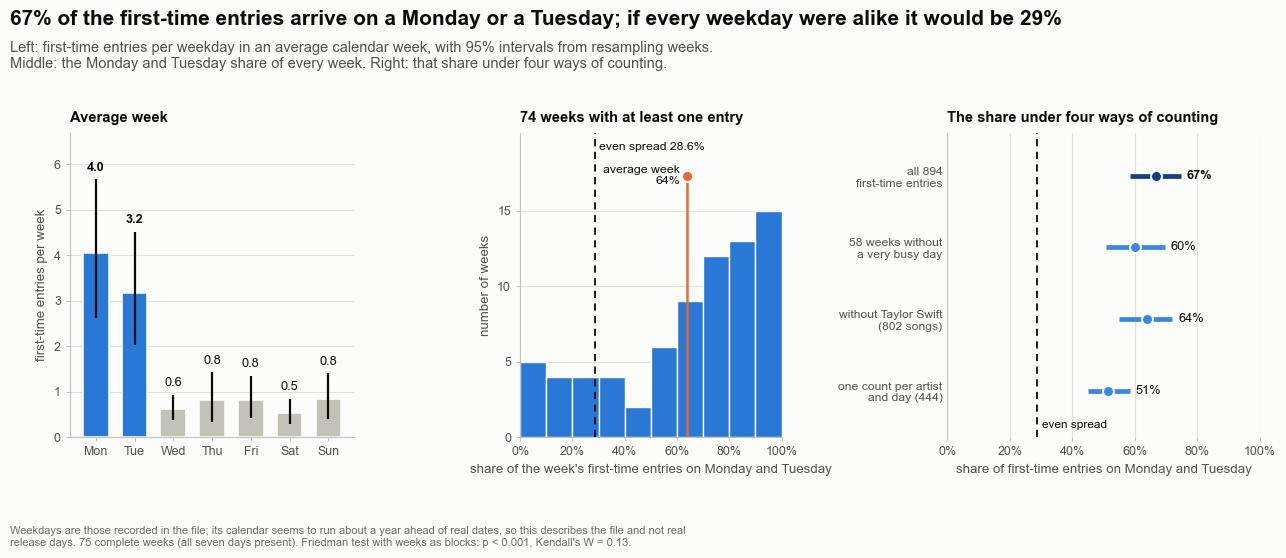

In [25]:
# Figure 11 - H6: on which weekdays do first-time entries arrive?
fig, (ax1, ax2, ax3) = make_fig(13.4, 5.7, 1, 3, left=0.95, right=0.55, bottom=0.95, wspace=0.58, panel_titles=True, width_ratios=[1.0, 0.92, 1.1],
                                title=f"{FACTS['h6_share_mon_tue']:.0f}% of the first-time entries arrive on a Monday or a Tuesday; if every weekday were alike it would be {FACTS['h6_expected_mon_tue']:.0f}%",
                                subtitle="Left: first-time entries per weekday in an average calendar week, with 95% intervals from resampling weeks. Middle: the Monday and Tuesday share of every week. "
                                         "Right: that share under four ways of counting.",
                                note_text=f"Weekdays are those recorded in the file; its calendar seems to run about a year ahead of real dates, so this describes the file and not real release days. "
                                          f"{FACTS['h6_weeks']} complete weeks (all seven days present). Friedman test with weeks as blocks: {FACTS['h6_friedman_p_text']}, Kendall's W = {FACTS['h6_kendall_w']:.2f}.")
x = np.arange(7)
for i, key in enumerate(weekday_keys):
    centre, low, high = per_weekday[key]
    colour = style.BLUE if i < 2 else style.AXIS
    ax1.bar(i, centre, width=0.66, color=colour, edgecolor=style.SURFACE, linewidth=1.2, zorder=2)
    ax1.vlines(i, low, high, color=style.INK, linewidth=1.6, zorder=3)
    ax1.text(i, high + 0.12, f"{centre:.1f}", ha="center", va="bottom", fontsize=9.2, color=style.INK, fontweight="bold" if i < 2 else "normal")
ax1.set_xticks(x)
ax1.set_xticklabels([name[:3] for name in weekday_names])
ax1.set_ylim(0, max(v[2] for v in per_weekday.values()) * 1.18)
ax1.set_ylabel("first-time entries per week")
style_axes(ax1, grid="y")
panel_title(ax1, "Average week")

shares = mon_tue_weekly.to_numpy() * 100
ax2.hist(shares, bins=np.arange(0, 101, 10), color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.0, zorder=2)
ax2.axvline(FACTS["h6_expected_mon_tue"], color=style.INK, linewidth=1.3, linestyle=(0, (4, 3)), zorder=3)
ax2.set_ylim(0, ax2.get_ylim()[1] * 1.28)                                                       # room above the bars for the two reference labels
top = ax2.get_ylim()[1]
ax2.set_yticks(range(0, int(top * 0.8) + 1, 5))                                                      # whole weeks only
ax2.vlines(FACTS["h6_weekly_share"], 0, top * 0.86, color=style.ORANGE, linewidth=1.8, zorder=3)
ax2.scatter([FACTS["h6_weekly_share"]], [top * 0.86], s=64, color=style.ORANGE, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
ax2.text(FACTS["h6_weekly_share"] - 2.5, top * 0.86, f"average week\n{FACTS['h6_weekly_share']:.0f}%", ha="right", va="center", fontsize=8.8, color=style.INK)
ax2.text(FACTS["h6_expected_mon_tue"] + 1.5, top * 0.97, f"even spread {FACTS['h6_expected_mon_tue']:.1f}%", ha="left", va="top", fontsize=8.8, color=style.INK)
ax2.set_xlim(0, 100)
ax2.xaxis.set_major_formatter(percent_formatter())
ax2.set_xlabel("share of the week's first-time entries on Monday and Tuesday")
ax2.set_ylabel("number of weeks")
style_axes(ax2, grid="y")
panel_title(ax2, f"{FACTS['h6_weekly_n']} weeks with at least one entry")

rows = [(f"all {FACTS['h6_entries']}\nfirst-time entries", FACTS["h6_share_mon_tue"], FACTS["h6_all_share_low"], FACTS["h6_all_share_high"], style.BLUE_STEPS[650]),
        (f"{FACTS['h6_quiet_weeks']} weeks without\na very busy day", FACTS["h6_quiet_share"], FACTS["h6_quiet_low"], FACTS["h6_quiet_high"], style.BLUE_STEPS[400]),
        (f"without {FACTS['h6_biggest']}\n({FACTS['h6_without_n']} songs)", FACTS["h6_without_share"], FACTS["h6_without_low"], FACTS["h6_without_high"], style.BLUE_STEPS[400]),
        (f"one count per artist\nand day ({FACTS['h6_releases']})", FACTS["h6_release_share"], FACTS["h6_release_low"], FACTS["h6_release_high"], style.BLUE_STEPS[400])]
ax3.axvline(FACTS["h6_expected_mon_tue"], color=style.INK, linewidth=1.3, linestyle=(0, (4, 3)), zorder=1)
for row, (label, centre, low, high, colour) in enumerate(rows):
    ax3.hlines(row, low, high, color=colour, linewidth=3.4, zorder=3)
    ax3.scatter([centre], [row], s=62, color=colour, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
    ax3.text(high + 2, row, f"{centre:.0f}%", va="center", ha="left", fontsize=9.2, color=style.INK, fontweight="bold" if row == 0 else "normal")
ax3.text(FACTS["h6_expected_mon_tue"] + 1.5, 3.55, "even spread", ha="left", va="bottom", fontsize=8.6, color=style.INK)
ax3.set_xlim(0, 100)
ax3.xaxis.set_major_formatter(percent_formatter())
ax3.set_yticks(range(len(rows)))
ax3.set_yticklabels([r[0] for r in rows], fontsize=8.7)
ax3.set_ylim(3.65, -0.6)
ax3.set_xlabel("share of first-time entries on Monday and Tuesday")
style_axes(ax3, grid="x", bottom_spine=False)
ax3.tick_params(axis="y", length=0)
panel_title(ax3, "The share under four ways of counting")
save_fig(fig, "p5_11_h6_weekday_entries", FIG_DIR)
plt.show()

**What to notice**

- 67% of the 894 first-time entries arrive on a Monday or Tuesday, against 29% if every weekday were alike. On an average day there are 4.5 first-time entries on a Monday and 3.0 on a Tuesday, against 0.8 on the other five days.
- The planned chi-square test is overwhelming (p < 0.001, Cohen's w 0.88), but it counts 894 entries as independent. The primary Friedman test over 75 weeks still gives p < 0.001. Kendall's W is only 0.13 (small): most days have zero or one first-time entry, so within a week many days tie, and W can not become large even when Monday is the busiest day of most weeks. The share itself (64% in an average week, interval 57 to 70) is the better description of the size.
- It is not just a few album days. In the 58 weeks without a very busy day the share is 60% (p < 0.001). Without Taylor Swift it is 64%. Counting each artist only once a day (444 releases) it is 51% (interval 45 to 58). Every way of counting stays well above the even-spread 29%.
- The weekdays are those recorded in the file, which seems to run about a year ahead of real dates, so this is a statement about the file. Within the file, new songs arrive mainly at the start of the week.

## Section 12 - H7 - Do longer songs reach the top 10 more often?

The same kind of question as H1 (did the song ever reach the top 10?) but the explaining variable is now a number, the length of the song, grouped into the five bands of Phase 4. The planned test looks for a trend across the bands. The primary test fits a straight line through the five bands with standard errors clustered by artist. Because length can go together with other things (longer songs are less often singles, for example), and because a long song might simply come from an artist who tends to reach the top 10, four checks follow.

**What this code is.** The test of H7. The planned tests are the chi-square test of independence (which ignores the order of the length bands) and the Cochran-Armitage test for a trend across the bands. The primary test is the slope of "reached the top 10" (1 or 0) on the band number (1 for the shortest, 5 for the longest), with standard errors clustered by artist and a wild bootstrap-t: it says by how many percentage points the top-10 share changes from one band to the next. The checks are the exact length per minute and on ranks, the slope with release format, explicit and collaboration held fixed, the slope separately for singles and album tracks, and the slope among songs of the *same artist* only.

**Why we need it.** A longer song is not an experiment. It differs from a shorter one in other ways, so the question is whether the link survives holding those fixed. The same-artist check is the strictest: if longer songs reach the top 10 more often only because certain artists make longer songs and also reach the top 10, then the link disappears when each artist is compared with itself.

**What will happen.** The code groups the songs into the five bands and asserts that the share per band and the band sizes equal Phase 4. It runs the planned and primary tests with 10,000 bootstrap repeats, the checks above, and an artist bootstrap for the share in each band (used in the figure). It shows a table of the bands with the share of singles, explicit songs and collaborations in each, a table of nine tests, and two sentences.

**Expected outcome.** Top-10 shares that rise from 24% (under 2:30) to 36% (4:00 and up), a slope of about 3 points per band that stays clear in most checks, and a same-artist check that is not clear.

**Motive.** Find out whether the link belongs to the length or to the artists who make long songs.

In [26]:
# Section 12 - H7: do longer songs reach the top 10 more often?
length_edges = [0, 2.5, 3.0, 3.5, 4.0, 100]                                                 # the five length bands of Phase 4, in minutes
length_names = ["under 2:30", "2:30-3:00", "3:00-3:30", "3:30-4:00", "4:00 and up"]
length_keys = ["u230", "b230", "b300", "b330", "o400"]
songs["length_band"] = pd.cut(songs["duration_min"], length_edges, labels=length_names)
length_score = songs["length_band"].cat.codes.to_numpy(dtype=float) + 1                     # the band as a number: 1 (shortest) to 5 (longest)
top10 = songs["top10"].to_numpy()
song_artist = pd.factorize(songs["artist"])[0]
band_table = songs.groupby("length_band", observed=True).agg(songs=("track_id", "size"), top10=("top10", "sum")).reindex(length_names)
band_table["pct"] = 100 * band_table["top10"] / band_table["songs"]
for key, name in zip(length_keys, length_names):
    FACTS[f"h7_n_{key}"] = int(band_table.loc[name, "songs"])
    FACTS[f"h7_top10_{key}"] = int(band_table.loc[name, "top10"])
    FACTS[f"h7_pct_{key}"] = float(band_table.loc[name, "pct"])
if p4_file.exists():
    for key in length_keys:
        assert abs(FACTS[f"h7_pct_{key}"] - p4[f"len_top10_{key}"]) < 1e-9, "the top-10 shares by length band differ from Phase 4"
        assert FACTS[f"h7_n_{key}"] == p4[f"len_songs_{key}"], "the number of songs by length band differs from Phase 4"

# ---- the planned tests: songs treated as independent
chi7 = classical.chi_square_independence(np.column_stack([band_table["top10"], band_table["songs"] - band_table["top10"]]))
trend7 = classical.cochran_armitage_trend(band_table["top10"].to_numpy(), band_table["songs"].to_numpy())
plain_fit = dependence.fit_ols(top10, np.column_stack([np.ones(len(top10)), length_score]))
plain_slope = dependence.coefficient_test(plain_fit, 1)                                      # the straight-line slope, every song counted as independent

# ---- the primary test: slope of "reached the top 10" (0 or 1) on the band number, standard errors clustered by artist, wild bootstrap-t
wild7 = dependence.wild_slope_test(top10, length_score, song_artist, n_boot=N_BOOT, seed=SEED + 700)
clustered7 = dependence.cluster_robust_slope_test(top10, length_score, songs["artist"])
icc7 = dependence.intraclass_correlation(pd.Series(top10), songs["artist"])

# ---- checks. (1) the exact length instead of five bands: per extra minute (songs over 8 minutes counted as 8), and on ranks
minutes = songs["duration_min"].clip(upper=8).to_numpy()
wild_minutes = dependence.wild_slope_test(top10, minutes, song_artist, n_boot=N_BOOT, seed=SEED + 701)
wild_ranks = dependence.wild_slope_test(top10, stats.rankdata(songs["duration_min"]), song_artist, n_boot=N_BOOT, seed=SEED + 702)
point_biserial = stats.pointbiserialr(top10, songs["duration_min"])[0]

# (2) are longer songs different in other ways (less often singles, for example)? Adjust for release format, explicit and collaboration
mix = songs.groupby("length_band", observed=True)[["is_single", "is_explicit", "is_collab"]].mean().reindex(length_names) * 100
adjusted_columns = np.column_stack([np.ones(len(top10)), length_score, songs["is_single"].astype(float), songs["is_explicit"].astype(float), songs["is_collab"].astype(float)])
wild_adjusted = dependence.wild_cluster_bootstrap_test(top10, adjusted_columns, [0, 1, 0, 0, 0], song_artist, n_boot=N_BOOT, seed=SEED + 704,
                                                       name="slope with release format, explicit and collaboration held fixed (wild cluster bootstrap-t)")

# (3) singles and album tracks separately
by_format = {}
for label, mask in (("singles", songs["is_single"].to_numpy()), ("album tracks", ~songs["is_single"].to_numpy())):
    by_format[label] = (int(mask.sum()), dependence.wild_slope_test(top10[mask], length_score[mask], song_artist[mask], n_boot=N_BOOT, seed=SEED + 705 + int(mask[0])))

# (4) the check that matters most: songs of the SAME artist only. Do longer songs of one artist reach the top 10 more often than shorter songs of that artist?
same_artist7 = dependence.wild_fixed_effects_test(top10, length_score, [1], song_artist, n_boot=N_BOOT, seed=SEED + 703,
                                                  name="same artist only: slope on the length band (wild cluster bootstrap-t)")
bands_per_artist = songs.groupby("artist")["length_band"].nunique()
FACTS["h7_artists_within"] = int((bands_per_artist >= 2).sum())
FACTS["h7_songs_within"] = int(songs["artist"].map(bands_per_artist).ge(2).sum())

# ---- the share of each band with an artist bootstrap interval, for the figure
band_share = {}
for name, key in zip(length_names, length_keys):
    member = (songs["length_band"] == name).to_numpy(dtype=float)
    replicates = dependence.cluster_bootstrap(song_artist, lambda w, m=member: 100 * (w @ (top10 * m)) / (w @ m), n_boot=N_BOOT, seed=SEED + 710)
    band_share[name] = (FACTS[f"h7_pct_{key}"], *dependence.bootstrap_interval(replicates))

for key, value in {"h7_chi_p_text": format_p(chi7.p_value), "h7_chi_v": chi7.detail["cramers_v"], "h7_ca_z": trend7.statistic, "h7_ca_p": trend7.p_value, "h7_ca_p_text": format_p(trend7.p_value),
                   "h7_plain_slope": 100 * plain_slope.estimate, "h7_plain_low": 100 * plain_slope.ci_low, "h7_plain_high": 100 * plain_slope.ci_high, "h7_plain_p_text": format_p(plain_slope.p_value),
                   "h7_slope": 100 * wild7.estimate, "h7_slope_low": 100 * wild7.ci_low, "h7_slope_high": 100 * wild7.ci_high, "h7_wild_p": wild7.p_value, "h7_wild_p_text": format_p(wild7.p_value),
                   "h7_clustered_p_text": format_p(clustered7.p_value), "h7_icc": icc7["icc"],
                   "h7_minute_slope": 100 * wild_minutes.estimate, "h7_minute_low": 100 * wild_minutes.ci_low, "h7_minute_high": 100 * wild_minutes.ci_high,
                   "h7_minute_p_text": format_p(wild_minutes.p_value), "h7_rank_p_text": format_p(wild_ranks.p_value),
                   "h7_r": float(point_biserial), "h7_r_word": effect_label("correlation", point_biserial),
                   "h7_single_pct_short": mix.loc[length_names[0], "is_single"], "h7_single_pct_long": mix.loc[length_names[-1], "is_single"],
                   "h7_adj_slope": 100 * wild_adjusted.estimate, "h7_adj_low": 100 * wild_adjusted.ci_low, "h7_adj_high": 100 * wild_adjusted.ci_high, "h7_adj_p_text": format_p(wild_adjusted.p_value),
                   "h7_singles_n": by_format["singles"][0], "h7_singles_slope": 100 * by_format["singles"][1].estimate, "h7_singles_p_text": format_p(by_format["singles"][1].p_value),
                   "h7_albums_n": by_format["album tracks"][0], "h7_albums_slope": 100 * by_format["album tracks"][1].estimate, "h7_albums_p_text": format_p(by_format["album tracks"][1].p_value),
                   "h7_same_slope": 100 * same_artist7.estimate, "h7_same_low": 100 * same_artist7.ci_low, "h7_same_high": 100 * same_artist7.ci_high,
                   "h7_same_p": same_artist7.p_value, "h7_same_p_text": format_p(same_artist7.p_value),
                   "h7_gap_points": float(band_table["pct"].iloc[-1] - band_table["pct"].iloc[0])}.items():
    FACTS[key] = value

display(band_table.round(1).assign(**{"singles (%)": mix["is_single"].round(1), "explicit (%)": mix["is_explicit"].round(1), "collaborations (%)": mix["is_collab"].round(1)}))
rows = [("chi-square test of independence (planned, ignores the order of the bands)", chi7.p_value), ("Cochran-Armitage test for trend (planned)", trend7.p_value),
        ("straight-line slope, songs as independent", plain_slope.p_value), ("slope clustered by artist, t distribution", clustered7.p_value),
        ("slope clustered by artist, wild bootstrap-t (primary)", wild7.p_value), ("exact length per minute, wild bootstrap-t", wild_minutes.p_value),
        ("length on ranks, wild bootstrap-t", wild_ranks.p_value), ("release format, explicit and collaboration held fixed", wild_adjusted.p_value),
        ("same artist only (wild bootstrap-t)", same_artist7.p_value)]
display(pd.DataFrame(rows, columns=["test", "p-value"]).set_index("test"))
print(f"Top-10 reach rises from {band_table['pct'].iloc[0]:.0f}% (under 2:30) to {band_table['pct'].iloc[-1]:.0f}% (4:00 and up): {FACTS['h7_slope']:+.1f} points per band "
      f"(interval {FACTS['h7_slope_low']:+.1f} to {FACTS['h7_slope_high']:+.1f}). Correlation of exact length and top-10 reach: {FACTS['h7_r']:.3f} ({FACTS['h7_r_word']}).")
print(f"Comparing songs of the same artist ({FACTS['h7_artists_within']} artists with songs in more than one band, {FACTS['h7_songs_within']} songs): "
      f"{FACTS['h7_same_slope']:+.1f} points per band (interval {FACTS['h7_same_low']:+.1f} to {FACTS['h7_same_high']:+.1f}), {FACTS['h7_same_p_text']}.")

,songs,top10,pct,singles (%),explicit (%),collaborations (%)
length_band,,,,,,
under 2:30,125,30,24,32.8,57.6,10.4
2:30-3:00,191,57,29.8,30.4,55.5,13.1
3:00-3:30,218,70,32.1,20.6,51.4,15.1
3:30-4:00,201,73,36.3,22.4,45.3,13.4
4:00 and up,209,76,36.4,12.9,54.5,11.5


,p-value
test,
"chi-square test of independence (planned, ignores the order of the bands)",0.1112
Cochran-Armitage test for trend (planned),0.009035
"straight-line slope, songs as independent",0.009001
"slope clustered by artist, t distribution",0.001088
"slope clustered by artist, wild bootstrap-t (primary)",0.003
"exact length per minute, wild bootstrap-t",0.011
"length on ranks, wild bootstrap-t",0.0043
"release format, explicit and collaboration held fixed",0.0019
same artist only (wild bootstrap-t),0.4438


Top-10 reach rises from 24% (under 2:30) to 36% (4:00 and up): +3.0 points per band (interval +1.0 to +4.9). Correlation of exact length and top-10 reach: 0.074 (negligible).
Comparing songs of the same artist (82 artists with songs in more than one band, 762 songs): +0.9 points per band (interval -1.3 to +3.1), p = 0.44.


**What this code is.** Figure 12. Left: the share of songs that reached the top 10 in each length band, with 95% intervals from resampling artists, and the overall share as a dashed line. Right: the change in that share per length band, in percentage points, seen six ways: ignoring artists, the primary test, with release format, explicit and collaboration held fixed, singles only, album tracks only, and the same artist only.

**Why we need it.** The bars show the pattern the question is about; the six intervals show how much of it is left under each doubt. The last row is the one to look at: it is the same comparison made inside each artist.

**What will happen.** The code draws the bars and the six intervals and saves the picture as `p5_12_h7_song_length.png`.

**Expected outcome.** Bars that rise from left to right, five intervals on the right that lie mostly to the right of zero, and a last one (same artist only) that is centred close to zero and crosses it.

**Motive.** Show the difference between a pattern in the data and a pattern within each artist.

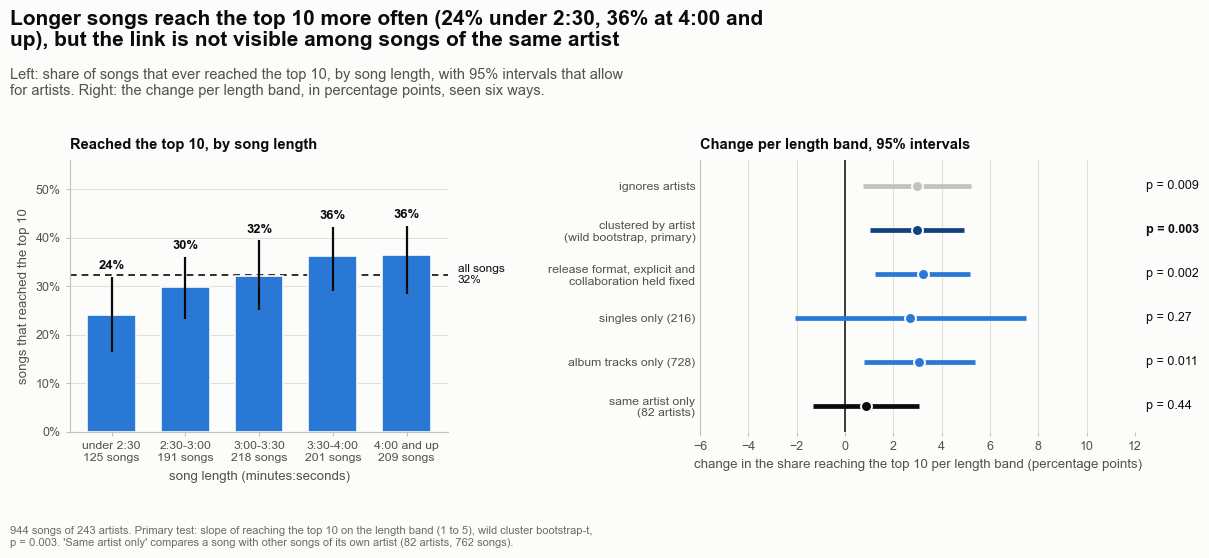

In [27]:
# Figure 12 - H7: song length and reaching the top 10
fig, (ax1, ax2) = make_fig(12.6, 5.7, 1, 2, left=0.95, right=1.0, bottom=1.0, wspace=0.62, panel_titles=True, width_ratios=[1.0, 1.15],
                           title=f"Longer songs reach the top 10 more often ({FACTS['h7_pct_u230']:.0f}% under 2:30, {FACTS['h7_pct_o400']:.0f}% at 4:00 and up), "
                                 f"but the link is not visible among songs of the same artist",
                           subtitle="Left: share of songs that ever reached the top 10, by song length, with 95% intervals that allow for artists. "
                                    "Right: the change per length band, in percentage points, seen six ways.",
                           note_text=f"{FACTS['songs']} songs of {FACTS['artists']} artists. Primary test: slope of reaching the top 10 on the length band (1 to 5), wild cluster bootstrap-t, "
                                     f"{FACTS['h7_wild_p_text']}. 'Same artist only' compares a song with other songs of its own artist ({FACTS['h7_artists_within']} artists, {FACTS['h7_songs_within']} songs).")
overall = 100 * float(top10.mean())
for i, (name, key) in enumerate(zip(length_names, length_keys)):
    centre, low, high = band_share[name]
    ax1.bar(i, centre, width=0.66, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=2)
    ax1.vlines(i, low, high, color=style.INK, linewidth=1.6, zorder=3)
    ax1.text(i, high + 1.0, f"{centre:.0f}%", ha="center", va="bottom", fontsize=9.4, color=style.INK, fontweight="bold")
ax1.axhline(overall, color=style.INK, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
ax1.annotate(f"all songs\n{overall:.0f}%", xy=(1.0, overall), xycoords=("axes fraction", "data"), xytext=(7, 0), textcoords="offset points", va="center", ha="left",
             fontsize=8.6, color=style.INK, annotation_clip=False)
ax1.set_xticks(range(5))
ax1.set_xticklabels([f"{name}\n{FACTS[f'h7_n_{key}']} songs" for name, key in zip(length_names, length_keys)], fontsize=8.8)
ax1.set_ylim(0, 56)
ax1.yaxis.set_major_formatter(percent_formatter())
ax1.set_ylabel("songs that reached the top 10")
ax1.set_xlabel("song length (minutes:seconds)", labelpad=6)
style_axes(ax1, grid="y")
panel_title(ax1, "Reached the top 10, by song length")

rows = [("ignores artists", FACTS["h7_plain_slope"], FACTS["h7_plain_low"], FACTS["h7_plain_high"], FACTS["h7_plain_p_text"], style.AXIS),
        ("clustered by artist\n(wild bootstrap, primary)", FACTS["h7_slope"], FACTS["h7_slope_low"], FACTS["h7_slope_high"], FACTS["h7_wild_p_text"], style.BLUE_STEPS[650]),
        ("release format, explicit and\ncollaboration held fixed", FACTS["h7_adj_slope"], FACTS["h7_adj_low"], FACTS["h7_adj_high"], FACTS["h7_adj_p_text"], style.BLUE_STEPS[450]),
        (f"singles only ({FACTS['h7_singles_n']})", FACTS["h7_singles_slope"], 100 * by_format["singles"][1].ci_low, 100 * by_format["singles"][1].ci_high, FACTS["h7_singles_p_text"], style.BLUE_STEPS[450]),
        (f"album tracks only ({FACTS['h7_albums_n']})", FACTS["h7_albums_slope"], 100 * by_format["album tracks"][1].ci_low, 100 * by_format["album tracks"][1].ci_high, FACTS["h7_albums_p_text"], style.BLUE_STEPS[450]),
        (f"same artist only\n({FACTS['h7_artists_within']} artists)", FACTS["h7_same_slope"], FACTS["h7_same_low"], FACTS["h7_same_high"], FACTS["h7_same_p_text"], style.INK)]
ax2.axvline(0, color=style.INK, linewidth=1.1, zorder=1)
for row, (label, centre, low, high, p_text, colour) in enumerate(rows):
    ax2.hlines(row, low, high, color=colour, linewidth=3.4, zorder=3)
    ax2.scatter([centre], [row], s=62, color=colour, edgecolor=style.SURFACE, linewidth=1.4, zorder=4)
    ax2.annotate(p_text, xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=style.INK,
                 annotation_clip=False, fontweight="bold" if row == 1 else "normal")
ax2.set_yticks(range(len(rows)))
ax2.set_yticklabels([r[0] for r in rows], fontsize=8.8)
ax2.set_ylim(len(rows) - 0.4, -0.6)
ax2.set_xlim(-6, 12)
ax2.set_xlabel("change in the share reaching the top 10 per length band (percentage points)")
style_axes(ax2, grid="x", bottom_spine=False)
ax2.tick_params(axis="y", length=0)
panel_title(ax2, "Change per length band, 95% intervals")
save_fig(fig, "p5_12_h7_song_length", FIG_DIR)
plt.show()

**What to notice**

- The share of songs that reached the top 10 rises from 24% for songs under 2:30 to 36% for songs of 4:00 and up, a gap of 12 points. The planned chi-square test, which ignores the order of the bands, gives only p = 0.11 (Cramer's V 0.09); the trend test gives p = 0.009.
- The primary test gives +3.0 points per band (interval 1.0 to 4.9, p = 0.003). Here, unusually, clustering by artist does not weaken the evidence: reaching the top 10 is hardly an artist trait (intraclass correlation about zero), and the clustered tests give p = 0.001 (t) and p = 0.003 (bootstrap). The link survives per exact minute (p = 0.011), on ranks (p = 0.004) and with release format, explicit and collaboration held fixed (+3.2 points per band, p = 0.002).
- It is small, though: the correlation of exact length with reaching the top 10 is 0.07 (negligible). And it is not visible *within* artists: among the 762 songs of the 82 artists who have songs in more than one band, the slope is +0.9 points per band (interval -1.3 to 3.1, p = 0.44).
- So length marks *which artists* reach the top 10 with songs of which size. It is not shown that making a song longer helps it. The singles-only slope (+2.7, p = 0.27) is imprecise because only 216 songs are singles. The verdict in Section 14 is *Supported*.

## Section 13 - H8 - Is the chart more concentrated in some months than in others?

This question has a small sample by its nature: the unit is a **month**, and there are only 19 months in the file. The measure of concentration is the *effective number of artists* of a month, which is 10,000 divided by the HHI of the artists' shares of that month's chart points (Phase 4). A month in which one artist takes everything has an effective number near 1; a month shared evenly by 30 artists has an effective number of 30. The planned comparison splits the period in two halves and compares them.

**What this code is.** The test of H8. The cell computes the monthly effective number of artists with the Phase 4 functions and asserts that its smallest and largest values and the number of months are the ones of Phase 4. It then compares the first 9 months with the last 10: Welch's t test and the Mann-Whitney test are the planned tests, and the primary test is an *exact permutation test*. With 19 months there are only 92,378 ways to choose which 9 months form the "first half", so all of them can be tried and the p-value is exact, with no bootstrap noise. The cell also gives a bootstrap interval for the difference, the smallest difference the comparison could have detected (80% power), and three checks: leaving out the two part months, splitting the other way, and a trend test over the months.

**Why we need it.** With 19 months, a t test would be resting on assumptions about the shape of the data that can not be checked. The exact test makes none. The power calculation is the most important part of this section: a small sample can only find large differences, so a non-significant result must be read together with the size of the difference that would have been missed. The two part months matter because the first (May 2024) has 14 days and the last (November 2025) has 27, which makes their artist counts smaller.

**What will happen.** The code builds the monthly table, runs the tests and the checks, resamples the months within each half 10,000 times for the interval, and works out the smallest detectable difference from the standard power formula for two groups, in standard deviations and then in effective artists. It displays the table of months, a table of six comparisons, and two sentences.

**Expected outcome.** Monthly values between about 11 and 37 effective artists, a difference of a few artists between the halves, and p-values that are far from 0.05 in every version of the comparison.

**Motive.** Know what a small sample can and can not say, before reading the p-value.

In [28]:
# Section 13 - H8: is the chart more concentrated in some months than in others?
monthly_points = period_shares(playlist, "year_month", "primary_artist", "chart_points")        # every artist's share of the chart points of every month (Phase 4 helper)
month_table = period_concentration(monthly_points, "year_month", "primary_artist")                # per month: number of artists, HHI, effective number of artists, share of the leader
days_in_month = daily.assign(year_month=daily["date"].dt.strftime("%Y-%m")).groupby("year_month").size()
month_table["snapshot_days"] = month_table["year_month"].map(days_in_month).to_numpy()
effective = month_table["effective_number"].to_numpy()                                           # "the month behaves like this many equally big artists"
month_labels = list(month_table["year_month"])
half = len(effective) // 2                                                                       # 19 months: the first 9 against the last 10
FACTS["h8_months"] = len(effective)
FACTS["h8_first_n"], FACTS["h8_second_n"] = half, len(effective) - half
FACTS["h8_min"], FACTS["h8_max"] = float(effective.min()), float(effective.max())
FACTS["h8_min_month"], FACTS["h8_max_month"] = month_table.loc[month_table["effective_number"].idxmin(), "year_month"], month_table.loc[month_table["effective_number"].idxmax(), "year_month"]
FACTS["h8_sd"] = float(effective.std(ddof=1))
FACTS["h8_partial_first_days"], FACTS["h8_partial_last_days"] = int(month_table["snapshot_days"].iloc[0]), int(month_table["snapshot_days"].iloc[-1])
if p4_file.exists():
    assert abs(FACTS["h8_min"] - p4["lead_eff_min"]) < 1e-9 and abs(FACTS["h8_max"] - p4["lead_eff_max"]) < 1e-9, "the monthly effective numbers differ from Phase 4"
    assert FACTS["h8_months"] == p4["lead_months"], "the number of months differs from Phase 4"

# ---- the planned comparison: first half against second half
first_half, second_half = effective[:half], effective[half:]
welch8 = classical.two_sample_ttest(first_half, second_half)
mwu8 = classical.mann_whitney_test(first_half, second_half)

# ---- the primary test: an exact permutation test. With 19 months there are only 92,378 ways to choose which 9 months are "the first half", and all of them are tried
exact8 = dependence.exact_split_permutation_test(effective, half)
difference = float(first_half.mean() - second_half.mean())                                     # in "effective number of artists": positive = the first half was LESS concentrated

# ---- an interval for the difference: resample months inside each half
rng8 = np.random.default_rng(SEED + 800)
draws = np.array([first_half[rng8.integers(0, len(first_half), len(first_half))].mean() - second_half[rng8.integers(0, len(second_half), len(second_half))].mean()
                  for _ in range(N_BOOT)])
diff_low, diff_high = dependence.bootstrap_interval(draws)

# ---- how big a difference could this comparison have seen? Smallest difference with 80% power, and what the months themselves spread by
mde_d = power.minimum_detectable_effect_t(len(first_half), len(second_half))
pooled_sd = float(np.sqrt(((len(first_half) - 1) * first_half.var(ddof=1) + (len(second_half) - 1) * second_half.var(ddof=1)) / (len(effective) - 2)))
mde_effective = mde_d * pooled_sd
standardised8 = difference / pooled_sd                                                          # the difference in standard deviations of the months (Cohen's d)

# ---- checks. (1) the two partial months (May 2024 and November 2025 have fewer days, so fewer artists) taken out
inner = effective[1:-1]
inner_half = len(inner) // 2
exact_inner = dependence.exact_split_permutation_test(inner, inner_half)
exact_inner_other = dependence.exact_split_permutation_test(inner, len(inner) - inner_half)
# (2) a trend over the months instead of a split in two (Mann-Kendall, months treated as a series)
trend8 = dependence.mann_kendall_trend(effective)
# (3) how far apart the months are, compared with how far apart the two halves are
month_range = float(effective.max() - effective.min())

for key, value in {"h8_d": standardised8, "h8_d_word": effect_label("cohens_d", standardised8), "h8_first_mean": float(first_half.mean()), "h8_second_mean": float(second_half.mean()), "h8_diff": difference, "h8_diff_low": diff_low, "h8_diff_high": diff_high,
                   "h8_exact_p": exact8.p_value, "h8_exact_p_pct": 100 * exact8.p_value, "h8_exact_p_text": format_p(exact8.p_value), "h8_splits": int(exact8.detail["splits"]),
                   "h8_welch_p_text": format_p(welch8.p_value), "h8_mwu_p_text": format_p(mwu8.p_value),
                   "h8_mde_d": mde_d, "h8_pooled_sd": pooled_sd, "h8_mde": mde_effective,
                   "h8_inner_months": len(inner), "h8_inner_diff": float(inner[:inner_half].mean() - inner[inner_half:].mean()), "h8_inner_p_text": format_p(exact_inner.p_value),
                   "h8_inner_p_other_text": format_p(exact_inner_other.p_value), "h8_inner_p_max": max(exact_inner.p_value, exact_inner_other.p_value),
                   "h8_tau": trend8.detail["tau"], "h8_trend_p_text": format_p(trend8.p_value), "h8_range": month_range,
                   "h8_range_over_diff": month_range / abs(difference)}.items():
    FACTS[key] = value

display(month_table[["year_month", "snapshot_days", "holders", "top1_pct", "effective_number"]].rename(columns={"holders": "artists with points", "top1_pct": "leader's share (%)",
                                                                                                          "effective_number": "effective number of artists"}).set_index("year_month").round(1))
rows = [(f"exact permutation test, first {half} months against last {len(effective) - half} (primary)", exact8.p_value),
        ("Welch t test (planned check)", welch8.p_value), ("Mann-Whitney U test", mwu8.p_value),
        (f"same exact test without the two partial months ({inner_half} against {len(inner) - inner_half})", exact_inner.p_value),
        (f"same, split the other way ({len(inner) - inner_half} against {inner_half})", exact_inner_other.p_value),
        ("Mann-Kendall trend over the months", trend8.p_value)]
display(pd.DataFrame(rows, columns=["comparison of months", "p-value"]).set_index("comparison of months"))
print(f"First {half} months: {FACTS['h8_first_mean']:.1f} effective artists on average; last {len(effective) - half}: {FACTS['h8_second_mean']:.1f}. Difference {difference:+.1f} "
      f"(interval {diff_low:+.1f} to {diff_high:+.1f}), exact p = {exact8.p_value:.3f} over {FACTS['h8_splits']:,} splits.")
print(f"A difference of about {mde_effective:.0f} effective artists would have been needed for 80% power; the months themselves range from {FACTS['h8_min']:.0f} to {FACTS['h8_max']:.0f}.")

,snapshot_days,artists with points,leader's share (%),effective number of artists
year_month,,,,
2024-05,14,43,11.1,22.7
2024-06,30,49,10.5,21.5
2024-07,31,65,16.8,17.4
2024-08,31,45,19.6,12.8
2024-09,30,50,20.6,11.1
2024-10,31,49,21.3,11.5
2024-11,30,71,18.3,16.1
2024-12,31,74,4.7,37.1
2025-01,31,58,7.2,26.1


,p-value
comparison of months,
"exact permutation test, first 9 months against last 10 (primary)",0.3913
Welch t test (planned check),0.3944
Mann-Whitney U test,0.6534
same exact test without the two partial months (8 against 9),0.6027
"same, split the other way (9 against 8)",0.2221
Mann-Kendall trend over the months,0.2983


First 9 months: 19.6 effective artists on average; last 10: 16.7. Difference +2.9 (interval -3.0 to +9.3), exact p = 0.391 over 92,378 splits.
A difference of about 10 effective artists would have been needed for 80% power; the months themselves range from 11 to 37.


**What this code is.** Figure 13, three panels. Left: the effective number of artists month by month, with the first and second half marked and their averages as dashed lines (the two part months are hollow dots). Middle: the difference between the halves compared with the difference for every possible split of the months, as a histogram; the light blue area is the splits that are as extreme as the observed one. Right: the observed difference with its 95% interval and a grey zone showing differences that this comparison would often miss.

**Why we need it.** The left panel shows how much the months vary among themselves; the middle one shows that a split like the observed one is ordinary; the right one shows that the comparison could only have found a large difference. Together they say that H8 is a question the data are too thin to answer.

**What will happen.** The code draws the three panels and saves the picture as `p5_13_h8_monthly_concentration.png`.

**Expected outcome.** A line that moves a lot from month to month, an observed difference that sits well inside the histogram, and an interval that crosses zero and is much narrower than the grey zone.

**Motive.** Turn "not significant" into "too little data to tell", and show why.

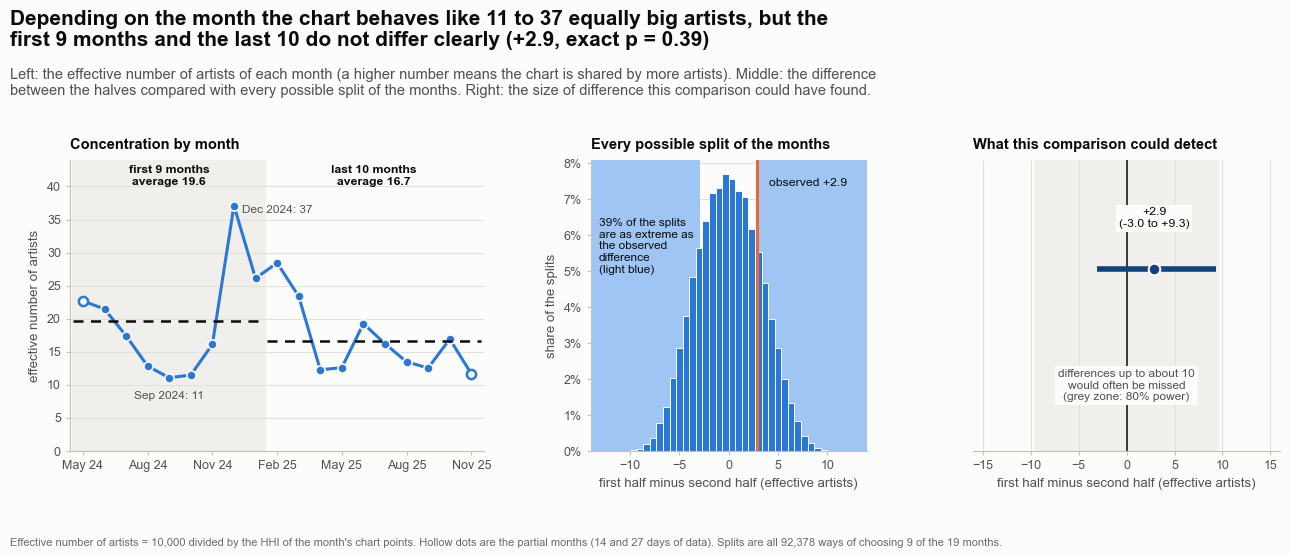

In [29]:
# Figure 13 - H8: how concentrated is the chart month by month, and could the two halves of the period have been told apart?
def month_text(year_month, short=True):
    """'2024-09' -> 'Sep 2024' (or 'Sep 24')."""
    return pd.Timestamp(f"{year_month}-01").strftime("%b %y" if short else "%b %Y")

fig, (ax1, ax2, ax3) = make_fig(13.6, 5.7, 1, 3, left=0.95, right=0.55, bottom=0.95, wspace=0.32, panel_titles=True, width_ratios=[1.35, 0.9, 1.0],
                                title=f"Depending on the month the chart behaves like {FACTS['h8_min']:.0f} to {FACTS['h8_max']:.0f} equally big artists, but the first {FACTS['h8_first_n']} months and the last "
                                      f"{FACTS['h8_second_n']} do not differ clearly ({FACTS['h8_diff']:+.1f}, exact p = {FACTS['h8_exact_p']:.2f})",
                                subtitle="Left: the effective number of artists of each month (a higher number means the chart is shared by more artists). Middle: the difference between the halves compared with "
                                         "every possible split of the months. Right: the size of difference this comparison could have found.",
                                note_text=f"Effective number of artists = 10,000 divided by the HHI of the month's chart points. Hollow dots are the partial months ({FACTS['h8_partial_first_days']} and "
                                          f"{FACTS['h8_partial_last_days']} days of data). Splits are all {FACTS['h8_splits']:,} ways of choosing {FACTS['h8_first_n']} of the {FACTS['h8_months']} months.")
positions = np.arange(len(effective))
ax1.axvspan(-0.5, half - 0.5, color=style.NEUTRAL_MID, zorder=0)
ax1.plot(positions, effective, color=style.BLUE, linewidth=2.2, zorder=2)
ax1.scatter(positions[1:-1], effective[1:-1], s=44, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=3)
ax1.scatter(positions[[0, -1]], effective[[0, -1]], s=44, facecolor=style.SURFACE, edgecolor=style.BLUE, linewidth=1.8, zorder=3)
ax1.hlines(FACTS["h8_first_mean"], -0.45, half - 0.55, color=style.INK, linewidth=1.8, linestyle=(0, (4, 3)), zorder=4)
ax1.hlines(FACTS["h8_second_mean"], half - 0.45, len(effective) - 0.55, color=style.INK, linewidth=1.8, linestyle=(0, (4, 3)), zorder=4)
ax1.text(half / 2 - 0.5, 43.2, f"first {half} months\naverage {FACTS['h8_first_mean']:.1f}", ha="center", va="top", fontsize=8.8, color=style.INK, fontweight="bold")
ax1.text(half + (len(effective) - half) / 2 - 0.5, 43.2, f"last {len(effective) - half} months\naverage {FACTS['h8_second_mean']:.1f}", ha="center", va="top", fontsize=8.8,
         color=style.INK, fontweight="bold")
low_i, high_i = int(np.argmin(effective)), int(np.argmax(effective))
direct_label(ax1, low_i, effective[low_i] - 2.0, f"{month_text(month_labels[low_i], False)}: {effective[low_i]:.0f}", ha="center", va="top", size=8.6)
direct_label(ax1, high_i + 0.35, effective[high_i] - 0.6, f"{month_text(month_labels[high_i], False)}: {effective[high_i]:.0f}", ha="left", va="center", size=8.6)
ticks = list(range(0, len(effective), 3))
ax1.set_xticks(ticks)
ax1.set_xticklabels([month_text(month_labels[i]) for i in ticks])
ax1.set_xlim(-0.6, len(effective) - 0.4)
ax1.set_ylim(0, 44)
ax1.set_ylabel("effective number of artists")
style_axes(ax1, grid="y")
panel_title(ax1, "Concentration by month")

null = exact8.detail["null"]
edges8 = np.linspace(-14, 14, 43)
ax2.axvspan(abs(difference), 14, color=style.BLUE_STEPS[200], zorder=1)
ax2.axvspan(-14, -abs(difference), color=style.BLUE_STEPS[200], zorder=1)
ax2.hist(null, bins=edges8, color=style.BLUE, edgecolor=style.SURFACE, linewidth=0.7, zorder=2, weights=np.full(len(null), 100 / len(null)))
ax2.axvline(difference, color=style.ORANGE, linewidth=2.2, zorder=4)
ax2.annotate(f"observed {difference:+.1f}", xy=(difference, ax2.get_ylim()[1] * 0.92), xytext=(difference + 1.2, ax2.get_ylim()[1] * 0.92), ha="left", va="center", fontsize=8.8, color=style.INK)
ax2.text(0.03, 0.80, f"{100 * FACTS['h8_exact_p']:.0f}% of the splits\nare as extreme as\nthe observed\ndifference\n(light blue)", transform=ax2.transAxes, ha="left", va="top", fontsize=8.6,
         color=style.INK)
ax2.set_xlim(-14, 14)
ax2.set_xlabel("first half minus second half (effective artists)")
ax2.set_ylabel("share of the splits")
ax2.yaxis.set_major_formatter(percent_formatter())
style_axes(ax2, grid="y")
panel_title(ax2, "Every possible split of the months")

ax3.axvspan(-FACTS["h8_mde"], FACTS["h8_mde"], color=style.NEUTRAL_MID, zorder=0)
ax3.axvline(0, color=style.INK, linewidth=1.1, zorder=1)
ax3.hlines(0, FACTS["h8_diff_low"], FACTS["h8_diff_high"], color=style.BLUE_STEPS[650], linewidth=4.0, zorder=3)
ax3.scatter([difference], [0], s=70, color=style.BLUE_STEPS[650], edgecolor=style.SURFACE, linewidth=1.5, zorder=4)
label_box = {"facecolor": style.SURFACE, "edgecolor": "none", "pad": 2.0}
ax3.text(difference, -0.22, f"{difference:+.1f}\n({FACTS['h8_diff_low']:+.1f} to {FACTS['h8_diff_high']:+.1f})", ha="center", va="bottom", fontsize=8.8, color=style.INK, bbox=label_box, zorder=5)
ax3.text(0, 0.55, f"differences up to about {FACTS['h8_mde']:.0f}\nwould often be missed\n(grey zone: 80% power)", ha="center", va="top", fontsize=8.6, color=style.INK_2, bbox=label_box, zorder=5)
ax3.set_xlim(-16, 16)
ax3.set_ylim(1.0, -0.6)
ax3.set_yticks([])
ax3.set_xlabel("first half minus second half (effective artists)")
style_axes(ax3, grid="x", left_spine=False)
panel_title(ax3, "What this comparison could detect")
save_fig(fig, "p5_13_h8_monthly_concentration", FIG_DIR)
plt.show()

**What to notice**

- The chart behaves like 11 equally big artists in September 2024 and like 37 in December 2024. The months differ by up to 26 effective artists, about 9 times the difference between the halves.
- The first 9 months average 19.6 effective artists and the last 10 16.7: a difference of +2.9 (interval -3.0 to +9.3). The exact p-value is p = 0.39: about 39 in 100 splits of the months into groups of 9 and 10 produce a difference at least that large.
- The comparison could only have found a difference of about 10 effective artists or more with 80% power (1.4 standard deviations of the months). The observed difference is 0.41 standard deviations of the months, a small effect. So H8 is *Not supported*, which is not the same as "the chart is equally concentrated in both halves": it is that the months are too variable, and too few, to show a difference of this size.
- No version of the comparison changes the answer: the Welch test gives p = 0.39 and Mann-Whitney p = 0.65; without the two part months, p = 0.60 or p = 0.22 depending on how the 17 months are split; a trend over the months gives p = 0.30 (Kendall's tau -0.18). Season and trend can not be told apart in 19 months.

## Section 14 - All ten together: register, corrections and verdicts

Sections 4 to 13 each tested one claim. Here the ten are placed side by side, because a question that none of them could answer alone now matters: how many of the ten can be believed, when ten were tried at once? Judged one by one at the 5% level, ten claims that were all false would still give about a 40% chance that at least one of them looks significant by luck. So the ten primary p-values are corrected **together**. The notebook uses Holm's method, which keeps the chance of even one false alarm among the ten at 5% or below and is a little less strict than the simple "multiply by ten" rule. Benjamini-Hochberg is shown beside it: it accepts that a small share of the claims called significant may be wrong, and in return it asks for less. The verdict of each claim comes from one rule, written down in Section 2: **Supported** if the Holm p-value is below 0.05, **Suggestive** if the raw p-value is below 0.05 but the Holm p-value is not, **Not supported** if the raw p-value is 0.05 or more. The correction counts these ten claims. It does not count the other patterns that Phase 4 might have noticed before these ten were chosen, so the verdicts stay on the optimistic side.

**What this code is.** The register of the ten claims. The cell first gives every claim a short name and every verdict a colour (both are used in the charts that follow), and defines a small helper that adds one row to the register. Then it adds the ten rows. Each row takes its question, its unit and the names of the planned and the primary test from the plan of Section 2, and its numbers from the sections above: the number of units, the planned p-value, the primary p-value, the effect with its 95% interval and its unit, a standard measure of effect size with a size word (negligible, small, medium or large), and a short caveat in plain words. The register then works out the two corrected values for every claim, Holm's p-value and the Benjamini-Hochberg q-value, and applies the verdict rule.

**Why we need it.** Ten separate sections are hard to compare, and it is easy to remember the claims that worked and forget the ones that did not. One register with the same columns for every claim takes that choice away. It is also the table that the later phases read, so a verdict never has to be typed in again by hand. And the correction has to be made on all ten at once, because the whole point of it is that the more claims are tried, the stricter each one has to be.

**What will happen.** No result number is typed by hand: each one is read from `FACTS`, the numbers stored by the cells above, and the caveats are built from the same numbers. The code checks that the register holds exactly ten different claims, stores the counts, the lists of claims for each verdict, the corrected values and a few comparisons of planned against primary p-values as facts, and then displays a table (planned p, primary p, Holm p, Benjamini-Hochberg q, verdict and size word for every claim, with p-values below 0.001 shown as "< 0.001") and one sentence.

**Expected outcome.** A table of ten rows. Judged one by one with the planned tests, 8 of the 10 claims would count as significant. With the primary tests and Holm's correction, 6 are supported (H2, H3, H4, H5, H6, H7), 2 suggestive (H1, H10) and 2 not supported (H8, H9). Benjamini-Hochberg, the gentler correction, counts 6 claims below 0.05.

**Motive.** Decide, with one rule applied to all ten claims alike, what may be called a finding.

In [30]:
# Section 14 - all ten claims together: the register, the corrections for ten tests and the verdicts
SHORT = {"H1": "Explicit songs reach the top 10 more often", "H2": "Singles stay longer than album tracks", "H3": "Popularity differs between the three tiers",
         "H4": "Average popularity falls over the period", "H5": "Entry place changes how long a run lasts", "H6": "First-time entries cluster on Monday and Tuesday",
         "H7": "Longer songs reach the top 10 more often", "H8": "Concentration differs between the two halves", "H9": "Collaborations reach the top 10 less often",
         "H10": "Explicit songs stay longer only among singles"}

verdict_colours = {"Supported": style.BLUE_STEPS[650], "Suggestive": style.BLUE_STEPS[300], "Not supported": style.AXIS}      # the colour of each verdict in every chart that follows


def add_to_register(hypothesis, **fields):
    """Store one row of the register. The question, the unit and the names of the two tests come from the plan of Section 2; the numbers come from the sections above."""
    row = PLAN.loc[hypothesis]
    REGISTER.add(hypothesis=hypothesis, question=row["question"], unit=row["unit"], planned_test=row["planned_test"], primary_test=row["primary_test"], **fields)


add_to_register("H1", n=FACTS["songs"], planned_p=FACTS["h1_chi2_p"], primary_p=FACTS["h1_wild_p"], effect=FACTS["h1_diff_pp"], effect_low=FACTS["h1_diff_low"], effect_high=FACTS["h1_diff_high"],
                effect_unit="percentage points (explicit minus not explicit)", standard_metric="Cohen's h", standard_size=FACTS["h1_h"], size_word=FACTS["h1_h_word"],
                caveat=f"Explicit songs come in artist families (intraclass correlation {FACTS['icc_explicit']:.2f}). The planned test gives {FACTS['h1_chi2_p_text']}, the artist-aware test {FACTS['h1_wild_p_text']}; "
                       f"the interval {FACTS['h1_diff_low']:.1f} to {FACTS['h1_diff_high']:.1f} points is wide and the claim does not survive the correction for ten tests.")
add_to_register("H2", n=FACTS["songs"], planned_p=FACTS["h2_mwu_p"], primary_p=FACTS["h2_wild_p"], effect=FACTS["h2_ratio"], effect_low=FACTS["h2_ratio_low"], effect_high=FACTS["h2_ratio_high"],
                effect_unit="ratio of typical days on the chart (single / album track)", standard_metric="Cliff's delta", standard_size=FACTS["h2_cliff"], size_word=FACTS["h2_cliff_word"],
                caveat=f"Songs cut off by the edges of the file stay shorter on paper; the check on songs followed from start to end ({FACTS['h2_complete_p_text']}) and the log-rank test on first runs ({FACTS['h2_logrank_p_text']}) agree.")
add_to_register("H3", n=FACTS["h3_songs"], planned_p=FACTS["h3_anova_p"], primary_p=FACTS["h3_wild_p"], effect=FACTS["h3_pair_top_vs_mid"], effect_low=FACTS["h3_pair_top_vs_mid_low"],
                effect_high=FACTS["h3_pair_top_vs_mid_high"], effect_unit="popularity points (Top 10 minus 11-20, the largest of the three pairs)", standard_metric="eta squared",
                standard_size=FACTS["h3_eta2"], size_word=FACTS["h3_eta2_word"],
                caveat=f"Only {100 * FACTS['h3_eta2']:.0f}% of the differences between songs sit between tiers. Within the same song the Top 10 is {FACTS['h3_within_gap_all']:+.1f} points against 21-50 over all days, "
                       f"so which songs sit where matters more than the tier itself.")
add_to_register("H4", n=FACTS["h4_all_days"], planned_p=FACTS["h4_all_ols_p"], primary_p=FACTS["h4_all_primary_p"], effect=FACTS["h4_all_slope100"], effect_low=FACTS["h4_all_block_low"],
                effect_high=FACTS["h4_all_block_high"], effect_unit="popularity points per 100 days", standard_metric="Kendall's tau (Mann-Kendall)",
                standard_size=FACTS["h4_all_tau"], size_word=FACTS["h4_all_tau_word"],
                caveat=f"Days are correlated (lag-1 {FACTS['h4_all_rho_resid']:.2f} after removing the line), so the straight-line test ({FACTS['h4_all_ols_p_text']}) is far too eager. The drop is small: "
                       f"{abs(FACTS['h4_all_total_change']):.1f} points over {FACTS['h4_all_days']} days. For songs past their first week the slope is {FACTS['h4_est_slope100']:.2f} per 100 days ({FACTS['h4_est_primary_p_text']}).")
add_to_register("H5", n=FACTS["h5_runs"], planned_p=FACTS["h5_kw_p"], primary_p=FACTS["h5_wild_p"], effect=FACTS["h5_rho"], effect_low=FACTS["h5_rho_low"], effect_high=FACTS["h5_rho_high"],
                effect_unit="rank correlation of entry place and run length", standard_metric="epsilon squared", standard_size=FACTS["h5_eps2"], size_word=FACTS["h5_eps2_word"],
                caveat=f"Partly arithmetic: a run that begins at place 45 can end after losing five places. The pattern holds when each artist is compared with itself ({FACTS['h5_same_p_text']}) "
                       f"and when cut-off runs are handled (log-rank {FACTS['h5_logrank_p_text']}). The p-value sits at the smallest value the bootstrap can give.")
add_to_register("H6", n=FACTS["h6_weeks"], planned_p=FACTS["h6_chi_p"], primary_p=FACTS["h6_friedman_p"], effect=FACTS["h6_share_mon_tue"], effect_low=FACTS["h6_all_share_low"],
                effect_high=FACTS["h6_all_share_high"], effect_unit=f"percent of first-time entries on Monday and Tuesday (an even spread gives {FACTS['h6_expected_mon_tue']:.1f}%)",
                standard_metric="Kendall's W", standard_size=FACTS["h6_kendall_w"], size_word=FACTS["h6_kendall_w_word"],
                caveat=f"Weekdays are those recorded in the file, whose calendar seems to run about a year ahead of real dates. W looks small because most days have zero or one first-time entry; "
                       f"counting each artist once a day the Monday and Tuesday share is still {FACTS['h6_release_share']:.0f}%.")
add_to_register("H7", n=FACTS["songs"], planned_p=FACTS["h7_ca_p"], primary_p=FACTS["h7_wild_p"], effect=FACTS["h7_slope"], effect_low=FACTS["h7_slope_low"], effect_high=FACTS["h7_slope_high"],
                effect_unit="percentage points more songs in the top 10 per length band", standard_metric="correlation of exact length with reaching the top 10", standard_size=FACTS["h7_r"],
                size_word=FACTS["h7_r_word"],
                caveat=f"The link is not visible among songs of the same artist ({FACTS['h7_same_p_text']}; interval {FACTS['h7_same_low']:+.1f} to {FACTS['h7_same_high']:+.1f} points per band), "
                       f"so length marks which artists make which songs; it is not shown to cause anything.")
add_to_register("H8", n=FACTS["h8_months"], planned_p=FACTS["h8_exact_p"], primary_p=FACTS["h8_exact_p"], effect=FACTS["h8_diff"], effect_low=FACTS["h8_diff_low"], effect_high=FACTS["h8_diff_high"],
                effect_unit="effective number of artists (first half minus second half)", standard_metric="Cohen's d (in standard deviations of the months)", standard_size=FACTS["h8_d"],
                size_word=FACTS["h8_d_word"],
                caveat=f"With {FACTS['h8_months']} months only a difference of about {FACTS['h8_mde']:.0f} effective artists would have been found with 80% power, while the months range from {FACTS['h8_min']:.0f} to "
                       f"{FACTS['h8_max']:.0f}. Season and trend cannot be told apart in this time.")
add_to_register("H9", n=FACTS["songs"], planned_p=FACTS["h9_chi2_p"], primary_p=FACTS["h9_wild_p"], effect=FACTS["h9_diff_pp"], effect_low=FACTS["h9_diff_low"], effect_high=FACTS["h9_diff_high"],
                effect_unit="percentage points (collaboration minus solo)", standard_metric="Cohen's h", standard_size=FACTS["h9_h"], size_word=FACTS["h9_h_word"],
                caveat=f"Not significant is not the same as equal: the test could only have found a difference of {FACTS['h9_mdd_pp']:.0f} points or more, and equality within {FACTS['h9_margin_pp']:.0f} points "
                       f"is not shown either ({FACTS['h9_tost_p_text']}).")
add_to_register("H10", n=FACTS["songs"], planned_p=FACTS["h10_planned_p"], primary_p=FACTS["h10_wild_p"], effect=FACTS["h10_ratio_of_ratios"], effect_low=FACTS["h10_ror_low"], effect_high=FACTS["h10_ror_high"],
                effect_unit="ratio of ratios (explicit effect among singles / explicit effect among album tracks)", standard_metric="interaction in standard deviations of log days",
                standard_size=FACTS["h10_d"], size_word=FACTS["h10_d_word"],
                caveat=f"A borderline interaction: {FACTS['h10_planned_p_text']} when songs are treated as independent, {FACTS['h10_wild_p_text']} with artists allowed for, and the interval "
                       f"{FACTS['h10_ror_low']:.2f} to {FACTS['h10_ror_high']:.2f} is wide. It does not survive the correction for ten tests.")

family = REGISTER.to_frame().set_index("hypothesis")
assert len(family) == 10 and family.index.is_unique, "the register must hold the ten hypotheses once each"
FACTS["fam_planned_significant"] = int((family["planned_p"] < ALPHA).sum())
FACTS["fam_primary_significant"] = int((family["primary_p"] < ALPHA).sum())
FACTS["fam_bh_significant"] = int((family["bh_q"] < ALPHA).sum())
in_order = sorted(family.index, key=lambda h: int(h[1:]))
FACTS["fam_planned_smaller_n"] = int((family["planned_p"] < family["primary_p"]).sum())          # claims for which the planned test sees more evidence than the primary test allows
FACTS["fam_planned_larger_list"] = ", ".join(h for h in in_order if family.loc[h, "planned_p"] > family.loc[h, "primary_p"]) or "none"
FACTS["fam_planned_equal_list"] = ", ".join(h for h in in_order if family.loc[h, "planned_p"] == family.loc[h, "primary_p"]) or "none"
for verdict_name, key in (("Supported", "supported"), ("Suggestive", "suggestive"), ("Not supported", "not_supported")):
    chosen = [h for h in family.index if family.loc[h, "verdict"] == verdict_name]
    FACTS[f"fam_n_{key}"] = len(chosen)
    FACTS[f"fam_list_{key}"] = ", ".join(sorted(chosen, key=lambda h: int(h[1:])))
for h in family.index:
    FACTS[f"fam_holm_{h.lower()}"] = float(family.loc[h, "holm_p"])
    FACTS[f"fam_holm_text_{h.lower()}"] = format_p(family.loc[h, "holm_p"])
    FACTS[f"fam_bh_{h.lower()}"] = float(family.loc[h, "bh_q"])
    FACTS[f"fam_verdict_{h.lower()}"] = family.loc[h, "verdict"]

shown = family[["planned_p", "primary_p", "holm_p", "bh_q", "verdict", "size_word"]].copy()
for column in ("planned_p", "primary_p", "holm_p", "bh_q"):
    shown[column] = shown[column].map(lambda v: "< 0.001" if v < 0.001 else f"{v:.3f}")
display(shown.loc[sorted(shown.index, key=lambda h: int(h[1:]))])
print(f"Judged one by one with the planned tests, {FACTS['fam_planned_significant']} of the {len(family)} claims would be 'significant'. With the artist-aware tests and Holm's correction, "
      f"{FACTS['fam_n_supported']} are supported ({FACTS['fam_list_supported']}), {FACTS['fam_n_suggestive']} suggestive ({FACTS['fam_list_suggestive']}), {FACTS['fam_n_not_supported']} not supported ({FACTS['fam_list_not_supported']}).")

,planned_p,primary_p,holm_p,bh_q,verdict,size_word
hypothesis,,,,,,
H1,0.021,0.042,0.166,0.056,Suggestive,negligible
H2,< 0.001,0.003,0.018,0.005,Supported,small
H3,< 0.001,0.002,0.017,0.005,Supported,small
H4,< 0.001,0.002,0.017,0.005,Supported,small
H5,< 0.001,< 0.001,< 0.001,< 0.001,Supported,medium
H6,< 0.001,< 0.001,< 0.001,< 0.001,Supported,small
H7,0.009,0.003,0.018,0.005,Supported,negligible
H8,0.391,0.391,0.783,0.435,Not supported,small
H9,0.346,0.438,0.783,0.438,Not supported,negligible


Judged one by one with the planned tests, 8 of the 10 claims would be 'significant'. With the artist-aware tests and Holm's correction, 6 are supported (H2, H3, H4, H5, H6, H7), 2 suggestive (H1, H10), 2 not supported (H8, H9).


**What this code is.** Figure 14. One row per claim, sorted by the primary p-value, on a log scale (each step to the left is ten times smaller). Every row has three marks: a grey cross for the planned test, a hollow circle for the primary test, which allows for related rows, and a filled circle for that p-value after Holm's correction. A short line joins the two circles and is coloured by the verdict, which is also written at the right. The dashed vertical line is p = 0.05. A planned p-value too small for the axis is drawn as an arrow at the left edge.

**Why we need it.** The table gives the numbers; the picture gives the distances. Two things push a claim to the right in this figure, and the reader can see them one at a time: allowing for related rows (from the cross to the hollow circle) and correcting for ten tests (from the hollow to the filled circle). A claim whose filled circle is still to the left of the dashed line has paid both prices and survived.

**What will happen.** The code draws the three marks for all ten claims, the dashed line and the verdict labels, and saves the picture as `p5_14_p_values_and_correction.png`.

**Expected outcome.** Crosses that are mostly to the left of the hollow circles; lines of about one step on the log scale for the strongest claims, getting shorter towards the weakest (Holm multiplies the smallest p-value by about 10 and the largest by about 2); two claims whose hollow circle is left of the dashed line and whose filled circle is right of it; and two claims that stay far to the right of the line in every version.

**Motive.** Show what each of the two corrections costs, claim by claim.

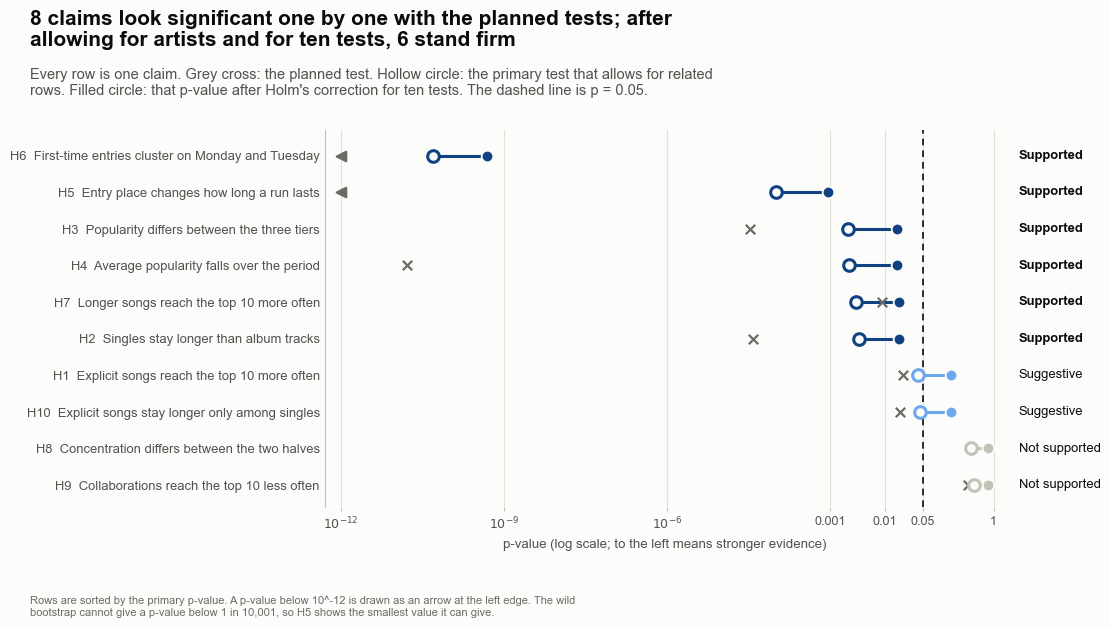

In [31]:
# Figure 14 - the ten p-values: what the planned test said, what the artist-aware test said, and what is left after the correction for ten tests
order = list(family.sort_values("primary_p").index)
floor = 1e-12                                                                                    # p-values below this are drawn at the left edge with an arrow

fig, ax = make_fig(11.6, 6.4, left=3.3, right=1.5, bottom=0.95, panel_titles=False,
                   title=f"{FACTS['fam_planned_significant']} claims look significant one by one with the planned tests; after allowing for artists and for ten tests, "
                         f"{FACTS['fam_n_supported']} stand firm",
                   subtitle="Every row is one claim. Grey cross: the planned test. Hollow circle: the primary test that allows for related rows. Filled circle: that p-value after Holm's correction "
                            "for ten tests. The dashed line is p = 0.05.",
                   note_text="Rows are sorted by the primary p-value. A p-value below 10^-12 is drawn as an arrow at the left edge. The wild bootstrap cannot give a p-value below 1 in 10,001, "
                             "so H5 shows the smallest value it can give.")
for row, hypothesis in enumerate(order):
    record = family.loc[hypothesis]
    colour = verdict_colours[record["verdict"]]
    raw, adjusted, planned = record["primary_p"], record["holm_p"], record["planned_p"]
    ax.hlines(row, max(raw, floor), max(adjusted, floor), color=colour, linewidth=2.2, zorder=2)
    ax.scatter([max(raw, floor)], [row], s=70, facecolor=style.SURFACE, edgecolor=colour, linewidth=2.2, zorder=4)
    ax.scatter([max(adjusted, floor)], [row], s=70, color=colour, edgecolor=style.SURFACE, linewidth=1.3, zorder=5)
    ax.scatter([max(planned, floor)], [row], s=46, marker="<" if planned < floor else "x", color=style.MUTED, linewidth=1.6, zorder=3)
    ax.annotate(record["verdict"], xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9.4, color=style.INK,
                fontweight="bold" if record["verdict"] == "Supported" else "normal", annotation_clip=False)
ax.axvline(ALPHA, color=style.INK, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xlim(floor * 0.5, 1.6)
ax.set_xticks([1e-12, 1e-9, 1e-6, 1e-3, 1e-2, 0.05, 1])
ax.set_xticklabels([r"$10^{-12}$", r"$10^{-9}$", r"$10^{-6}$", "0.001", "0.01", "0.05", "1"], fontsize=9)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{h}  {SHORT[h]}" for h in order], fontsize=9.4)
ax.set_ylim(len(order) - 0.4, -0.7)
ax.set_xlabel("p-value (log scale; to the left means stronger evidence)")
style_axes(ax, grid="x", bottom_spine=False)
ax.tick_params(axis="y", length=0)
save_fig(fig, "p5_14_p_values_and_correction", FIG_DIR)
plt.show()

**What to notice**

- In 8 of the 10 rows the grey cross lies to the left of the hollow circle: the planned test, which counts every row as independent, sees more evidence than the primary test allows. H4 is the clearest case, with p < 0.001 for the planned straight-line test and p = 0.002 once days are allowed to be alike. The exceptions are H7, where the primary test is the kinder of the two (p = 0.003 against p = 0.009), and H8, where both are the same exact test.
- Holm's correction moves every filled circle to the right of its hollow circle: the smallest p-value is multiplied by about 10, the next by about 9, and so on. For the middle four the move is easy to see and not decisive: H2 goes from p = 0.003 to p = 0.018, H3 from p = 0.002 to p = 0.017, H4 from p = 0.002 to p = 0.017 and H7 from p = 0.003 to p = 0.018. All four stay below 0.05.
- The 2 suggestive claims (H1, H10) are the ones that lose out. H1 goes from p = 0.042 to p = 0.17 and H10 from p = 0.045 to p = 0.17. Benjamini-Hochberg, the gentler correction, gives 0.056 for H1 and 0.056 for H10, which is also just above 0.05, so the verdict does not depend on which of the two corrections is used.
- H8 (p = 0.39) and H9 (p = 0.44) are far to the right of the line before and after the correction. H5 is drawn at 0.0001, the smallest value that 10,000 bootstrap repeats can give; its true p-value is much smaller, and the Holm correction changes nothing that matters for it.

**What this code is.** Figure 15, the evidence board. It is a table drawn as a picture, with one row for each of the ten claims: the claim in one line, the size of the effect in its own unit with its 95% interval (the interval allows for related rows), the size word, the primary p-value, the Holm p-value, and the verdict in a coloured box (dark blue for supported, light blue for suggestive, grey for not supported). Rows alternate in shade so that the eye can follow a claim across.

**Why we need it.** The ten effects cannot share one axis, because they are in ten different units (percentage points, ratios, correlations, popularity points, effective artists). A board reads them side by side without pretending that they are comparable in size. The size word and the verdict are separate columns on purpose: a claim can be sure and small, or large and uncertain, and the two columns say which.

**What will happen.** The code first writes the effect of every claim as text, in its own unit, and stores each text as a fact, so that the closing summary can quote it. It then draws the board and saves the picture as `p5_15_evidence_board.png`.

**Expected outcome.** Ten rows, 6 dark blue boxes, 2 light blue and 2 grey, and a Size column that is mostly "small" or "negligible".

**Motive.** Give the reader one page from which the whole notebook can be read.

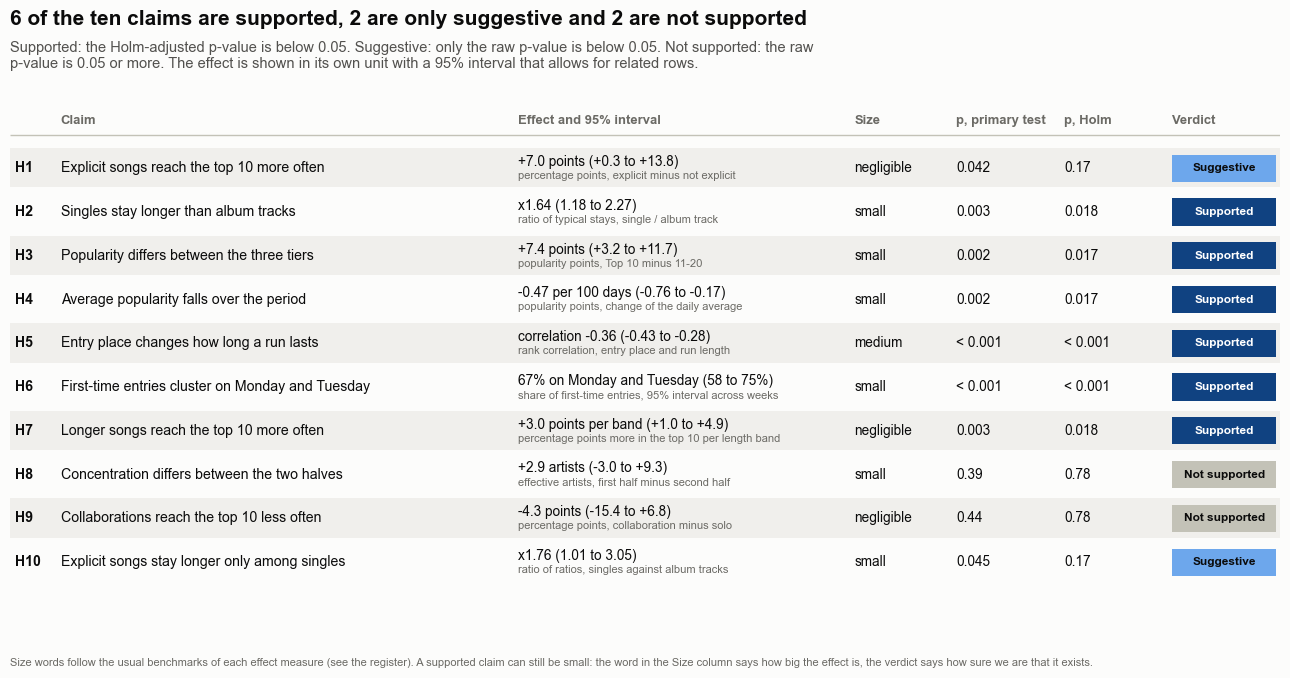

In [32]:
# Figure 15 - the evidence board: all ten claims, how big each effect is and what the verdict is
effect_format = {"H1": lambda r: f"{r.effect:+.1f} points ({r.effect_low:+.1f} to {r.effect_high:+.1f})",
                 "H2": lambda r: f"x{r.effect:.2f} ({r.effect_low:.2f} to {r.effect_high:.2f})",
                 "H3": lambda r: f"{r.effect:+.1f} points ({r.effect_low:+.1f} to {r.effect_high:+.1f})",
                 "H4": lambda r: f"{r.effect:+.2f} per 100 days ({r.effect_low:+.2f} to {r.effect_high:+.2f})",
                 "H5": lambda r: f"correlation {r.effect:.2f} ({r.effect_low:.2f} to {r.effect_high:.2f})",
                 "H6": lambda r: f"{r.effect:.0f}% on Monday and Tuesday ({r.effect_low:.0f} to {r.effect_high:.0f}%)",
                 "H7": lambda r: f"{r.effect:+.1f} points per band ({r.effect_low:+.1f} to {r.effect_high:+.1f})",
                 "H8": lambda r: f"{r.effect:+.1f} artists ({r.effect_low:+.1f} to {r.effect_high:+.1f})",
                 "H9": lambda r: f"{r.effect:+.1f} points ({r.effect_low:+.1f} to {r.effect_high:+.1f})",
                 "H10": lambda r: f"x{r.effect:.2f} ({r.effect_low:.2f} to {r.effect_high:.2f})"}
effect_unit_short = {"H1": "percentage points, explicit minus not explicit", "H2": "ratio of typical stays, single / album track", "H3": "popularity points, Top 10 minus 11-20",
                     "H4": "popularity points, change of the daily average", "H5": "rank correlation, entry place and run length", "H6": "share of first-time entries, 95% interval across weeks",
                     "H7": "percentage points more in the top 10 per length band", "H8": "effective artists, first half minus second half",
                     "H9": "percentage points, collaboration minus solo", "H10": "ratio of ratios, singles against album tracks"}
for h in family.index:
    FACTS[f"fam_effect_{h.lower()}"] = effect_format[h](family.loc[h])

hypotheses = sorted(family.index, key=lambda h: int(h[1:]))
columns = {"id": 0.004, "claim": 0.04, "effect": 0.40, "size": 0.665, "p": 0.745, "holm": 0.83, "verdict": 0.915}
fig, ax = make_fig(13.4, 6.9, left=0.35, right=0.35, bottom=0.75, panel_titles=False,
                   title=f"{FACTS['fam_n_supported']} of the ten claims are supported, {FACTS['fam_n_suggestive']} are only suggestive and {FACTS['fam_n_not_supported']} are not supported",
                   subtitle="Supported: the Holm-adjusted p-value is below 0.05. Suggestive: only the raw p-value is below 0.05. Not supported: the raw p-value is 0.05 or more. "
                            "The effect is shown in its own unit with a 95% interval that allows for related rows.",
                   note_text="Size words follow the usual benchmarks of each effect measure (see the register). A supported claim can still be small: the word in the Size column says how big the effect is, "
                             "the verdict says how sure we are that it exists.")
ax.set_xlim(0, 1)
ax.set_ylim(len(hypotheses) - 0.3, -1.45)
ax.axis("off")
for name, label in (("claim", "Claim"), ("effect", "Effect and 95% interval"), ("size", "Size"), ("p", "p, primary test"), ("holm", "p, Holm"), ("verdict", "Verdict")):
    ax.text(columns[name], -1.05, label, ha="left", va="center", fontsize=9.4, color=style.MUTED, fontweight="bold")
ax.hlines(-0.72, 0, 1, color=style.AXIS, linewidth=1.0)
for row, h in enumerate(hypotheses):
    record = family.loc[h]
    if row % 2 == 0:
        ax.add_patch(plt.Rectangle((0, row - 0.42), 1, 0.9, facecolor=style.NEUTRAL_MID, edgecolor="none", zorder=0))
    ax.text(columns["id"], row + 0.04, h, ha="left", va="center", fontsize=10.2, color=style.INK, fontweight="bold")
    ax.text(columns["claim"], row + 0.04, SHORT[h], ha="left", va="center", fontsize=10.2, color=style.INK)
    ax.text(columns["effect"], row - 0.1, effect_format[h](record), ha="left", va="center", fontsize=9.8, color=style.INK)
    ax.text(columns["effect"], row + 0.22, effect_unit_short[h], ha="left", va="center", fontsize=8.0, color=style.MUTED)
    ax.text(columns["size"], row + 0.04, str(record["size_word"]), ha="left", va="center", fontsize=9.8, color=style.INK)
    ax.text(columns["p"], row + 0.04, format_p(record["primary_p"]).replace("p = ", "").replace("p < ", "< "), ha="left", va="center", fontsize=9.8, color=style.INK)
    ax.text(columns["holm"], row + 0.04, format_p(record["holm_p"]).replace("p = ", "").replace("p < ", "< "), ha="left", va="center", fontsize=9.8, color=style.INK)
    fill = verdict_colours[record["verdict"]]
    ax.add_patch(plt.Rectangle((columns["verdict"], row - 0.27), 0.082, 0.62, facecolor=fill, edgecolor="none", zorder=2))
    ax.text(columns["verdict"] + 0.041, row + 0.04, record["verdict"], ha="center", va="center", fontsize=8.6, fontweight="bold",
            color="white" if record["verdict"] == "Supported" else style.INK, zorder=3)
save_fig(fig, "p5_15_evidence_board", FIG_DIR)
plt.show()

**What to notice**

- Read across a row, not only down the verdict column. Only one effect, H5, is medium. Every other effect is small or negligible by the usual benchmarks, including the five other supported claims. A supported claim is one that we are fairly sure exists; the Size column says whether it matters.
- H6 looks odd on the board. The share is large (67% of the first-time entries fall on a Monday or Tuesday, against 29% for an even spread), yet the Size column says small. That word comes from Kendall's W, which can not become large when most days have zero or one first-time entry (Section 11). The share is the better description. H7 is supported but negligible (correlation 0.07), and H4 is a fall of 2.6 points in the average popularity over 555 days.
- The two suggestive claims have intervals that almost touch the value of no effect: H1 is +7.0 points (+0.3 to +13.8) and H10 is x1.76 (1.01 to 3.05). The two claims that are not supported have intervals that run well to both sides of it: H8 is +2.9 artists (-3.0 to +9.3) and H9 is -4.3 points (-15.4 to +6.8).
- So "not supported" does not mean "no effect". The interval of H9, from -15 to +7 points, takes in collaborations that reach the top 10 much less often than solo songs and also somewhat more often, and equality within 5 points is not shown either (p = 0.45). It means that these data can not tell.

## Section 15 - Do the claims hold up? Two halves, and without the biggest artist

A claim can be supported on the whole file and still be fragile. Two stress tests follow, and both reuse the primary tests of Sections 4 to 13 exactly as they were run there. **(a) The two halves.** The period is cut in two on a Monday, 24 Feb 2025, which leaves 282 snapshot days before the cut and 273 from it on, and every claim is run again on each half. A real pattern should show up in both halves, though less sharply, because each half has less data. This is not an independent replication: the halves are two looks at one file, and for the popularity claims (H3 and H4) a song that stays on the chart across the cut can appear on both sides. It does show whether a claim is the work of one stretch of time. **(b) Without the biggest artist.** Taylor Swift has 96 of the 944 songs (10.2%), the most of any artist, so all ten claims are run again without that artist, and Holm's correction is repeated on the ten new p-values. A claim that rests on one catalogue shows up here.

**What this code is.** Part (a), the halves. Four things happen in this cell. First, the cut: the first Monday on or after the middle snapshot day, so that no calendar week is split in two. Second, the primary tests of Sections 4 to 13 are written as small functions that can be run on any part of the data: `song_level_checks` (H1, H9 and H7 on the songs given, and H2 and H10 on those of them that were followed from their first to their last day on the chart), `tier_check` (H3), `trend_check` (H4), `run_check` (H5) and `weekday_check` (H6). Third, every function is run for the first half, for the second half and for the whole period. Fourth, the results are put in a table: the estimate and the p-value in each half next to the whole period, and whether both halves point the same way as the whole. H8 is left out, because it already compares the two halves.

**Why we need it.** The same function run on the whole period must give exactly the numbers of the sections above. The cell asserts this, with the same random seeds, for the estimates and p-values of H1, H3, H4, H5, H6, H7 and H9 and for the finished-stays check of H2 in Section 6. If a function had a mistake, the notebook would stop here instead of letting wrong half-period numbers into the text. H2 and H10 use only songs followed from first to last day, because a song that first appears late in the file has had less time to build up days, and splitting by first appearance would otherwise make the second half look worse for every song, whatever its release format.

**What will happen.** Every test is repeated 10,000 times on every part, which is nine claims on three parts. A song belongs to the half in which it first appeared, a chart run to the half in which it began, a calendar week to the half in which it lies, and a day to the half in which it falls. The cell prints a table of nine rows (the estimate and p-value of the first half, the second half and the whole period, and a yes or no for the same direction) and two sentences: how the data was split, and how many claims point the same way.

**Expected outcome.** 8 of the 9 claims answer "yes" in the last column. Most halves have larger p-values than the whole period, as they usually do with half the data, and 2 claims are below 0.05 in both halves on their own.

**Motive.** Find out whether any claim is the work of one stretch of the data.

In [33]:
# Section 15 - does it hold up? (a) every claim again in each half of the period on its own
middle = daily["date"].iloc[len(daily) // 2]                                                     # the middle snapshot day of the file
cut_date = middle + pd.Timedelta(days=(7 - middle.dayofweek) % 7)                                # the first Monday on or after it: no calendar week is cut in two
top_artist = songs["artist"].value_counts().index[0]                                             # the artist with the most songs on the chart (used in part b)
FACTS["rob_cut_date"] = f"{cut_date:%d %b %Y}"
FACTS["rob_first_days"], FACTS["rob_second_days"] = int((daily["date"] < cut_date).sum()), int((daily["date"] >= cut_date).sum())
FACTS["rob_top_artist"], FACTS["rob_top_artist_songs"] = top_artist, int((songs["artist"] == top_artist).sum())
FACTS["rob_top_artist_pct"] = 100 * FACTS["rob_top_artist_songs"] / FACTS["songs"]

# ---- the same primary tests as in Sections 4 to 13, written as functions that can be run on any part of the data. The seeds are the ones used above, so the "whole period" run
# gives exactly the numbers of those sections (this is checked below).
collab = songs["is_collab"].to_numpy()
finished_song = (songs["run_status"] == "Complete history observed").to_numpy()                  # songs followed from their first to their last day on the chart


def song_level_checks(mask, finished_only=True):
    """H1, H9, H7 on the songs picked by `mask`, and H2, H10 on those of them that were followed from start to end (a song that appeared late has had less time to build up days);
    with finished_only=False H2 and H10 use all songs picked, as in Sections 6 and 7. Returns {claim: (estimate, low, high, p, number of songs)}; shares in percentage points, ratios as ratios."""
    out, code = {}, song_artist[mask]
    for claim, flag, seed in (("H1", explicit, SEED + 100), ("H9", collab, SEED + 200)):
        r = dependence.wild_two_group_test(top10[mask], flag[mask], code, n_boot=N_BOOT, seed=seed)
        out[claim] = (100 * r.estimate, 100 * r.ci_low, 100 * r.ci_high, r.p_value, int(mask.sum()))
    r = dependence.wild_slope_test(top10[mask], length_score[mask], code, n_boot=N_BOOT, seed=SEED + 700)
    out["H7"] = (100 * r.estimate, 100 * r.ci_low, 100 * r.ci_high, r.p_value, int(mask.sum()))
    keep = mask & finished_song if finished_only else mask
    code = song_artist[keep]
    r = dependence.wild_two_group_test(log_days[keep], single[keep], code, n_boot=N_BOOT, seed=SEED + (303 if finished_only else 300))
    out["H2"] = (np.exp(r.estimate), np.exp(r.ci_low), np.exp(r.ci_high), r.p_value, int(keep.sum()))
    r = dependence.wild_interaction_test(log_days[keep], single[keep], explicit[keep], code, n_boot=N_BOOT, seed=SEED + 400)
    out["H10"] = (np.exp(r.estimate), np.exp(r.ci_low), np.exp(r.ci_high), r.p_value, int(keep.sum()))
    return out


def tier_check(rated_rows):
    """H3 on the song-days given: Top 10 minus 11-20 (the pair of the register) with its interval, and the p-value of the three-tier test. Every song counts once, in its home tier."""
    per_tier = rated_rows.groupby(["track_id", "rank_tier"], observed=True)["popularity_clean"].agg(mean="mean", days="size").reset_index()
    homes = (per_tier.sort_values(["track_id", "days", "rank_tier"], ascending=[True, False, True]).drop_duplicates("track_id").merge(songs[["track_id", "artist"]], on="track_id"))
    homes["tier"] = homes["rank_tier"].astype(str)
    code = pd.factorize(homes["artist"])[0]
    three = dependence.wild_k_group_test(homes["mean"].to_numpy(), homes["tier"].to_numpy(), code, n_boot=N_BOOT, seed=SEED + 500)
    pair = homes["tier"].isin(tier_names[:2]).to_numpy()
    top_vs_mid = dependence.wild_two_group_test(homes.loc[pair, "mean"].to_numpy(), (homes.loc[pair, "tier"] == tier_names[0]).to_numpy(), code[pair], n_boot=N_BOOT, seed=SEED + 511)
    return (top_vs_mid.estimate, top_vs_mid.ci_low, top_vs_mid.ci_high, three.p_value, len(homes))


def trend_check(values):
    """H4 on a daily series: change per 100 days, its 95% interval and p-value from the residual block bootstrap (blocks of 14 days). Days without a value are left out."""
    y = np.asarray(values, dtype=float)
    y = y[np.isfinite(y)]
    slopes = dependence.block_bootstrap_trend(y, block=14, n_boot=N_BOOT, seed=SEED + 600)
    low, high = dependence.bootstrap_interval(slopes)
    return (100 * dependence.hac_trend_test(y).estimate, 100 * low, 100 * high, dependence.bootstrap_p_value(slopes), len(y))


def run_check(frame):
    """H5 on the complete runs in `frame`: the rank correlation of entry place and run length with an artist-bootstrap interval, and the p-value of the five-band test."""
    code = pd.factorize(frame["artist"])[0]
    place, length = frame["entry_position"].to_numpy(dtype=float), frame["length"].to_numpy(dtype=float)
    place_rank, length_rank = stats.rankdata(place), stats.rankdata(length)
    bands_here = pd.cut(frame["entry_position"], band_edges, labels=band_names).astype(str).to_numpy()
    five = dependence.wild_k_group_test(length_rank, bands_here, code, n_boot=N_BOOT, seed=SEED + 600)

    def weighted_correlation(weights):
        total = weights.sum(axis=1)
        mean_x, mean_y = (weights @ place_rank) / total, (weights @ length_rank) / total
        covariance = (weights @ (place_rank * length_rank)) / total - mean_x * mean_y
        return covariance / np.sqrt(((weights @ place_rank ** 2) / total - mean_x ** 2) * ((weights @ length_rank ** 2) / total - mean_y ** 2))
    low, high = dependence.bootstrap_interval(dependence.cluster_bootstrap(code, weighted_correlation, n_boot=N_BOOT, seed=SEED + 620))
    return (float(stats.spearmanr(place, length)[0]), low, high, five.p_value, len(frame))


week_start = flow.groupby("week")["date"].min()                                                  # the first snapshot day of every calendar week


def weekday_check(week_set, entries=None):
    """H6 on the calendar weeks given: Monday + Tuesday share of the first-time entries (%) with a bootstrap over whole weeks, and the p-value of the Friedman test on the complete weeks.
    `entries` is the table of first-time entries (one row per song); by default all of them."""
    rows = (debut if entries is None else entries)
    rows = rows[rows["week"].isin(week_set)]
    share = week_interval(rows, week_set, seed=SEED + 700)
    complete_here = [w for w in weekly.index if w in set(week_set)]
    matrix = rows.groupby(["week", "weekday"]).size().unstack(fill_value=0).reindex(columns=range(1, 8), fill_value=0).reindex(complete_here, fill_value=0)
    friedman = classical.friedman_test(matrix.to_numpy())
    return (share[0], share[1], share[2], friedman.p_value, len(rows))


# ---- (a) the halves. Songs belong to the half in which they first appeared, runs to the half in which they began, calendar weeks to the half in which they lie
first_song = (songs["first_seen"] < cut_date).to_numpy()
first_run = (done["start_date"] < cut_date).to_numpy()
first_weeks = [w for w in all_weeks if week_start[w] < cut_date]
second_weeks = [w for w in all_weeks if week_start[w] >= cut_date]
first_days, second_days = (daily["date"] < cut_date).to_numpy(), (daily["date"] >= cut_date).to_numpy()
rated_dates = rated["date"]
everything = {"song": np.ones(len(songs), dtype=bool), "run": np.ones(len(done), dtype=bool), "rated": pd.Series(True, index=rated.index), "day": np.ones(len(daily), dtype=bool)}

halves = {}
for label, song_mask, run_mask, rated_mask, day_mask, week_set in (("first half", first_song, first_run, rated_dates < cut_date, first_days, first_weeks),
                                                                    ("second half", ~first_song, ~first_run, rated_dates >= cut_date, second_days, second_weeks),
                                                                    ("whole period", everything["song"], everything["run"], everything["rated"], everything["day"], all_weeks)):
    halves[label] = song_level_checks(song_mask)
    halves[label]["H3"] = tier_check(rated[rated_mask])
    halves[label]["H4"] = trend_check(daily_pop.to_numpy()[day_mask])
    halves[label]["H5"] = run_check(done[run_mask])
    halves[label]["H6"] = weekday_check(week_set)
    halves[label]["expected_h6"] = 100 * float(flow.loc[flow["week"].isin(week_set), "day_of_week"].isin([1, 2]).mean())      # Monday + Tuesday share of the days if every weekday were alike

# the weekday counts built from the song table are the weekday counts of the daily table (the Friedman matrix of Section 11)
assert (debut.groupby(["week", "weekday"]).size().unstack(fill_value=0).reindex(columns=range(1, 8), fill_value=0).reindex(weekly.index, fill_value=0).to_numpy() == weekly.to_numpy()).all()

# the whole-period run must give exactly the numbers of the sections above, wherever the definition is the same
whole = halves["whole period"]
for claim, fact in (("H1", "h1_diff_pp"), ("H9", "h9_diff_pp"), ("H7", "h7_slope"), ("H5", "h5_rho"), ("H4", "h4_all_slope100"), ("H6", "h6_share_mon_tue")):
    assert abs(whole[claim][0] - FACTS[fact]) < 1e-9, f"{claim}: the whole-period run differs from its section"
for claim, p_fact in (("H1", "h1_wild_p"), ("H9", "h9_wild_p"), ("H7", "h7_wild_p"), ("H3", "h3_wild_p"), ("H4", "h4_all_primary_p"), ("H5", "h5_wild_p"), ("H6", "h6_friedman_p")):
    assert abs(whole[claim][3] - FACTS[p_fact]) < 1e-12, f"{claim}: same seed and same data must give the same p-value"
assert abs(whole["H2"][0] - FACTS["h2_complete_ratio"]) < 1e-9 and format_p(whole["H2"][3]) == FACTS["h2_complete_p_text"], "H2 on finished stays must repeat the check of Section 6"
assert abs(whole["H3"][0] - FACTS["h3_pair_top_vs_mid"]) < 1e-9 and abs(whole["H5"][1] - FACTS["h5_rho_low"]) < 1e-9 and abs(whole["H6"][1] - FACTS["h6_all_share_low"]) < 1e-9

# ---- the table: does each half point the same way as the whole period?
null_value = {"H2": 1.0, "H10": 1.0}
measure = {"H1": "points, explicit minus not explicit", "H2": "ratio of typical stays, single / album track", "H3": "points, Top 10 minus 11-20", "H4": "points per 100 days",
           "H5": "rank correlation", "H6": "% of entries on Monday and Tuesday", "H7": "points more per length band", "H9": "points, collaboration minus solo", "H10": "ratio of ratios"}
claims_checked = ["H1", "H2", "H3", "H4", "H5", "H6", "H7", "H9", "H10"]                        # H8 is itself a comparison of the two halves, so it has no halves of its own


def estimate_text(claim, value):
    return f"x{value:.2f}" if claim in ("H2", "H10") else (f"{value:.1f}%" if claim == "H6" else (f"{value:+.2f}" if claim in ("H4", "H5") else f"{value:+.1f}"))


def side(claim, estimate, label):
    """+1 if the estimate lies above the no-effect value, -1 if below (for H6 the no-effect value is the share an even spread would give in that half)."""
    reference = halves[label]["expected_h6"] if claim == "H6" else null_value.get(claim, 0.0)
    return int(np.sign(estimate - reference))


table_rows = []
for claim in claims_checked:
    first_est, second_est, all_est = halves["first half"][claim], halves["second half"][claim], whole[claim]
    agrees = side(claim, first_est[0], "first half") == side(claim, all_est[0], "whole period") == side(claim, second_est[0], "second half")
    table_rows.append({"claim": claim, "measure": measure[claim], "first half": estimate_text(claim, first_est[0]), "p (first)": format_p(first_est[3]).replace("p = ", "").replace("p < ", "< "),
                       "second half": estimate_text(claim, second_est[0]), "p (second)": format_p(second_est[3]).replace("p = ", "").replace("p < ", "< "),
                       "whole period": estimate_text(claim, all_est[0]), "same direction": "yes" if agrees else "no"})
    FACTS[f"rob_half1_{claim.lower()}"], FACTS[f"rob_half2_{claim.lower()}"] = float(first_est[0]), float(second_est[0])
    FACTS[f"rob_half1_p_{claim.lower()}"], FACTS[f"rob_half2_p_{claim.lower()}"] = float(first_est[3]), float(second_est[3])
    FACTS[f"rob_half1_p_text_{claim.lower()}"], FACTS[f"rob_half2_p_text_{claim.lower()}"] = format_p(first_est[3]), format_p(second_est[3])
    FACTS[f"rob_half1_n_{claim.lower()}"], FACTS[f"rob_half2_n_{claim.lower()}"] = int(first_est[4]), int(second_est[4])
    FACTS[f"rob_whole_{claim.lower()}"] = float(all_est[0])
    FACTS[f"rob_agree_{claim.lower()}"] = bool(agrees)
    FACTS[f"rob_agree_text_{claim.lower()}"] = "yes" if agrees else "no"
halves_table = pd.DataFrame(table_rows).set_index("claim")
FACTS["rob_same_direction"] = int((halves_table["same direction"] == "yes").sum())
FACTS["rob_both_below_05"] = int(sum(halves["first half"][c][3] < ALPHA and halves["second half"][c][3] < ALPHA for c in claims_checked))
FACTS["rob_claims_checked"] = len(claims_checked)
FACTS["rob_n_first_songs"], FACTS["rob_n_second_songs"] = int(first_song.sum()), int((~first_song).sum())
FACTS["rob_n_first_runs"], FACTS["rob_n_second_runs"] = int(first_run.sum()), int((~first_run).sum())
FACTS["rob_n_first_weeks"], FACTS["rob_n_second_weeks"] = len(first_weeks), len(second_weeks)
FACTS["rob_h2_finished_all_ratio"] = float(whole["H2"][0])
FACTS["rob_h10_finished_all_ratio"], FACTS["rob_h10_finished_all_p_text"] = float(whole["H10"][0]), format_p(whole["H10"][3])
FACTS["rob_both_list"] = ", ".join(c for c in claims_checked if halves["first half"][c][3] < ALPHA and halves["second half"][c][3] < ALPHA) or "none"
FACTS["rob_not_same_list"] = ", ".join(c for c in claims_checked if not FACTS[f"rob_agree_{c.lower()}"]) or "none"
FACTS["rob_h4_mean_first"] = float(np.nanmean(daily_pop.to_numpy()[first_days]))                 # the average of the daily average popularity in each half
FACTS["rob_h4_mean_second"] = float(np.nanmean(daily_pop.to_numpy()[second_days]))
FACTS["rob_h4_step"] = FACTS["rob_h4_mean_second"] - FACTS["rob_h4_mean_first"]

display(halves_table)
print(f"Cut at Monday {FACTS['rob_cut_date']}: {FACTS['rob_first_days']} snapshot days before it, {FACTS['rob_second_days']} from it on. Songs: {FACTS['rob_n_first_songs']} first appeared in the first half, "
      f"{FACTS['rob_n_second_songs']} in the second; complete runs: {FACTS['rob_n_first_runs']} and {FACTS['rob_n_second_runs']}; calendar weeks: {FACTS['rob_n_first_weeks']} and {FACTS['rob_n_second_weeks']}.")
print(f"{FACTS['rob_same_direction']} of the {FACTS['rob_claims_checked']} claims point the same way in both halves as in the whole period; {FACTS['rob_both_below_05']} reach p < 0.05 in both halves on their own.")

,measure,first half,p (first),second half,p (second),whole period,same direction
claim,,,,,,,
H1,"points, explicit minus not explicit",+6.4,0.13,+8.7,0.16,+7.0,yes
H2,"ratio of typical stays, single / album track",x1.56,0.022,x1.56,0.14,x1.55,yes
H3,"points, Top 10 minus 11-20",+6.9,< 0.001,+6.6,0.22,+7.4,yes
H4,points per 100 days,-0.03,0.93,-0.40,0.38,-0.47,yes
H5,rank correlation,-0.35,< 0.001,-0.37,< 0.001,-0.36,yes
H6,% of entries on Monday and Tuesday,68.9%,< 0.001,63.9%,< 0.001,66.8%,yes
H7,points more per length band,+2.4,0.060,+3.5,0.048,+3.0,yes
H9,"points, collaboration minus solo",+0.9,0.93,-8.2,0.35,-4.3,no
H10,ratio of ratios,x1.88,0.075,x1.34,0.55,x1.65,yes


Cut at Monday 24 Feb 2025: 282 snapshot days before it, 273 from it on. Songs: 564 first appeared in the first half, 380 in the second; complete runs: 1064 and 817; calendar weeks: 41 and 40.
8 of the 9 claims point the same way in both halves as in the whole period; 2 reach p < 0.05 in both halves on their own.


**What this code is.** Figure 16, nine small panels, one for each claim (H8 is left out). Every panel has three rows: the first half, the second half and the whole period. Each row is a dot, the estimate, with a line for its 95% interval, which allows for related rows, and the p-value of the primary test written beside it. The dashed line marks no effect; for H6 it marks the share that an even spread over the weekdays would give in that period.

**Why we need it.** A table with three estimates and three p-values for each of nine claims is hard to read. In the panels the eye sees at once whether the two halves lie on the same side of the dashed line, whether they are about the size of the whole period, and how much wider the intervals of a half are than the interval of the whole.

**What will happen.** The code draws the nine panels from the table of the previous cell and saves the picture as `p5_16_robustness_halves.png`.

**Expected outcome.** In most panels the three dots sit on the same side of the dashed line, the intervals of the halves are wider than the interval of the whole period, and two panels (H5 and H6) are clear of the dashed line in both halves.

**Motive.** Let the reader see what "holds in both halves" means, and where it does not.

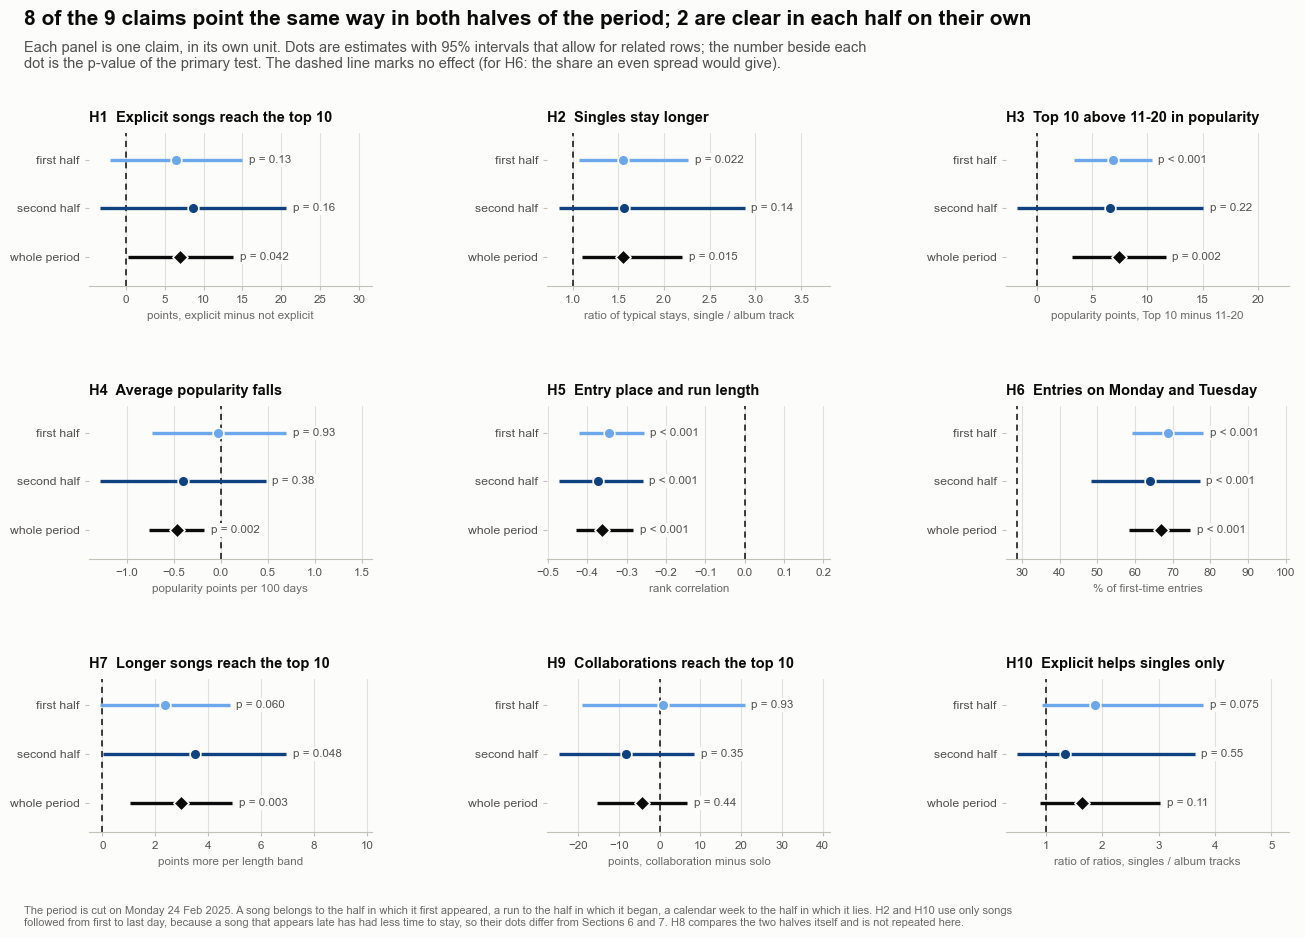

In [34]:
# Figure 16 - each claim in the first half, in the second half and over the whole period
panel_claims = ["H1", "H2", "H3", "H4", "H5", "H6", "H7", "H9", "H10"]
panel_names = {"H1": "H1  Explicit songs reach the top 10", "H2": "H2  Singles stay longer", "H3": "H3  Top 10 above 11-20 in popularity", "H4": "H4  Average popularity falls",
               "H5": "H5  Entry place and run length", "H6": "H6  Entries on Monday and Tuesday", "H7": "H7  Longer songs reach the top 10", "H9": "H9  Collaborations reach the top 10",
               "H10": "H10  Explicit helps singles only"}
panel_units = {"H1": "points, explicit minus not explicit", "H2": "ratio of typical stays, single / album track", "H3": "popularity points, Top 10 minus 11-20",
               "H4": "popularity points per 100 days", "H5": "rank correlation", "H6": "% of first-time entries", "H7": "points more per length band",
               "H9": "points, collaboration minus solo", "H10": "ratio of ratios, singles / album tracks"}
row_names = ["first half", "second half", "whole period"]
row_colours = [style.BLUE_STEPS[300], style.BLUE_STEPS[650], style.INK]

fig, axes = make_fig(13.4, 9.5, 3, 3, left=1.0, right=0.4, bottom=0.8, wspace=0.62, hspace=0.78, panel_titles=True,
                     title=f"{FACTS['rob_same_direction']} of the {FACTS['rob_claims_checked']} claims point the same way in both halves of the period; "
                           f"{FACTS['rob_both_below_05']} are clear in each half on their own",
                     subtitle="Each panel is one claim, in its own unit. Dots are estimates with 95% intervals that allow for related rows; the number beside each dot is the p-value of the primary test. "
                              "The dashed line marks no effect (for H6: the share an even spread would give).",
                     note_text=f"The period is cut on Monday {FACTS['rob_cut_date']}. A song belongs to the half in which it first appeared, a run to the half in which it began, a calendar week to the half in which it lies. "
                               "H2 and H10 use only songs followed from first to last day, because a song that appears late has had less time to stay, so their dots differ from Sections 6 and 7. "
                               "H8 compares the two halves itself and is not repeated here.")
for ax, claim in zip(axes.ravel(), panel_claims):
    series = [halves["first half"][claim], halves["second half"][claim], halves["whole period"][claim]]
    null = FACTS["h6_expected_mon_tue"] if claim == "H6" else null_value.get(claim, 0.0)
    low_edge, high_edge = min(min(s[1] for s in series), null), max(max(s[2] for s in series), null)
    span = high_edge - low_edge
    for position, (estimate, colour) in enumerate(zip(series, row_colours)):
        y = 2 - position
        ax.hlines(y, estimate[1], estimate[2], color=colour, linewidth=2.4, zorder=3)
        ax.scatter([estimate[0]], [y], s=60, color=colour, marker="D" if position == 2 else "o", edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
        ax.text(estimate[2] + 0.035 * span, y, format_p(estimate[3]), ha="left", va="center", fontsize=8.4, color=style.INK_2, zorder=6,
                bbox=dict(facecolor=style.SURFACE, edgecolor="none", pad=1.4))                          # a plain background keeps the dashed line from running through the text
    ax.axvline(null, color=style.INK, linewidth=1.1, linestyle=(0, (4, 3)), zorder=1)
    ax.set_xlim(low_edge - 0.06 * span, high_edge + 0.46 * span)
    ax.set_ylim(-0.6, 2.55)
    ax.set_yticks([2, 1, 0])
    ax.set_yticklabels(row_names, fontsize=8.8)
    ax.set_xlabel(panel_units[claim], fontsize=8.4, color=style.MUTED)
    ax.tick_params(axis="x", labelsize=8.4)
    ax.tick_params(axis="y", length=0)
    panel_title(ax, panel_names[claim])
    style_axes(ax, grid="x", left_spine=False)
save_fig(fig, "p5_16_robustness_halves", FIG_DIR)
plt.show()

**What to notice**

- 8 of the 9 claims lie on the same side of the dashed line in both halves and in the whole period. The exception is H9: +0.9 points in the first half (p = 0.93) and -8.2 in the second (p = 0.35). An estimate that changes sign and is far from clear in both halves fits a claim with no clear effect, and it fits the verdict of Section 14.
- Only 2 claims (H5, H6) are clear in each half on their own. The others point the same way but lose their clarity in a half, because each half has less data and its intervals widen. H3 shows it well: +6.9 points in the first half (p < 0.001) and +6.6 in the second (p = 0.22) is the same size twice, but the interval of the second half is much wider. H1 is +6.4 and +8.7 points (p = 0.13 and p = 0.16), against +7.0 for the whole period.
- H4 is the claim whose pattern differs most between the halves. The average popularity is flat in the first half (-0.03 per 100 days, p = 0.93) and falls a little in the second (-0.40, p = 0.38), yet the slope of the whole period (-0.47) is steeper than both. The reason is a step between the halves: the daily average is 88.9 in the first half and 87.4 in the second, a difference of -1.5 points. So H4 says that the chart sits lower after the cut than before it, not that popularity slides steadily, and neither half shows a fall on its own.
- H2 and H10 are repeated on songs followed from their first to their last day, so their whole-period values are not those of Sections 6 and 7: H2 is x1.55 here against x1.64 for all songs. For H10 the change matters. On these songs the whole-period interaction is x1.65 with p = 0.11, which is not significant, against p = 0.045 in Section 7. H10 is one of the most fragile of the ten claims.

**What this code is.** Part (b), without the biggest artist. The cell finds the artist with the most songs on the chart (Taylor Swift, 96 of the 944 songs, 10.2%) and runs all ten primary tests again on everything that is left: 848 songs and 25,735 song-days. Nine of the tests use the helper functions of part (a) on the remaining songs, song-days, runs or first-time entries. H8 is rebuilt from the monthly chart points of the other artists: the shares of each month are formed after the artist has been removed, and the effective number of artists is worked out again. Holm's correction is then run on the ten new p-values, and the verdicts are given by the same rule as in Section 14.

**Why we need it.** One very large artist can carry a result: through the number of songs, through one big cluster of related rows, or through a few big release days. If a claim describes the chart in general, it should survive the removal of any one artist; if it does not, it is a statement about that artist. Before anything else, the cell checks the helper functions against Sections 6 and 7 on all songs (an assertion stops the notebook if they differ), so any change in the table comes from the removal and from nothing else.

**What will happen.** The code builds the table of ten rows: the estimate and the p-value with all artists and without the artist, the Holm p-value without, both verdicts, whether the direction is kept and whether the verdict changed. It stores each of these as a fact, counts the verdicts that changed and in which direction (weaker or stronger), and prints one sentence.

**Expected outcome.** All 10 estimates keep their direction. 3 verdicts change (H4, H7, H10), all of them to a weaker verdict, and the other verdicts stay as they were.

**Motive.** Learn whether the claims describe the chart or one catalogue.

In [35]:
# Section 15 - does it hold up? (b) every claim again without the artist who has the most songs on the chart
others = (songs["artist"] != top_artist).to_numpy()                                              # True for every song of every artist except the biggest one
rest = rated["primary_artist"] != top_artist                                                     # the same for song-days with a popularity score
FACTS["rob_wo_songs"] = int(others.sum())
FACTS["rob_wo_rows"] = int((playlist["primary_artist"] != top_artist).sum())

# ---- first a check of the helper functions: on ALL songs they must give the numbers of Sections 6 and 7 (the definitions of the register)
reference = song_level_checks(np.ones(len(songs), dtype=bool), finished_only=False)
assert abs(reference["H2"][0] - FACTS["h2_ratio"]) < 1e-9 and abs(reference["H2"][3] - FACTS["h2_wild_p"]) < 1e-12, "H2 on all songs must repeat Section 6"
assert abs(reference["H10"][0] - FACTS["h10_ratio_of_ratios"]) < 1e-9 and abs(reference["H10"][3] - FACTS["h10_wild_p"]) < 1e-12, "H10 on all songs must repeat Section 7"

# ---- the nine tests that run on rows, without the biggest artist
without = song_level_checks(others, finished_only=False)                                         # H1, H9, H7, H2, H10 on all remaining songs
without["H3"] = tier_check(rated[rest])
without["H4"] = trend_check(rated[rest].groupby("date")["popularity_clean"].mean().reindex(daily["date"]).to_numpy())
without["H5"] = run_check(done[done["artist"] != top_artist])
without["H6"] = weekday_check(all_weeks, debut[debut["artist"] != top_artist])

# ---- H8 works on months: the monthly concentration of the chart points of all the other artists (the biggest artist's points are removed before the shares are formed)
rest_points = period_shares(playlist[playlist["primary_artist"] != top_artist], "year_month", "primary_artist", "chart_points")
rest_months = period_concentration(rest_points, "year_month", "primary_artist")
effective_rest = rest_months["effective_number"].to_numpy()
assert len(effective_rest) == len(effective), "the same months must remain"
half_rest = len(effective_rest) // 2
exact_rest = dependence.exact_split_permutation_test(effective_rest, half_rest)
without["H8"] = (float(effective_rest[:half_rest].mean() - effective_rest[half_rest:].mean()), np.nan, np.nan, exact_rest.p_value, len(effective_rest))

# ---- one family of ten again: Holm's correction over the ten new p-values, and the verdicts by the same rule as in Section 14
claims_all = [f"H{i}" for i in range(1, 11)]
raw_without = {h: without[h][3] for h in claims_all}
holm_without = dict(zip(claims_all, adjust([raw_without[h] for h in claims_all], "holm")))
verdict_without = {h: verdict_rule(raw_without[h], holm_without[h], ALPHA) for h in claims_all}
null_for = {**{h: 0.0 for h in claims_all}, "H2": 1.0, "H10": 1.0, "H6": FACTS["h6_expected_mon_tue"]}


def estimate_with(h):
    """The estimate of the register (all artists), in the same unit as `without[h][0]`."""
    return float(family.loc[h, "effect"])


rows = []
for h in claims_all:
    keeps_direction = np.sign(without[h][0] - null_for[h]) == np.sign(estimate_with(h) - null_for[h])
    rows.append({"claim": h, "estimate, all artists": estimate_text(h, estimate_with(h)) if h != "H8" else f"{estimate_with(h):+.1f}", "p": format_p(family.loc[h, "primary_p"]).replace("p = ", "").replace("p < ", "< "),
                 "verdict": family.loc[h, "verdict"],
                 "estimate, without": estimate_text(h, without[h][0]) if h != "H8" else f"{without[h][0]:+.1f}", "p, without": format_p(raw_without[h]).replace("p = ", "").replace("p < ", "< "),
                 "Holm p, without": format_p(holm_without[h]).replace("p = ", "").replace("p < ", "< "), "verdict, without": verdict_without[h],
                 "same direction": "yes" if keeps_direction else "no", "verdict changed": "yes" if verdict_without[h] != family.loc[h, "verdict"] else "no"})
    FACTS[f"rob_wo_{h.lower()}"], FACTS[f"rob_wo_p_{h.lower()}"] = float(without[h][0]), float(raw_without[h])
    FACTS[f"rob_wo_p_text_{h.lower()}"], FACTS[f"rob_wo_holm_{h.lower()}"] = format_p(raw_without[h]), float(holm_without[h])
    FACTS[f"rob_wo_holm_text_{h.lower()}"], FACTS[f"rob_wo_verdict_{h.lower()}"] = format_p(holm_without[h]), verdict_without[h]
    FACTS[f"rob_wo_keeps_{h.lower()}"], FACTS[f"rob_wo_n_{h.lower()}"] = bool(keeps_direction), int(without[h][4])
leave_table = pd.DataFrame(rows).set_index("claim")
for name, key in (("Supported", "supported"), ("Suggestive", "suggestive"), ("Not supported", "not_supported")):
    chosen = [h for h in claims_all if verdict_without[h] == name]
    FACTS[f"rob_wo_n_{key}"], FACTS[f"rob_wo_list_{key}"] = len(chosen), ", ".join(chosen)
changed = [h for h in claims_all if verdict_without[h] != family.loc[h, "verdict"]]
FACTS["rob_wo_changed"], FACTS["rob_wo_changed_list"] = len(changed), ", ".join(changed) if changed else "none"
strength = {"Supported": 2, "Suggestive": 1, "Not supported": 0}                                 # a higher number is a stronger verdict
FACTS["rob_wo_weaker"] = sum(strength[verdict_without[h]] < strength[family.loc[h, "verdict"]] for h in claims_all)
FACTS["rob_wo_stronger"] = sum(strength[verdict_without[h]] > strength[family.loc[h, "verdict"]] for h in claims_all)
FACTS["rob_wo_same_direction"] = int((leave_table["same direction"] == "yes").sum())
FACTS["rob_wo_h8_first"], FACTS["rob_wo_h8_second"] = float(effective_rest[:half_rest].mean()), float(effective_rest[half_rest:].mean())
FACTS["rob_wo_h8_min"], FACTS["rob_wo_h8_max"] = float(effective_rest.min()), float(effective_rest.max())

display(leave_table)
print(f"Without {FACTS['rob_top_artist']} ({FACTS['rob_top_artist_songs']} of the {FACTS['songs']} songs): {FACTS['rob_wo_n_supported']} claims supported ({FACTS['rob_wo_list_supported']}), "
      f"{FACTS['rob_wo_n_suggestive']} suggestive ({FACTS['rob_wo_list_suggestive']}), {FACTS['rob_wo_n_not_supported']} not supported ({FACTS['rob_wo_list_not_supported']}). "
      f"Verdict changed for: {FACTS['rob_wo_changed_list']}. {FACTS['rob_wo_same_direction']} of 10 estimates keep their direction.")

,"estimate, all artists",p,verdict,"estimate, without","p, without","Holm p, without","verdict, without",same direction,verdict changed
claim,,,,,,,,,
H1,+7.0,0.042,Suggestive,+8.7,0.014,0.056,Suggestive,yes,no
H2,x1.64,0.003,Supported,x1.75,0.001,0.010,Supported,yes,no
H3,+7.4,0.002,Supported,+7.6,0.006,0.039,Supported,yes,no
H4,-0.47,0.002,Supported,-0.43,0.011,0.056,Suggestive,yes,yes
H5,-0.36,< 0.001,Supported,-0.33,< 0.001,< 0.001,Supported,yes,no
H6,66.8%,< 0.001,Supported,63.8%,< 0.001,< 0.001,Supported,yes,no
H7,+3.0,0.003,Supported,+2.8,0.009,0.052,Suggestive,yes,yes
H8,+2.9,0.39,Not supported,+2.7,0.42,0.83,Not supported,yes,no
H9,-4.3,0.44,Not supported,-3.3,0.57,0.83,Not supported,yes,no


Without Taylor Swift (96 of the 944 songs): 4 claims supported (H2, H3, H5, H6), 3 suggestive (H1, H4, H7), 3 not supported (H8, H9, H10). Verdict changed for: H4, H7, H10. 10 of 10 estimates keep their direction.


**What this code is.** Figure 17. One row per claim, in the same order and on the same log scale as Figure 14. The hollow circle is the primary p-value with all artists (the same value as in Figure 14); the filled circle is the same test without Taylor Swift. The line between them is coloured by the verdict *without* the artist, and the verdict is written at the right; where it changed, both verdicts are written ("old to new"). The dashed line is p = 0.05.

**Why we need it.** A table of twenty p-values is hard to take in. The figure shows direction and distance at once: a filled circle to the right of the hollow one means that the evidence weakens when the artist is left out, to the left that it grows. The verdict is also written out because Holm's correction is repeated on the new set of p-values, so a claim can change its verdict without its raw p-value crossing 0.05.

**What will happen.** The code draws the ten pairs of circles with their coloured lines and the verdict labels, and saves the picture as `p5_17_robustness_without_biggest_artist.png`.

**Expected outcome.** Most pairs of circles lie close together, a few lines have a visible length, and the labels at the right show 3 verdicts that change.

**Motive.** See at a glance which claims lean on one artist.

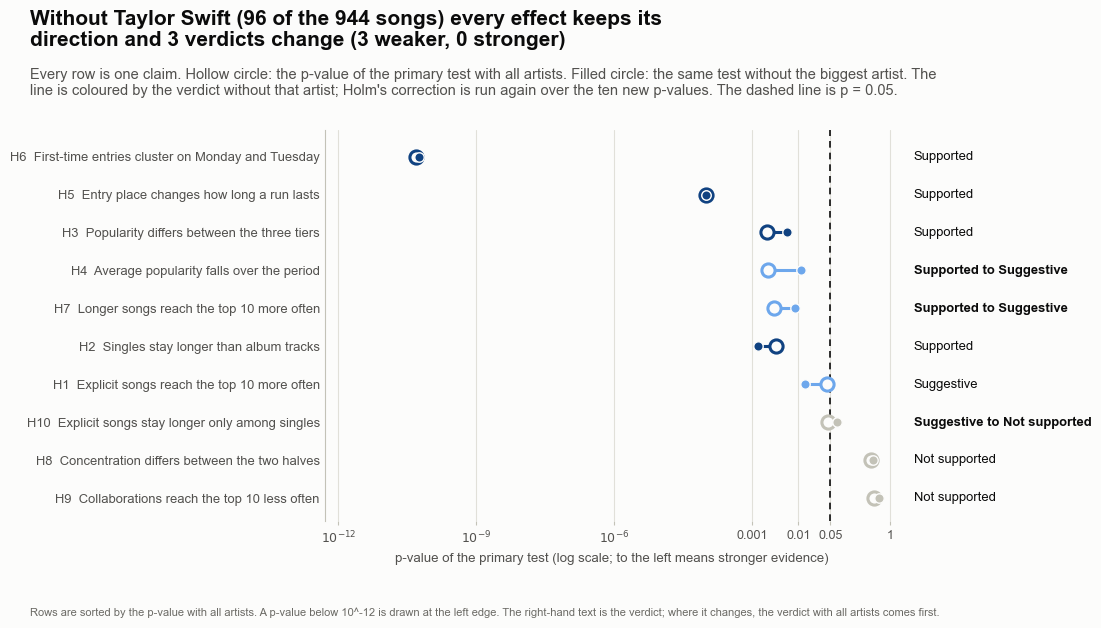

In [36]:
# Figure 17 - without the artist who has the most songs: how the evidence for every claim moves
order = list(family.sort_values("primary_p").index)
floor = 1e-12                                                                                    # p-values below this are drawn at the left edge, as in Figure 14

fig, ax = make_fig(11.8, 6.4, left=3.3, right=2.75, bottom=0.95, panel_titles=False,
                   title=f"Without {FACTS['rob_top_artist']} ({FACTS['rob_top_artist_songs']} of the {FACTS['songs']} songs) "
                         f"{'every effect keeps its direction' if FACTS['rob_wo_same_direction'] == 10 else str(10 - FACTS['rob_wo_same_direction']) + ' effects change direction'} "
                         f"and {FACTS['rob_wo_changed']} verdicts change ({FACTS['rob_wo_weaker']} weaker, {FACTS['rob_wo_stronger']} stronger)",
                   subtitle="Every row is one claim. Hollow circle: the p-value of the primary test with all artists. Filled circle: the same test without the biggest artist. The line is coloured by the verdict "
                            "without that artist; Holm's correction is run again over the ten new p-values. The dashed line is p = 0.05.",
                   note_text="Rows are sorted by the p-value with all artists. A p-value below 10^-12 is drawn at the left edge. The right-hand text is the verdict; where it changes, the verdict with all artists comes first.")
for row, hypothesis in enumerate(order):
    before, after = family.loc[hypothesis, "primary_p"], raw_without[hypothesis]
    colour = verdict_colours[verdict_without[hypothesis]]
    ax.hlines(row, max(min(before, after), floor), max(max(before, after), floor), color=colour, linewidth=2.2, zorder=2)
    ax.scatter([max(before, floor)], [row], s=90, facecolor=style.SURFACE, edgecolor=colour, linewidth=2.2, zorder=4)
    ax.scatter([max(after, floor)], [row], s=46, color=colour, edgecolor=style.SURFACE, linewidth=1.0, zorder=5)
    old, new = family.loc[hypothesis, "verdict"], verdict_without[hypothesis]
    ax.annotate(old if old == new else f"{old} to {new}", xy=(1.0, row), xycoords=("axes fraction", "data"), xytext=(10, 0), textcoords="offset points", va="center",
                fontsize=9.4, color=style.INK, fontweight="normal" if old == new else "bold", annotation_clip=False)
ax.axvline(ALPHA, color=style.INK, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xlim(floor * 0.5, 1.6)
ax.set_xticks([1e-12, 1e-9, 1e-6, 1e-3, 1e-2, 0.05, 1])
ax.set_xticklabels([r"$10^{-12}$", r"$10^{-9}$", r"$10^{-6}$", "0.001", "0.01", "0.05", "1"], fontsize=9)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{h}  {SHORT[h]}" for h in order], fontsize=9.4)
ax.set_ylim(len(order) - 0.4, -0.7)
ax.set_xlabel("p-value of the primary test (log scale; to the left means stronger evidence)")
style_axes(ax, grid="x", bottom_spine=False)
ax.tick_params(axis="y", length=0)
save_fig(fig, "p5_17_robustness_without_biggest_artist", FIG_DIR)
plt.show()

**What to notice**

- Nothing reverses. All 10 effects keep their direction without Taylor Swift, and 4 claims are still supported (H2, H3, H5, H6), against 6 with all artists. Three verdicts become weaker (H4, H7, H10) and none becomes stronger.
- H4 and H7 move from supported to suggestive, by a small margin. After the correction H4 goes from p = 0.017 to p = 0.056 (its raw p-value from p = 0.002 to p = 0.011) and H7 from p = 0.018 to p = 0.052 (raw p = 0.003 to p = 0.009), both just above 0.05. H10 goes from suggestive to not supported: its raw p-value rises from p = 0.045 to p = 0.069. H3 stays supported, but only just (p = 0.039 after the correction).
- Removing the artist does not only weaken claims. H1 is stronger without Taylor Swift: +8.7 points against +7.0, and p = 0.014 against p = 0.042. Its Holm p-value (p = 0.056) is still just above 0.05, so it stays suggestive. H2 is clearer too: x1.75 against x1.64 (p = 0.001 against p = 0.003). H5 and H6 hardly move.
- This is one stress test, not a proof. It shows that no claim reverses when the biggest catalogue is removed; it does not show that no other artist matters. H4, H7 and H10 deserve the most care in later phases, because each loses its verdict when that one artist is left out.

## Section 16 - Saving the results

The last cell writes down what the later phases need. Three small files go to the `reports` folder, and the charts are counted. Each file is written to a temporary name first and then renamed, so that a run stopped half-way never leaves a half-written file behind.

**What this code is.** The saving cell. It first builds the robustness table: one row per claim with the verdict, the estimate and the primary p-value on all the data, what the halves used, the estimate and the p-value in each half, whether both halves point the same way, and the estimate, the p-value, the Holm p-value and the verdict without the biggest artist. Then it saves three files in `reports/`: the hypothesis register (`p5_hypothesis_register.csv`, the table of Section 14), the robustness table (`p5_robustness.csv`) and the facts file (`p5_facts.json`, every number that the text of this notebook quotes). Last, it counts the picture files `p5_*.png` in `reports/figures/`.

**Why we need it.** Phase 6 and the later phases should read the verdicts from a file, not from this notebook's text, so nobody has to retype them. The facts file does a second job: the sentences of this notebook are written from it, so a sentence can not quote a number that the code did not produce. The count of 17 charts is a safeguard: if a figure cell was skipped, the notebook stops here and says so.

**What will happen.** The code builds the table, checks that it has ten different claims, writes the three files and prints four lines: the register with its ten hypotheses, the robustness table with its ten rows, the facts file with the number of stored numbers and names, and the folder of charts with its 17 files.

**Expected outcome.** Four lines of counts, and three new files in `reports/` next to the Phase 4 files.

**Motive.** Make the results of this phase an input that the next phases can read.

In [37]:
# Section 16 - save the files that the later phases read, and count the charts
robustness = pd.DataFrame({"hypothesis": claims_all, "verdict": [family.loc[h, "verdict"] for h in claims_all],
                           "estimate_all_data": [estimate_with(h) for h in claims_all], "primary_p_all_data": [float(family.loc[h, "primary_p"]) for h in claims_all],
                           "halves_use": ["not repeated (the claim compares the halves)" if h == "H8" else ("songs followed from first to last day" if h in ("H2", "H10") else "all rows of the half") for h in claims_all],
                           "first_half_estimate": [halves["first half"][h][0] if h in claims_checked else np.nan for h in claims_all],
                           "first_half_p": [halves["first half"][h][3] if h in claims_checked else np.nan for h in claims_all],
                           "second_half_estimate": [halves["second half"][h][0] if h in claims_checked else np.nan for h in claims_all],
                           "second_half_p": [halves["second half"][h][3] if h in claims_checked else np.nan for h in claims_all],
                           "same_direction_in_both_halves": [FACTS[f"rob_agree_{h.lower()}"] if h in claims_checked else None for h in claims_all],
                           "estimate_without_biggest_artist": [float(without[h][0]) for h in claims_all], "primary_p_without_biggest_artist": [float(raw_without[h]) for h in claims_all],
                           "holm_p_without_biggest_artist": [float(holm_without[h]) for h in claims_all], "verdict_without_biggest_artist": [verdict_without[h] for h in claims_all]})
assert len(robustness) == 10 and robustness["hypothesis"].is_unique, "one row per hypothesis"

facts_file = paths.reports_dir / "p5_facts.json"
register_file = paths.reports_dir / "p5_hypothesis_register.csv"
robustness_file = paths.reports_dir / "p5_robustness.csv"
REGISTER.save(register_file)
save_table(robustness, robustness_file)
FACTS.save(facts_file)

charts = sorted(FIG_DIR.glob("p5_*.png"))
print(f"register   : {register_file.name}  ({len(REGISTER)} hypotheses)")
print(f"robustness : {robustness_file.name}  ({len(robustness)} rows)")
print(f"facts      : {facts_file.name}  ({len(FACTS)} stored numbers and names)")
print(f"charts     : {len(charts)} files in {FIG_DIR.parent.name}/{FIG_DIR.name}/")
assert len(charts) == 17, "expected 17 charts (Figures 1 to 17); run the notebook from the first cell"

register   : p5_hypothesis_register.csv  (10 hypotheses)
robustness : p5_robustness.csv  (10 rows)
facts      : p5_facts.json  (829 stored numbers and names)
charts     : 17 files in reports/figures/


## What Phase 5 adds up to

**The result in one paragraph.** Phase 4 left ten claims. After allowing for related rows and for the fact that ten were tried at once, 6 are supported (H2, H3, H4, H5, H6, H7), 2 are suggestive (H1, H10) and 2 are not supported (H8, H9). Judged the quick way, with one test per claim and every row treated as independent, 8 would have looked significant. Of the 6 that survive, only H5 is a medium effect; the other five are small or negligible. Section 3 shows why the quick way can not be trusted: a test of nothing, run again and again with rows treated as independent, raised a false alarm in 52% of runs for popularity and 32% for days on the chart, where a fair test gives 5%. The artist-aware bootstrap stayed at 4.7% and 4.7%.

**What the supported claims say.**

- **H5, the clearest.** Where a chart run begins tells how long it will last. The rank correlation of entry place and run length is -0.36 (interval -0.43 to -0.28), and the pattern is there in each half of the period, among runs of the same artist and without the artist with the most songs. Part of it is arithmetic: a run that begins at place 45 has little room to fall. It describes the chart; it is not a lever.
- **H6.** 67% of the first-time entries fall on a Monday or Tuesday, against 29% if every weekday were alike. The share is 69% and 64% in the two halves and 64% without the biggest artist. These are the weekdays recorded in the file, whose calendar seems to run about a year ahead of real dates.
- **H2.** Singles stay about 1.6 times as long as album tracks (interval 1.18 to 2.27). The effect is small: a randomly chosen single outlasts a randomly chosen album track in about 59% of pairs.
- **H3.** The three tiers differ in popularity, with the Top 10 about 7 points above 11-20, but the tier explains only about 2% of the differences between songs, and the same songs are not more popular while they sit in the Top 10 (for songs seen in both tiers, Top 10 minus 21-50 is -3.4 points over all days and +1.0 after the first week of every run, p = 0.072). It tells which songs are there, not that the place makes them popular.
- **H4.** The average popularity of the chart fell by about 0.47 points per 100 days, 2.6 points over 555 days. It is among the thinnest of the supported claims: it is a step down between the halves (the daily average goes from 88.9 to 87.4) more than a steady slide, neither half shows it alone, and it turns suggestive without the biggest artist.
- **H7.** Longer songs reach the top 10 more often (+3.0 points per length band), but the link is negligible by the correlation (0.07), it is not visible among songs of the same artist (p = 0.44), and it turns suggestive without the biggest artist. It says which artists make which songs, not that a longer song does better.

**The two suggestive claims** are leads for new data, nothing more. H1: explicit songs reached the top 10 7.0 percentage points more often (interval 0.3 to 13.8), with a similar size in each half, but not clear in either half alone, and p = 0.17 after the correction. H10: explicit songs stay longer among singles than among album tracks, by a ratio of ratios of 1.76 (interval 1.01 to 3.05); on songs followed from start to end it is p = 0.11, and without the biggest artist it is p = 0.069.

**The two claims that are not supported** are not shown to be false. H8 had 19 months to work with and could only have found a difference of about 10 effective artists or more. For H9 the interval runs from -15.4 to +6.8 points, and equality within 5 points is not shown either. The honest reading is that these data can not tell.

**What this does not show.**

- *Nothing here is causal.* These are patterns in one chart, over one period, with no experiment. Where a claim could be read as advice (H5, H7, H3), the text says why it should not be.
- *The ten claims came from the same data.* They were chosen after looking at it in Phase 4, so the p-values say that chance alone is an unlikely explanation, not that another year of the chart would repeat the pattern. The correction counts ten claims, not the other patterns that could have been noticed.
- *The halves are not new data.* They check whether a claim is the work of one period, not whether it will hold next year.

**What Phase 6 takes from here.** Phase 6 builds models: which songs reach the top 10 (classification, with the confusion matrix and the ROC curve with its AUC), how long a song stays (regression), which songs and artists look alike (clustering) and how long a chart run lasts when unfinished runs are counted properly (survival analysis). Three things carry over from this notebook.

1. *Validate by artist, not by song.* Songs of one artist are alike (the intraclass correlation of the explicit flag is 0.57), so a random split of songs would let a model learn an artist from one song and be tested on another, and its scores would look better than they are. Phase 6 will hold out whole artists, and later weeks separately.
2. *Expect modest scores from song-level features.* The effects found here for explicit songs, collaborations and song length are small or negligible, which suggests that these features will add little to a model. The claims about entry place (H5) and release format (H2) point to more useful ones. This is an expectation that Phase 6 will test, not a result.
3. *Unfinished runs must be counted.* Runs that are still going on the last day of the file have not finished, and the survival models of Phase 6 are the proper tool for them, as the Kaplan-Meier curves were here.

The files that Phase 6 reads from this phase are `reports/p5_hypothesis_register.csv` (the ten verdicts with their effects and caveats) and `reports/p5_robustness.csv` (the two stress tests).